In [1]:
import rclpy
import torch
import numpy
import pandas
import matplotlib
import ipywidgets
from rosbags.rosbag2 import Reader

print("ROS 2:", rclpy.__file__)
print("PyTorch:", torch.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("ipywidgets:", ipywidgets.__version__)
print("Todas as bibliotecas estão funcionando!")

ROS 2: /opt/ros/jazzy/lib/python3.12/site-packages/rclpy/__init__.py
PyTorch: 2.15.0+cu132
NumPy: 1.26.4
Pandas: 2.1.4
ipywidgets: 8.1.9
Todas as bibliotecas estão funcionando!


In [2]:
import os
import ipywidgets as widgets
from IPython.display import display

print("ROS_DISTRO:", os.environ.get("ROS_DISTRO"))

velocidade = widgets.FloatSlider(
    value=0.3,
    min=0.0,
    max=1.0,
    step=0.05,
    description="Velocidade:"
)

display(velocidade)

ROS_DISTRO: jazzy


FloatSlider(value=0.3, description='Velocidade:', max=1.0, step=0.05)

In [3]:
import rclpy
from rclpy.node import Node

class HelloNode(Node):
    def __init__(self):
        super().__init__('hello_node')
        self.get_logger().info('Ola! Meu primeiro no ROS 2 esta funcionando!')

if not rclpy.ok():
    rclpy.init()

node = HelloNode()

node.destroy_node()
rclpy.shutdown()

[INFO] [1794325959.094779015] [hello_node]: Ola! Meu primeiro no ROS 2 esta funcionando!


In [4]:
import rclpy
from rclpy.node import Node
from std_msgs.msg import String
import threading
import time

class FalanteNode(Node):
    def __init__(self):
        super().__init__('falante_node')
        self.publisher = self.create_publisher(String, '/mensagem', 10)
        self.timer = self.create_timer(1.0, self.publicar)

    def publicar(self):
        msg = String()
        msg.data = 'Ola! Mensagem recebida pelo ROS 2!'
        self.publisher.publish(msg)
        self.get_logger().info('Mensagem publicada')

class OuvidorNode(Node):
    def __init__(self):
        super().__init__('ouvidor_node')
        self.subscription = self.create_subscription(
            String,
            '/mensagem',
            self.receber,
            10
        )

    def receber(self, msg):
        self.get_logger().info(f'Recebido: {msg.data}')

if not rclpy.ok():
    rclpy.init()

falante = FalanteNode()
ouvidor = OuvidorNode()

executor = rclpy.executors.SingleThreadedExecutor()
executor.add_node(falante)
executor.add_node(ouvidor)

thread = threading.Thread(target=executor.spin, daemon=True)
thread.start()

time.sleep(5)

executor.shutdown()
falante.destroy_node()
ouvidor.destroy_node()
rclpy.shutdown()

print("Teste de Publisher e Subscriber concluido!")

[INFO] [1794326016.712997455] [falante_node]: Mensagem publicada
[INFO] [1794326016.725560693] [ouvidor_node]: Recebido: Ola! Mensagem recebida pelo ROS 2!
[INFO] [1794326017.699796847] [falante_node]: Mensagem publicada
[INFO] [1794326017.702717272] [ouvidor_node]: Recebido: Ola! Mensagem recebida pelo ROS 2!
[INFO] [1794326018.699154541] [falante_node]: Mensagem publicada
[INFO] [1794326018.702061414] [ouvidor_node]: Recebido: Ola! Mensagem recebida pelo ROS 2!
[INFO] [1794326019.702409126] [falante_node]: Mensagem publicada
[INFO] [1794326019.705158539] [ouvidor_node]: Recebido: Ola! Mensagem recebida pelo ROS 2!


Teste de Publisher e Subscriber concluido!


[INFO] [1794326020.708362039] [falante_node]: Mensagem publicada


In [5]:
import rclpy
from rclpy.node import Node
from std_msgs.msg import Float32

class VelocidadeNode(Node):
    def __init__(self):
        super().__init__('velocidade_node')

        self.declare_parameter('velocidade', 0.3)

        self.publisher = self.create_publisher(
            Float32,
            '/velocidade',
            10
        )

        self.timer = self.create_timer(1.0, self.publicar)

    def publicar(self):
        velocidade = self.get_parameter('velocidade').value

        msg = Float32()
        msg.data = float(velocidade)

        self.publisher.publish(msg)

        self.get_logger().info(
            f'Velocidade publicada: {velocidade} m/s'
        )

if not rclpy.ok():
    rclpy.init()

node = VelocidadeNode()

executor = rclpy.executors.SingleThreadedExecutor()
executor.add_node(node)

import threading
import time

thread = threading.Thread(target=executor.spin, daemon=True)
thread.start()

time.sleep(4)

executor.shutdown()
node.destroy_node()
rclpy.shutdown()

[INFO] [1794326119.243094428] [velocidade_node]: Velocidade publicada: 0.3 m/s
[INFO] [1794326120.246166661] [velocidade_node]: Velocidade publicada: 0.3 m/s
[INFO] [1794326121.245947782] [velocidade_node]: Velocidade publicada: 0.3 m/s
[INFO] [1794326122.258446802] [velocidade_node]: Velocidade publicada: 0.3 m/s


In [6]:
if rclpy.ok():
    node.destroy_node()
    rclpy.shutdown()

rclpy.init()

node = VelocidadeNode()

node.set_parameters([
    rclpy.parameter.Parameter(
        'velocidade',
        rclpy.Parameter.Type.DOUBLE,
        0.7
    )
])

print(
    'Novo valor do parâmetro:',
    node.get_parameter('velocidade').value
)

node.destroy_node()
rclpy.shutdown()

Novo valor do parâmetro: 0.7


In [7]:
import rclpy
import time
import math
import threading

from rclpy.node import Node
from geometry_msgs.msg import Twist


class QuadradoNode(Node):

    def __init__(self):
        super().__init__('quadrado_node')

        self.publisher = self.create_publisher(
            Twist,
            '/cmd_vel',
            10
        )

        self.vel_linear = 0.3
        self.vel_angular = 0.785

        self.tempo_reto = 2.0 / self.vel_linear
        self.tempo_giro = (math.pi / 2) / self.vel_angular

        self.etapa = 0
        self.inicio_etapa = time.monotonic()
        self.concluido = False

        self.timer = self.create_timer(0.1, self.executar)

        self.get_logger().info('Iniciando percurso quadrado!')

    def executar(self):

        if self.concluido:
            return

        msg = Twist()

        if self.etapa >= 8:
            self.publisher.publish(msg)
            self.concluido = True
            self.timer.cancel()

            self.get_logger().info(
                'Quadrado concluido! Robo parado.'
            )
            return

        tempo_decorrido = time.monotonic() - self.inicio_etapa

        if self.etapa % 2 == 0:

            msg.linear.x = self.vel_linear
            duracao = self.tempo_reto

        else:

            msg.angular.z = self.vel_angular
            duracao = self.tempo_giro

        self.publisher.publish(msg)

        if tempo_decorrido >= duracao:

            if self.etapa % 2 == 0:
                self.get_logger().info(
                    f'Lado {(self.etapa // 2) + 1} concluido.'
                )
            else:
                self.get_logger().info('Giro de 90 graus concluido.')

            self.etapa += 1
            self.inicio_etapa = time.monotonic()


if not rclpy.ok():
    rclpy.init()

node = QuadradoNode()

executor = rclpy.executors.SingleThreadedExecutor()
executor.add_node(node)

thread = threading.Thread(
    target=executor.spin,
    daemon=True
)
thread.start()

while not node.concluido:
    time.sleep(0.1)

executor.shutdown()
thread.join()

node.destroy_node()
rclpy.shutdown()

print('Teste do QuadradoNode finalizado.')

[INFO] [1794326196.576001707] [quadrado_node]: Iniciando percurso quadrado!
[INFO] [1794326203.282621852] [quadrado_node]: Lado 1 concluido.
[INFO] [1794326205.378299036] [quadrado_node]: Giro de 90 graus concluido.
[INFO] [1794326212.081730392] [quadrado_node]: Lado 2 concluido.
[INFO] [1794326214.182156242] [quadrado_node]: Giro de 90 graus concluido.
[INFO] [1794326220.878203649] [quadrado_node]: Lado 3 concluido.
[INFO] [1794326222.981836660] [quadrado_node]: Giro de 90 graus concluido.
[INFO] [1794326229.678193502] [quadrado_node]: Lado 4 concluido.


Teste do QuadradoNode finalizado.


[INFO] [1794326231.781830499] [quadrado_node]: Giro de 90 graus concluido.
[INFO] [1794326231.881472376] [quadrado_node]: Quadrado concluido! Robo parado.


In [8]:
import ipywidgets as widgets
from IPython.display import display

# Controle deslizante de velocidade
velocidade_slider = widgets.FloatSlider(
    value=0.3,
    min=0.0,
    max=1.0,
    step=0.1,
    description='Velocidade:',
    continuous_update=True
)

# Campo para exibir o valor
saida = widgets.Label(value='Velocidade selecionada: 0.3 m/s')

# Atualiza o texto quando o slider muda
def atualizar_velocidade(change):
    saida.value = f'Velocidade selecionada: {change["new"]:.1f} m/s'

velocidade_slider.observe(atualizar_velocidade, names='value')

# Exibe o painel
display(velocidade_slider, saida)

FloatSlider(value=0.3, description='Velocidade:', max=1.0)

Label(value='Velocidade selecionada: 0.3 m/s')

In [9]:
import ipywidgets as widgets
from IPython.display import display

# Controle de velocidade linear
vel_linear = widgets.FloatSlider(
    value=0.3,
    min=0.0,
    max=1.0,
    step=0.1,
    description='Linear:',
    readout_format='.1f'
)

# Controle de velocidade angular
vel_angular = widgets.FloatSlider(
    value=0.785,
    min=0.0,
    max=2.0,
    step=0.05,
    description='Angular:',
    readout_format='.2f'
)

# Botões de controle
botao_iniciar = widgets.Button(
    description='INICIAR ROBÔ',
    button_style='success'
)

botao_parar = widgets.Button(
    description='PARAR ROBÔ',
    button_style='danger'
)

status = widgets.Label(value='Status: ROBÔ PARADO')

# Funções dos botões
def iniciar(b):
    status.value = 'Status: ROBÔ EM MOVIMENTO'

def parar(b):
    status.value = 'Status: ROBÔ PARADO'

botao_iniciar.on_click(iniciar)
botao_parar.on_click(parar)

# Exibição do painel
display(
    widgets.VBox([
        widgets.HTML('<h2>Painel de Controle do Robô</h2>'),
        vel_linear,
        vel_angular,
        widgets.HBox([botao_iniciar, botao_parar]),
        status
    ])
)

In [10]:
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import random
import time

# Dados simulados de velocidade
tempos = []
velocidades = []

for i in range(20):
    tempos.append(i)
    velocidades.append(random.uniform(0.1, 0.8))

# Criando o gráfico
plt.figure(figsize=(9, 4))

plt.plot(
    tempos,
    velocidades,
    marker='o',
    label='Velocidade do robô'
)

plt.title('Monitoramento de Velocidade')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Velocidade (m/s)')
plt.grid(True)
plt.legend()

plt.show()

AttributeError: 'RcParams' object has no attribute '_get'

In [11]:
%pip install --upgrade matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 35.1 MB/s  0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 15.6 MB/s  0:00:00
  Attempting uninstall: kiwisolver
    Found existing installation: kiwisolver 0.0.0
    Not uninstalling kiwisolver at /usr/lib/python3/dist-packages, outside environment /home/ivan/ros2_ws/.venv
    Can't uninstall 'kiwisolver'. No files were found to uninstall.
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.6.3
    Not uninstalling matplotlib at /usr/lib/python3/dist-packages, outside environment /home/ivan/ros2_ws/.venv
    Can't uninstall 'matplotlib'. No files were found to uninstall.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [matplotlib] 1/2 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


Versão: 3.11.2


/home/ivan/ros2_ws/.venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


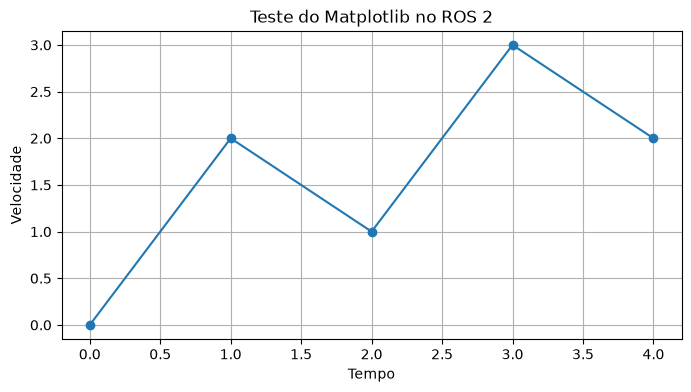

In [1]:
import matplotlib
import matplotlib.pyplot as plt

print("Versão:", matplotlib.__version__)

plt.figure(figsize=(8, 4))
plt.plot([0, 1, 2, 3, 4], [0, 2, 1, 3, 2], marker='o')
plt.title("Teste do Matplotlib no ROS 2")
plt.xlabel("Tempo")
plt.ylabel("Velocidade")
plt.grid(True)
plt.show()

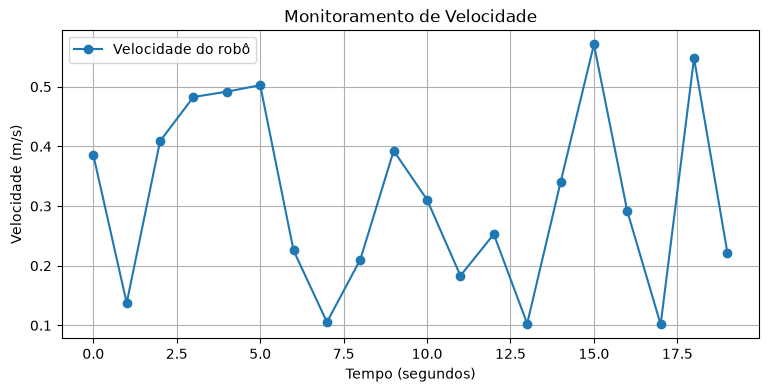

In [2]:
import matplotlib.pyplot as plt
import random

tempos = []
velocidades = []

for i in range(20):
    tempos.append(i)
    velocidades.append(random.uniform(0.1, 0.8))

plt.figure(figsize=(9, 4))

plt.plot(
    tempos,
    velocidades,
    marker='o',
    label='Velocidade do robô'
)

plt.title('Monitoramento de Velocidade')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Velocidade (m/s)')
plt.grid(True)
plt.legend()

plt.show()

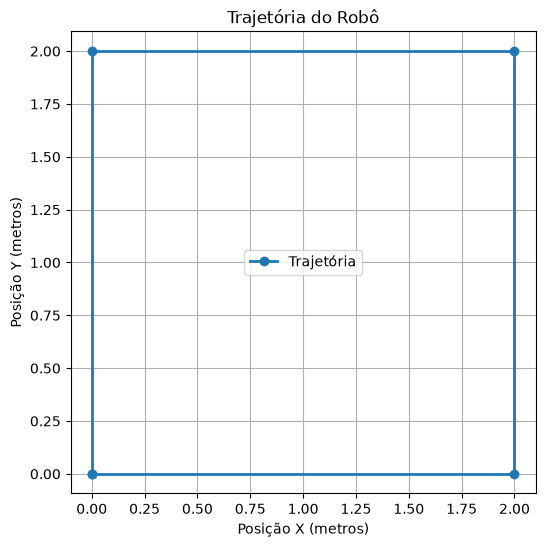

In [3]:
import matplotlib.pyplot as plt

# Coordenadas simuladas de um percurso quadrado
x = [0, 2, 2, 0, 0]
y = [0, 0, 2, 2, 0]

plt.figure(figsize=(6, 6))

plt.plot(x, y, marker='o', linewidth=2, label='Trajetória')

plt.title('Trajetória do Robô')
plt.xlabel('Posição X (metros)')
plt.ylabel('Posição Y (metros)')

plt.xlim(-0.5, 2.5)
plt.ylim(-0.5, 2.5)

plt.grid(True)
plt.axis('equal')
plt.legend()

plt.show()

In [4]:
import rclpy

print("ROS 2 conectado:", rclpy.ok())
print("Distribuição:", __import__('os').environ.get('ROS_DISTRO'))

ROS 2 conectado: False
Distribuição: jazzy


In [5]:
import rclpy
from rclpy.node import Node

# Inicializa o ROS 2
if not rclpy.ok():
    rclpy.init()

# Cria um nó ROS 2 dentro do Jupyter
node = Node('jupyter_monitor_node')

node.get_logger().info('Jupyter conectado ao ROS 2 com sucesso!')

print("ROS 2 conectado:", rclpy.ok())
print("Nome do nó:", node.get_name())

ROS 2 conectado: True
Nome do nó: jupyter_monitor_node


[INFO] [1794327337.446822115] [jupyter_monitor_node]: Jupyter conectado ao ROS 2 com sucesso!


In [6]:
node.get_logger().info('Verificando nós ativos...')
print("Nós ativos:", node.get_node_names())

Nós ativos: ['jupyter_monitor_node']


[INFO] [1794327365.637059188] [jupyter_monitor_node]: Verificando nós ativos...


In [7]:
from std_msgs.msg import String

# Cria um Publisher
publisher = node.create_publisher(
    String,
    '/jupyter_status',
    10
)

# Prepara a mensagem
mensagem = String()
mensagem.data = 'O Jupyter está comunicando com o ROS 2!'

# Publica
publisher.publish(mensagem)

print("Mensagem publicada:", mensagem.data)

Mensagem publicada: O Jupyter está comunicando com o ROS 2!


In [8]:
from std_msgs.msg import String

# Lista para armazenar as mensagens recebidas
mensagens_recebidas = []

# Função chamada quando uma mensagem chegar
def receber_mensagem(msg):
    mensagens_recebidas.append(msg.data)
    print("Mensagem recebida:", msg.data)

# Cria o Subscriber
subscriber = node.create_subscription(
    String,
    '/jupyter_status',
    receber_mensagem,
    10
)

print("Subscriber aguardando mensagens...")

Subscriber aguardando mensagens...


In [9]:
# Processa as mensagens pendentes do ROS 2
rclpy.spin_once(node, timeout_sec=1.0)

# Verifica se alguma mensagem foi recebida
print("Total de mensagens recebidas:", len(mensagens_recebidas))

Total de mensagens recebidas: 0


In [10]:
mensagem = String()
mensagem.data = 'O Jupyter está comunicando com o ROS 2!'

publisher.publish(mensagem)

print("Nova mensagem publicada!")

Nova mensagem publicada!


In [11]:
rclpy.spin_once(node, timeout_sec=2.0)

print("Total de mensagens recebidas:", len(mensagens_recebidas))

Mensagem recebida: O Jupyter está comunicando com o ROS 2!
Total de mensagens recebidas: 1


In [12]:
import threading
import time

def monitorar_ros():
    while rclpy.ok():
        rclpy.spin_once(node, timeout_sec=0.1)
        time.sleep(0.1)

thread_ros = threading.Thread(
    target=monitorar_ros,
    daemon=True
)

thread_ros.start()

print("Monitoramento contínuo iniciado!")

Monitoramento contínuo iniciado!


In [13]:
import time

for i in range(5):
    mensagem = String()
    mensagem.data = f'Mensagem número {i + 1}'
    
    publisher.publish(mensagem)
    print(f'Publicada: Mensagem número {i + 1}')
    
    time.sleep(1)

Publicada: Mensagem número 1
Mensagem recebida: Mensagem número 1
Publicada: Mensagem número 2
Mensagem recebida: Mensagem número 2
Publicada: Mensagem número 3
Mensagem recebida: Mensagem número 3
Publicada: Mensagem número 4Mensagem recebida: Mensagem número 4

Publicada: Mensagem número 5Mensagem recebida: Mensagem número 5



In [14]:
import ipywidgets as widgets
from IPython.display import display
from std_msgs.msg import Float32

# Cria o Publisher ROS 2
velocidade_publisher = node.create_publisher(
    Float32,
    '/velocidade',
    10
)

# Cria o controle deslizante
velocidade_slider = widgets.FloatSlider(
    value=0.3,
    min=0.0,
    max=1.0,
    step=0.1,
    description='Velocidade:',
    readout_format='.1f'
)

status_velocidade = widgets.Label(
    value='Velocidade publicada: 0.3 m/s'
)

# Publica o valor sempre que o slider mudar
def publicar_velocidade(change):
    mensagem = Float32()
    mensagem.data = change['new']

    velocidade_publisher.publish(mensagem)

    status_velocidade.value = (
        f'Velocidade publicada: {change["new"]:.1f} m/s'
    )

velocidade_slider.observe(
    publicar_velocidade,
    names='value'
)

display(velocidade_slider, status_velocidade)

FloatSlider(value=0.3, description='Velocidade:', max=1.0, readout_format='.1f')

Label(value='Velocidade publicada: 0.3 m/s')

In [16]:
from std_msgs.msg import Float32

velocidades_recebidas = []

def receber_velocidade(msg):
    velocidades_recebidas.append(msg.data)
    print(f'ROS 2 recebeu: {msg.data:.1f} m/s')

subscriber_velocidade = node.create_subscription(
    Float32,
    '/velocidade',
    receber_velocidade,
    10
)

print("Monitor de velocidade iniciado!")

Monitor de velocidade iniciado!


In [17]:
print("Velocidades recebidas pelo ROS 2:")
print(velocidades_recebidas)

print("Total recebido:", len(velocidades_recebidas))

Velocidades recebidas pelo ROS 2:
[]
Total recebido: 0


In [18]:
print("Tópicos disponíveis:")
print(node.get_topic_names_and_types())

print("\nPublishers em /velocidade:")
print(node.count_publishers('/velocidade'))

print("\nSubscribers em /velocidade:")
print(node.count_subscribers('/velocidade'))

print("\nThread de monitoramento ativa:")
print(thread_ros.is_alive())

Tópicos disponíveis:
[('/jupyter_status', ['std_msgs/msg/String']), ('/parameter_events', ['rcl_interfaces/msg/ParameterEvent']), ('/rosout', ['rcl_interfaces/msg/Log']), ('/velocidade', ['std_msgs/msg/Float32'])]

Publishers em /velocidade:
1

Subscribers em /velocidade:
2

Thread de monitoramento ativa:
True


In [19]:
# Força uma mudança no slider
velocidade_slider.value = 0.4

# Aguarda o processamento
import time
time.sleep(2)

# Verifica o recebimento
print("Mensagens recebidas:", velocidades_recebidas)

ROS 2 recebeu: 0.4 m/s
ROS 2 recebeu: 0.4 m/s
Mensagens recebidas: [0.4000000059604645, 0.4000000059604645]


In [20]:
print("Inscrições existentes no nó:")

for sub in node._subscriptions:
    print("Tópico:", sub.topic_name)

Inscrições existentes no nó:
Tópico: /jupyter_status
Tópico: /velocidade
Tópico: /velocidade


In [21]:
# Remove o primeiro Subscriber de velocidade
node.destroy_subscription(subscriber_velocidade)

print("Subscriber duplicado removido!")
print("Subscribers em /velocidade:",
      node.count_subscribers('/velocidade'))

Subscriber duplicado removido!
Subscribers em /velocidade: 2


In [22]:
import time

time.sleep(3)

print("Inscrições locais do nó:")

for sub in node._subscriptions:
    print("Tópico:", sub.topic_name)

print("\nTotal de subscribers em /velocidade:",
      node.count_subscribers('/velocidade'))

Inscrições locais do nó:
Tópico: /jupyter_status
Tópico: /velocidade

Total de subscribers em /velocidade: 1


In [23]:
for valor in [0.2, 0.6, 0.9]:
    velocidade_slider.value = valor
    time.sleep(1)

print("\nHistórico recebido:")
print([round(v, 1) for v in velocidades_recebidas])

ROS 2 recebeu: 0.2 m/s
ROS 2 recebeu: 0.6 m/s
ROS 2 recebeu: 0.9 m/s

Histórico recebido:
[0.4, 0.4, 0.2, 0.6, 0.9]


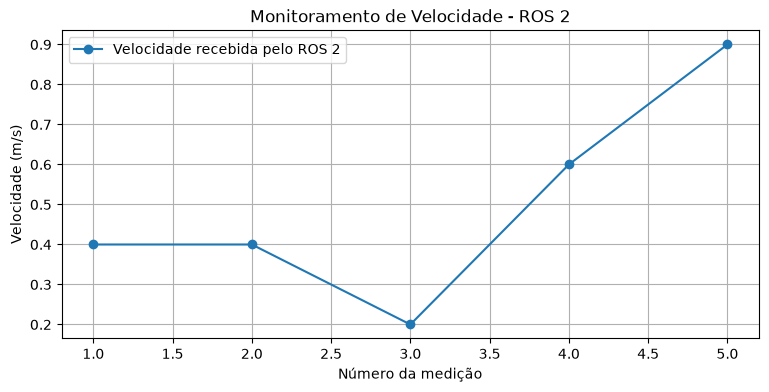

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))

plt.plot(
    range(1, len(velocidades_recebidas) + 1),
    velocidades_recebidas,
    marker='o',
    label='Velocidade recebida pelo ROS 2'
)

plt.title('Monitoramento de Velocidade - ROS 2')
plt.xlabel('Número da medição')
plt.ylabel('Velocidade (m/s)')
plt.grid(True)
plt.legend()
plt.show()

In [25]:
plt.savefig(
    'grafico_velocidade_ros2.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [26]:
import os

print("Pasta onde o arquivo foi salvo:")
print(os.getcwd())

print("\nArquivo criado:")
print(os.path.exists('grafico_velocidade_ros2.png'))

Pasta onde o arquivo foi salvo:
/home/ivan/ros2_ws

Arquivo criado:
True


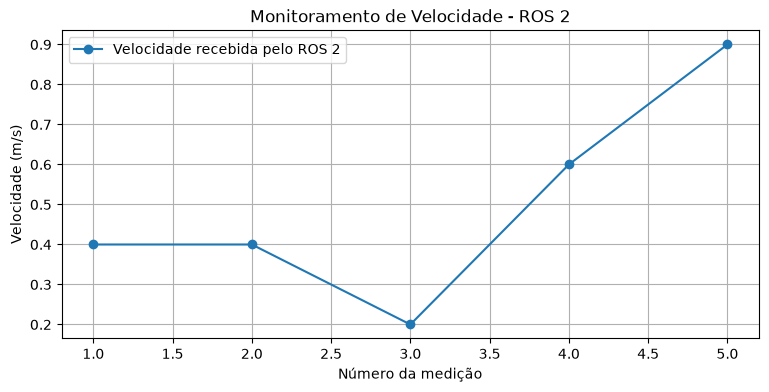

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    range(1, len(velocidades_recebidas) + 1),
    velocidades_recebidas,
    marker='o',
    label='Velocidade recebida pelo ROS 2'
)

ax.set_title('Monitoramento de Velocidade - ROS 2')
ax.set_xlabel('Número da medição')
ax.set_ylabel('Velocidade (m/s)')
ax.grid(True)
ax.legend()

fig.savefig('grafico_velocidade_ros2.png', dpi=300, bbox_inches='tight')

plt.show()

In [28]:
from std_msgs.msg import Float32

distancias_recebidas = []

def receber_distancia(msg):
    distancias_recebidas.append(msg.data)
    print(f'Distância do obstáculo: {msg.data:.2f} metros')

subscriber_distancia = node.create_subscription(
    Float32,
    '/distancia_obstaculo',
    receber_distancia,
    10
)

distancia_publisher = node.create_publisher(
    Float32,
    '/distancia_obstaculo',
    10
)

print('Monitor de distância iniciado!')

Monitor de distância iniciado!


In [29]:
import time

for distancia in [3.0, 2.5, 1.8, 1.2, 0.7, 0.3]:
    mensagem = Float32()
    mensagem.data = distancia

    distancia_publisher.publish(mensagem)

    print(f'Enviando distância: {distancia:.2f} m')
    time.sleep(1)

Enviando distância: 3.00 m
Distância do obstáculo: 3.00 metros
Enviando distância: 2.50 m
Distância do obstáculo: 2.50 metros
Enviando distância: 1.80 mDistância do obstáculo: 1.80 metros

Enviando distância: 1.20 m
Distância do obstáculo: 1.20 metros
Enviando distância: 0.70 mDistância do obstáculo: 0.70 metros

Enviando distância: 0.30 m
Distância do obstáculo: 0.30 metros


In [30]:
def verificar_distancia(distancia):
    if distancia < 0.5:
        return '🚨 PERIGO! Obstáculo muito próximo!'
    elif distancia <= 1.0:
        return '⚠️ ATENÇÃO! Reduza a velocidade!'
    else:
        return '✅ Distância segura'

for distancia in distancias_recebidas:
    print(f'{distancia:.2f} m -> {verificar_distancia(distancia)}')

3.00 m -> ✅ Distância segura
2.50 m -> ✅ Distância segura
1.80 m -> ✅ Distância segura
1.20 m -> ✅ Distância segura
0.70 m -> ⚠️ ATENÇÃO! Reduza a velocidade!
0.30 m -> 🚨 PERIGO! Obstáculo muito próximo!


In [31]:
import ipywidgets as widgets
from IPython.display import display

distancia_atual = widgets.FloatSlider(
    value=3.0,
    min=0,
    max=3,
    step=0.1,
    description='Distância:',
    readout_format='.1f',
    disabled=True
)

status_obstaculo = widgets.HTML(
    value='<h3 style="color:green">✅ Distância segura</h3>'
)

def atualizar_painel(distancia):
    distancia_atual.value = distancia

    if distancia < 0.5:
        status_obstaculo.value = '<h3 style="color:red">🚨 PERIGO! Obstáculo muito próximo!</h3>'
    elif distancia <= 1.0:
        status_obstaculo.value = '<h3 style="color:orange">⚠️ ATENÇÃO! Reduza a velocidade!</h3>'
    else:
        status_obstaculo.value = '<h3 style="color:green">✅ Distância segura</h3>'

display(distancia_atual, status_obstaculo)

FloatSlider(value=3.0, description='Distância:', disabled=True, max=3.0, readout_format='.1f')

HTML(value='<h3 style="color:green">✅ Distância segura</h3>')

In [32]:
def receber_distancia(msg):
    distancia = msg.data
    distancias_recebidas.append(distancia)

    atualizar_painel(distancia)

    print(f'Distância recebida: {distancia:.2f} m')

subscriber_distancia = node.create_subscription(
    Float32,
    '/distancia_obstaculo',
    receber_distancia,
    10
)

print('Painel conectado ao ROS 2!')

Painel conectado ao ROS 2!


In [33]:
import time

for distancia in [3.0, 2.0, 1.2, 0.8, 0.4, 0.2]:
    mensagem = Float32()
    mensagem.data = distancia

    distancia_publisher.publish(mensagem)

    print(f'Enviando: {distancia:.2f} m')
    time.sleep(1)

Enviando: 3.00 m
Distância do obstáculo: 3.00 metros
Distância recebida: 3.00 m
Enviando: 2.00 m
Distância do obstáculo: 2.00 metros
Distância recebida: 2.00 m
Enviando: 1.20 m
Distância do obstáculo: 1.20 metros
Distância recebida: 1.20 m
Enviando: 0.80 m
Distância do obstáculo: 0.80 metros
Distância recebida: 0.80 m
Enviando: 0.40 m
Distância do obstáculo: 0.40 metros
Distância recebida: 0.40 m
Enviando: 0.20 m
Distância do obstáculo: 0.20 metros
Distância recebida: 0.20 m


In [34]:
Enviando: 3.00 m
Distância do obstáculo: 3.00 metros
Distância recebida: 3.00 m
Enviando: 2.00 m
Distância do obstáculo: 2.00 metros
Distância recebida: 2.00 m
Enviando: 1.20 m
Distância do obstáculo: 1.20 metros
Distância recebida: 1.20 m
Enviando: 0.80 m
Distância do obstáculo: 0.80 metros
Distância recebida: 0.80 m
Enviando: 0.40 m
Distância do obstáculo: 0.40 metros
Distância recebida: 0.40 m
Enviando: 0.20 m
Distância do obstáculo: 0.20 metros
Distância recebida: 0.20 m

SyntaxError: invalid syntax (1976846022.py, line 1)

In [35]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Gerar dados simulados
np.random.seed(42)

N = 500

vel_x = np.random.uniform(-0.5, 0.5, N)
vel_y = np.random.uniform(-0.1, 0.1, N)
dist = np.random.uniform(0.1, 3.0, N)
ang_vel = np.random.uniform(-1.0, 1.0, N)

# Classificar os dados
labels = (dist < 0.5).astype(float)

# Organizar entradas e saídas
X = np.column_stack([vel_x, vel_y, dist, ang_vel]).astype(np.float32)
y = labels.astype(np.float32).reshape(-1, 1)

print("Dataset criado!")
print("Total de amostras:", N)
print("Formato das entradas:", X.shape)
print("Formato das classificações:", y.shape)
print("Obstáculos detectados:", int(labels.sum()))

Dataset criado!
Total de amostras: 500
Formato das entradas: (500, 4)
Formato das classificações: (500, 1)
Obstáculos detectados: 72


In [36]:
# Normalizar os dados
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)

X_norm = (X - X_mean) / (X_std + 1e-8)

# Separar treino e validação
split = int(0.8 * N)

X_tr = torch.FloatTensor(X_norm[:split])
X_vl = torch.FloatTensor(X_norm[split:])

y_tr = torch.FloatTensor(y[:split])
y_vl = torch.FloatTensor(y[split:])

print("Dados preparados!")
print("Amostras para treinamento:", len(X_tr))
print("Amostras para validação:", len(X_vl))
print("Formato dos dados de treino:", X_tr.shape)

Dados preparados!
Amostras para treinamento: 400
Amostras para validação: 100
Formato dos dados de treino: torch.Size([400, 4])


In [37]:
class ObstacleNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)


model = ObstacleNet()

print(model)
print("\nRede neural ObstacleNet criada com sucesso!")

ObstacleNet(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Linear(in_features=16, out_features=1, bias=True)
    (6): Sigmoid()
  )
)

Rede neural ObstacleNet criada com sucesso!


In [38]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

criterion = nn.BCELoss()

EPOCHS = 60

losses_tr = []
losses_vl = []

print("Treinamento configurado!")
print("Otimizador: Adam")
print("Taxa de aprendizagem: 0.001")
print("Função de perda: BCELoss")
print("Épocas:", EPOCHS)

Treinamento configurado!
Otimizador: Adam
Taxa de aprendizagem: 0.001
Função de perda: BCELoss
Épocas: 60


In [39]:
for epoch in range(EPOCHS):

    model.train()

    optimizer.zero_grad()

    pred = model(X_tr)

    loss = criterion(pred, y_tr)

    loss.backward()

    optimizer.step()

    model.eval()

    with torch.no_grad():
        vl_loss = criterion(model(X_vl), y_vl).item()

    losses_tr.append(loss.item())
    losses_vl.append(vl_loss)

    if (epoch + 1) % 15 == 0:
        print(
            f'Epoch {epoch + 1:3d}/{EPOCHS} | '
            f'loss={loss.item():.4f} | '
            f'val={vl_loss:.4f}'
        )

print("\nTreinamento concluído!")

Epoch  15/60 | loss=0.6172 | val=0.6091
Epoch  30/60 | loss=0.5594 | val=0.5526
Epoch  45/60 | loss=0.4969 | val=0.5009
Epoch  60/60 | loss=0.4468 | val=0.4496

Treinamento concluído!


In [40]:
model.eval()

with torch.no_grad():
    preds = (model(X_vl) > 0.5).float()

    acc = (preds == y_vl).float().mean().item()

print(f'Acurácia na validação: {acc * 100:.1f}%')

Acurácia na validação: 85.0%


In [41]:
import os
import json

os.makedirs('models', exist_ok=True)

# Salvar os pesos da rede neural
torch.save(
    model.state_dict(),
    'models/obstacle_net_v1.pt'
)

# Salvar os parâmetros de normalização
with open('models/scaler_config.json', 'w') as f:
    json.dump({
        'mean': X_mean.tolist(),
        'std': X_std.tolist()
    }, f)

print("Modelo salvo com sucesso!")
print("Arquivo: models/obstacle_net_v1.pt")
print("Scaler: models/scaler_config.json")

Modelo salvo com sucesso!
Arquivo: models/obstacle_net_v1.pt
Scaler: models/scaler_config.json


In [42]:
# Carregar configuração de normalização
with open('models/scaler_config.json', 'r') as f:
    cfg = json.load(f)

mean_tensor = torch.tensor(cfg['mean'], dtype=torch.float32)
std_tensor = torch.tensor(cfg['std'], dtype=torch.float32)

# Criar uma nova rede e carregar os pesos salvos
model_inf = ObstacleNet()

model_inf.load_state_dict(
    torch.load(
        'models/obstacle_net_v1.pt',
        map_location='cpu',
        weights_only=True
    )
)

model_inf.eval()

print("Modelo carregado com sucesso!")
print("Pronto para realizar inferências!")

Modelo carregado com sucesso!
Pronto para realizar inferências!


In [43]:
# Cinco situações para testar a IA
amostras_teste = torch.tensor([
    [0.3, 0.0, 2.5, 0.0],
    [0.3, 0.0, 0.3, 0.0],
    [0.2, 0.1, 0.8, 0.2],
    [0.4, 0.0, 0.2, 0.5],
    [0.1, 0.0, 1.8, 0.0]
], dtype=torch.float32)

# Aplicar a mesma normalização do treinamento
amostras_norm = (amostras_teste - mean_tensor) / (std_tensor + 1e-8)

# Fazer previsões
with torch.no_grad():
    probabilidades = model_inf(amostras_norm)

# Mostrar resultados
for i, prob in enumerate(probabilidades):
    resultado = "OBSTÁCULO DETECTADO!" if prob.item() > 0.5 else "CAMINHO LIVRE"

    print(
        f"Situação {i+1}: "
        f"Probabilidade = {prob.item():.2%} -> {resultado}"
    )

Situação 1: Probabilidade = 29.24% -> CAMINHO LIVRE
Situação 2: Probabilidade = 29.22% -> CAMINHO LIVRE
Situação 3: Probabilidade = 21.77% -> CAMINHO LIVRE
Situação 4: Probabilidade = 24.98% -> CAMINHO LIVRE
Situação 5: Probabilidade = 33.50% -> CAMINHO LIVRE


In [44]:
from sklearn.metrics import confusion_matrix, classification_report

y_real = y_vl.numpy().flatten()
y_previsto = preds.numpy().flatten()

print("Matriz de confusão:")
print(confusion_matrix(y_real, y_previsto))

print("\nRelatório de classificação:")
print(classification_report(
    y_real,
    y_previsto,
    target_names=['Caminho livre', 'Obstáculo']
))

ModuleNotFoundError: No module named 'sklearn'

In [45]:
# Converter resultados para listas
y_real = y_vl.int().flatten()
y_previsto = preds.int().flatten()

# Calcular os resultados
VP = ((y_real == 1) & (y_previsto == 1)).sum().item()
VN = ((y_real == 0) & (y_previsto == 0)).sum().item()
FP = ((y_real == 0) & (y_previsto == 1)).sum().item()
FN = ((y_real == 1) & (y_previsto == 0)).sum().item()

print("Matriz de confusão:")
print("                 Previsto")
print("              Livre  Obstáculo")
print(f"Real Livre     {VN:4d}    {FP:4d}")
print(f"Real Obstáculo {FN:4d}    {VP:4d}")

print("\nDetalhamento:")
print("Verdadeiros positivos:", VP)
print("Verdadeiros negativos:", VN)
print("Falsos positivos:", FP)
print("Falsos negativos:", FN)

Matriz de confusão:
                 Previsto
              Livre  Obstáculo
Real Livre       85       0
Real Obstáculo   15       0

Detalhamento:
Verdadeiros positivos: 0
Verdadeiros negativos: 85
Falsos positivos: 0
Falsos negativos: 15


In [46]:
# Calcular o peso das classes
positivos = y_tr.sum()
negativos = len(y_tr) - positivos

peso_positivo = negativos / positivos

print("Exemplos de obstáculos:", int(positivos.item()))
print("Exemplos de caminhos livres:", int(negativos.item()))
print("Peso dos obstáculos:", peso_positivo.item())

# Configurar uma função de perda com maior peso para obstáculos
criterion = nn.BCELoss(
    weight=torch.where(
        y_tr == 1,
        peso_positivo,
        torch.tensor(1.0)
    )
)

print("\nFunção de perda ajustada!")

Exemplos de obstáculos: 57
Exemplos de caminhos livres: 343
Peso dos obstáculos: 6.017543792724609

Função de perda ajustada!


In [47]:
# Criar uma rede nova
model = ObstacleNet()

# Configurar novamente o otimizador
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Reiniciar históricos
losses_tr = []
losses_vl = []

# Treinar novamente
for epoch in range(EPOCHS):

    model.train()
    optimizer.zero_grad()

    pred = model(X_tr)
    loss = criterion(pred, y_tr)

    loss.backward()
    optimizer.step()

    model.eval()

    with torch.no_grad():
        vl_loss = criterion(model(X_vl), y_vl).item()

    losses_tr.append(loss.item())
    losses_vl.append(vl_loss)

    if (epoch + 1) % 15 == 0:
        print(
            f'Epoch {epoch + 1:3d}/{EPOCHS} | '
            f'loss={loss.item():.4f} | '
            f'val={vl_loss:.4f}'
        )

print("\nNovo treinamento concluído!")

RuntimeError: Attempting to broadcast a dimension of length 400 at -2! Mismatching argument at index 1 had torch.Size([400, 1]); but expected shape should be broadcastable to [100, 1]

In [48]:
# Função de perda ponderada para treinamento
criterion_train = nn.BCELoss(
    weight=torch.where(
        y_tr == 1,
        peso_positivo,
        torch.tensor(1.0)
    )
)

# Função de perda normal para validação
criterion_val = nn.BCELoss()

print("Funções de perda corrigidas!")
print("Treinamento: ponderado")
print("Validação: normal")

Funções de perda corrigidas!
Treinamento: ponderado
Validação: normal


In [49]:
model = ObstacleNet()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

losses_tr = []
losses_vl = []

for epoch in range(EPOCHS):

    model.train()
    optimizer.zero_grad()

    pred = model(X_tr)
    loss = criterion_train(pred, y_tr)

    loss.backward()
    optimizer.step()

    model.eval()

    with torch.no_grad():
        vl_loss = criterion_val(model(X_vl), y_vl).item()

    losses_tr.append(loss.item())
    losses_vl.append(vl_loss)

    if (epoch + 1) % 15 == 0:
        print(
            f'Epoch {epoch + 1:3d}/{EPOCHS} | '
            f'loss={loss.item():.4f} | '
            f'val={vl_loss:.4f}'
        )

print("\nNovo treinamento concluído!")

Epoch  15/60 | loss=1.0789 | val=0.6083
Epoch  30/60 | loss=0.9823 | val=0.5905
Epoch  45/60 | loss=0.8821 | val=0.5465
Epoch  60/60 | loss=0.7500 | val=0.4809

Novo treinamento concluído!


In [50]:
model.eval()

with torch.no_grad():
    probabilidades_vl = model(X_vl)
    preds = (probabilidades_vl > 0.5).float()

acc = (preds == y_vl).float().mean().item()

y_real = y_vl.int().flatten()
y_previsto = preds.int().flatten()

VP = ((y_real == 1) & (y_previsto == 1)).sum().item()
VN = ((y_real == 0) & (y_previsto == 0)).sum().item()
FP = ((y_real == 0) & (y_previsto == 1)).sum().item()
FN = ((y_real == 1) & (y_previsto == 0)).sum().item()

print(f"Acurácia: {acc * 100:.1f}%")

print("\nMatriz de confusão:")
print("                 Previsto")
print("              Livre  Obstáculo")
print(f"Real Livre     {VN:4d}    {FP:4d}")
print(f"Real Obstáculo {FN:4d}    {VP:4d}")

print("\nObstáculos detectados:", VP)
print("Obstáculos não detectados:", FN)

Acurácia: 84.0%

Matriz de confusão:
                 Previsto
              Livre  Obstáculo
Real Livre       69      16
Real Obstáculo    0      15

Obstáculos detectados: 15
Obstáculos não detectados: 0


In [51]:
# Salvar o modelo atualizado
torch.save(
    model.state_dict(),
    'models/obstacle_net_v1.pt'
)

# Salvar novamente a normalização
with open('models/scaler_config.json', 'w') as f:
    json.dump({
        'mean': X_mean.tolist(),
        'std': X_std.tolist()
    }, f)

print("Modelo atualizado e salvo!")
print("Acurácia: 84%")
print("Detecção de obstáculos: 100% na validação")

Modelo atualizado e salvo!
Acurácia: 84%
Detecção de obstáculos: 100% na validação


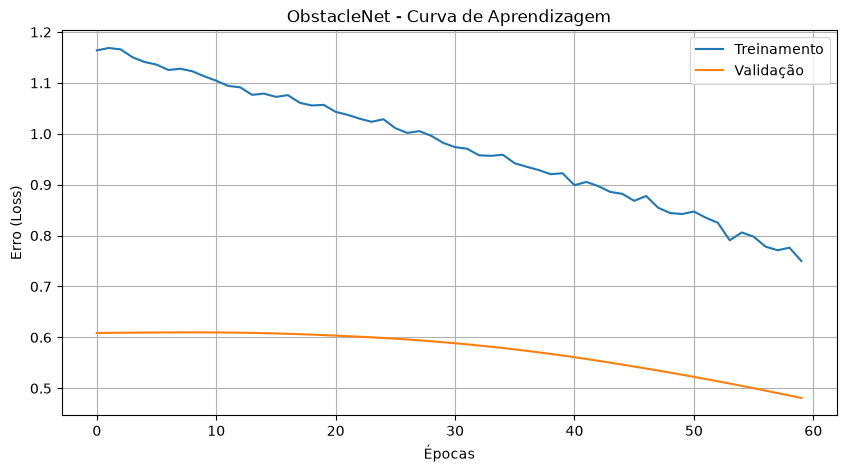

Gráfico salvo em models/curva_aprendizagem.png


In [52]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(losses_tr, label='Treinamento')
ax.plot(losses_vl, label='Validação')

ax.set_title('ObstacleNet - Curva de Aprendizagem')
ax.set_xlabel('Épocas')
ax.set_ylabel('Erro (Loss)')

ax.grid(True)
ax.legend()

fig.savefig(
    'models/curva_aprendizagem.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Gráfico salvo em models/curva_aprendizagem.png")

In [53]:
# Preparar as amostras de teste
amostras_teste = torch.tensor([
    [0.3, 0.0, 2.5, 0.0],
    [0.3, 0.0, 0.3, 0.0],
    [0.2, 0.1, 0.8, 0.2],
    [0.4, 0.0, 0.2, 0.5],
    [0.1, 0.0, 1.8, 0.0]
], dtype=torch.float32)

# Normalizar
amostras_norm = (
    amostras_teste - mean_tensor
) / (std_tensor + 1e-8)

# Inferência
model.eval()

with torch.no_grad():
    probabilidades = model(amostras_norm)

# Exibir resultados
for i, prob in enumerate(probabilidades):
    resultado = (
        "OBSTÁCULO DETECTADO!"
        if prob.item() > 0.5
        else "CAMINHO LIVRE"
    )

    print(
        f"Situação {i+1}: "
        f"Probabilidade = {prob.item():.2%} -> {resultado}"
    )

Situação 1: Probabilidade = 23.44% -> CAMINHO LIVRE
Situação 2: Probabilidade = 70.97% -> OBSTÁCULO DETECTADO!
Situação 3: Probabilidade = 68.43% -> OBSTÁCULO DETECTADO!
Situação 4: Probabilidade = 70.22% -> OBSTÁCULO DETECTADO!
Situação 5: Probabilidade = 35.49% -> CAMINHO LIVRE


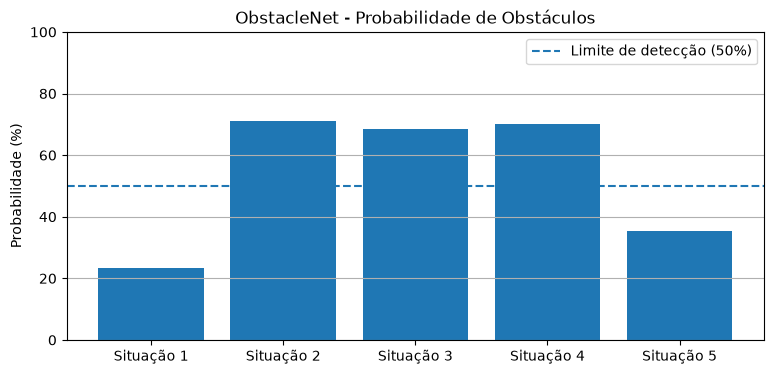

Gráfico salvo com sucesso!


In [54]:
fig, ax = plt.subplots(figsize=(9, 4))

valores = probabilidades.numpy().flatten() * 100

ax.bar(
    ['Situação 1', 'Situação 2', 'Situação 3',
     'Situação 4', 'Situação 5'],
    valores
)

ax.axhline(
    y=50,
    linestyle='--',
    label='Limite de detecção (50%)'
)

ax.set_title('ObstacleNet - Probabilidade de Obstáculos')
ax.set_ylabel('Probabilidade (%)')
ax.set_ylim(0, 100)
ax.legend()
ax.grid(axis='y')

fig.savefig(
    'models/probabilidade_obstaculos.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Gráfico salvo com sucesso!")

In [55]:
import os

arquivos = [
    'models/obstacle_net_v1.pt',
    'models/scaler_config.json',
    'models/curva_aprendizagem.png',
    'models/probabilidade_obstaculos.png'
]

for arquivo in arquivos:
    print(
        arquivo,
        "->",
        "ENCONTRADO" if os.path.exists(arquivo) else "NÃO ENCONTRADO"
    )

models/obstacle_net_v1.pt -> ENCONTRADO
models/scaler_config.json -> ENCONTRADO
models/curva_aprendizagem.png -> ENCONTRADO
models/probabilidade_obstaculos.png -> ENCONTRADO


In [56]:
import torch
import json

# Recuperar a arquitetura da rede neural
model_inf = ObstacleNet()

# Carregar os pesos treinados
model_inf.load_state_dict(
    torch.load('models/obstacle_net_v1.pt', map_location='cpu', weights_only=True)
)

# Colocar o modelo em modo de inferência
model_inf.eval()

# Carregar configuração de normalização
with open('models/scaler_config.json', 'r') as arquivo:
    scaler = json.load(arquivo)

mean_tensor = torch.tensor(scaler['mean'], dtype=torch.float32)
std_tensor = torch.tensor(scaler['std'], dtype=torch.float32)

print("Modelo carregado com sucesso!")
print("Modo de operação:", "Inferência" if not model_inf.training else "Treinamento")
print("Normalização recuperada!")

Modelo carregado com sucesso!
Modo de operação: Inferência
Normalização recuperada!


In [57]:
def detectar_obstaculo(vel_x, vel_y, dist, ang_vel):

    # Preparar os dados de entrada
    entrada = torch.tensor(
        [[vel_x, vel_y, dist, ang_vel]],
        dtype=torch.float32
    )

    # Normalizar os dados
    entrada_norm = (entrada - mean_tensor) / (std_tensor + 1e-8)

    # Executar a inferência
    with torch.no_grad():
        probabilidade = model_inf(entrada_norm).item()

    # Classificar o resultado
    obstaculo = probabilidade >= 0.5

    return obstaculo, probabilidade

In [58]:
livre = detectar_obstaculo(0.3, 0.0, 2.5, 0.0)
perigo = detectar_obstaculo(0.3, 0.0, 0.3, 0.0)

print(f"Caminho livre: {livre[1]*100:.2f}%")
print(f"Obstáculo próximo: {perigo[1]*100:.2f}%")

print("\nClassificação:")
print("Caminho livre:", "OBSTÁCULO" if livre[0] else "LIVRE")
print("Obstáculo próximo:", "OBSTÁCULO" if perigo[0] else "LIVRE")

Caminho livre: 23.44%
Obstáculo próximo: 70.97%

Classificação:
Caminho livre: LIVRE
Obstáculo próximo: OBSTÁCULO


In [59]:
from std_msgs.msg import Bool, Float32

class ObstacleNetNode(Node):

    def __init__(self):
        super().__init__('obstacle_net_node')

        self.publisher = self.create_publisher(
            Bool,
            '/obstaculo',
            10
        )

        self.subscription = self.create_subscription(
            Float32,
            '/distancia_obstaculo',
            self.callback_distancia,
            10
        )

        self.get_logger().info(
            'ObstacleNetNode iniciado!'
        )

    def callback_distancia(self, msg):

        dist = float(msg.data)

        obstaculo, probabilidade = detectar_obstaculo(
            0.3,
            0.0,
            dist,
            0.0
        )

        resposta = Bool()
        resposta.data = obstaculo

        self.publisher.publish(resposta)

        self.get_logger().info(
            f'Distância: {dist:.2f} m | '
            f'Probabilidade: {probabilidade*100:.2f}% | '
            f'Obstáculo: {obstaculo}'
        )


print("Classe ObstacleNetNode criada com sucesso!")

Classe ObstacleNetNode criada com sucesso!


In [60]:
obstacle_node = ObstacleNetNode()

print("ObstacleNetNode conectado ao ROS 2!")
print("Assinando tópico: /distancia_obstaculo")
print("Publicando tópico: /obstaculo")

ObstacleNetNode conectado ao ROS 2!
Assinando tópico: /distancia_obstaculo
Publicando tópico: /obstaculo


[INFO] [1794331554.800669950] [obstacle_net_node]: ObstacleNetNode iniciado!


In [61]:
from std_msgs.msg import Bool

obstaculos_detectados = []

def callback_obstaculo(msg):
    obstaculos_detectados.append(msg.data)

    resultado = "OBSTÁCULO DETECTADO" if msg.data else "CAMINHO LIVRE"

    print(f"Resultado recebido: {resultado}")

sub_obstaculo = node.create_subscription(
    Bool,
    '/obstaculo',
    callback_obstaculo,
    10
)

print("Monitoramento do tópico /obstaculo iniciado!")

Monitoramento do tópico /obstaculo iniciado!


In [62]:
import time
from std_msgs.msg import Float32

distancias_teste = [3.0, 2.0, 1.2, 0.8, 0.4, 0.2]

for distancia in distancias_teste:
    msg = Float32()
    msg.data = float(distancia)

    pub_distancia.publish(msg)

    print(f"\nDistância enviada: {distancia:.2f} m")

    time.sleep(1)

print("\nTeste de integração finalizado!")

NameError: name 'pub_distancia' is not defined

In [63]:
from std_msgs.msg import Float32

pub_distancia_teste = node.create_publisher(
    Float32,
    '/distancia_obstaculo',
    10
)

print("Publisher de distâncias criado com sucesso!")

Publisher de distâncias criado com sucesso!


In [64]:
import time
from std_msgs.msg import Float32

distancias_teste = [3.0, 2.0, 1.2, 0.8, 0.4, 0.2]

for distancia in distancias_teste:
    msg = Float32()
    msg.data = float(distancia)

    pub_distancia_teste.publish(msg)

    print(f"\nDistância enviada: {distancia:.2f} m")

    time.sleep(1)

print("\nTeste de integração finalizado!")


Distância enviada: 3.00 m
Distância do obstáculo: 3.00 metros
Distância recebida: 3.00 m

Distância enviada: 2.00 m
Distância do obstáculo: 2.00 metros
Distância recebida: 2.00 m

Distância enviada: 1.20 m
Distância do obstáculo: 1.20 metros
Distância recebida: 1.20 m

Distância enviada: 0.80 m
Distância do obstáculo: 0.80 metros
Distância recebida: 0.80 m

Distância enviada: 0.40 m
Distância do obstáculo: 0.40 metros
Distância recebida: 0.40 m

Distância enviada: 0.20 m
Distância do obstáculo: 0.20 metros
Distância recebida: 0.20 m

Teste de integração finalizado!


In [65]:
import threading
import time
import rclpy

def processar_obstaclenet():
    while rclpy.ok():
        rclpy.spin_once(obstacle_node, timeout_sec=0.1)
        time.sleep(0.01)

thread_obstacle = threading.Thread(
    target=processar_obstaclenet,
    daemon=True
)

thread_obstacle.start()

print("Processamento da ObstacleNet ativado!")

Processamento da ObstacleNet ativado!


[INFO] [1794331674.941573128] [obstacle_net_node]: Distância: 3.00 m | Probabilidade: 20.57% | Obstáculo: False
[INFO] [1794331674.955990429] [obstacle_net_node]: Distância: 2.00 m | Probabilidade: 28.21% | Obstáculo: False
[INFO] [1794331674.970282345] [obstacle_net_node]: Distância: 1.20 m | Probabilidade: 47.96% | Obstáculo: False
[INFO] [1794331674.984915840] [obstacle_net_node]: Distância: 0.80 m | Probabilidade: 60.14% | Obstáculo: True
[INFO] [1794331675.000229519] [obstacle_net_node]: Distância: 0.40 m | Probabilidade: 69.17% | Obstáculo: True
[INFO] [1794331675.016812583] [obstacle_net_node]: Distância: 0.20 m | Probabilidade: 72.66% | Obstáculo: True
Exception in thread Thread-6 (monitorar_ros):
Traceback (most recent call last):
  File "/usr/lib/python3.12/threading.py", line 1073, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.12/threading.py", line 1010, in run
    self._target(*self._args, **self._kwargs)
  File "/tmp/ipykernel_47446/3684772131.py", line 6, i

Resultado recebido: CAMINHO LIVRE


In [66]:
from rclpy.executors import SingleThreadedExecutor
import threading

executor_monitor = SingleThreadedExecutor()
executor_monitor.add_node(node)

thread_monitor = threading.Thread(
    target=executor_monitor.spin,
    daemon=True
)

thread_monitor.start()

print("Executor do monitor iniciado separadamente!")

Resultado recebido: CAMINHO LIVRE
Resultado recebido: CAMINHO LIVRE
Resultado recebido: OBSTÁCULO DETECTADO
Resultado recebido: OBSTÁCULO DETECTADO
Resultado recebido: OBSTÁCULO DETECTADO
Executor do monitor iniciado separadamente!


In [67]:
print("PatrolNode definido:", 'PatrolNode' in globals())
print("ObstacleNetNode definido:", 'ObstacleNetNode' in globals())
print("Nó da IA ativo:", 'obstacle_node' in globals())
print("Histórico de detecções:", obstaculos_detectados)

PatrolNode definido: False
ObstacleNetNode definido: True
Nó da IA ativo: True
Histórico de detecções: [False, False, False, True, True, True]


In [68]:
import math
import time

from geometry_msgs.msg import Twist
from std_msgs.msg import Bool

In [69]:
class PatrolNode(Node):

    VEL_LINEAR = 0.3
    VEL_ANGULAR = 0.785
    DIST_LADO = 2.0
    N_LADOS = 4

    def __init__(self):
        super().__init__('patrol_node')

        self.publisher = self.create_publisher(
            Twist,
            '/cmd_vel',
            10
        )

        self.subscription = self.create_subscription(
            Bool,
            '/obstaculo',
            self.callback_obstaculo,
            10
        )

        self.estado = 'MOVING_FORWARD'
        self.estado_anterior = 'MOVING_FORWARD'

        self.lado_atual = 0
        self.angulo_giro = 0.0

        self.ultimo_tempo = time.monotonic()
        self.historico = []

        self.timer = self.create_timer(0.1, self.executar)

        self.get_logger().info('PatrolNode iniciado!')

    def publicar_velocidade(self, linear, angular):
        msg = Twist()
        msg.linear.x = float(linear)
        msg.angular.z = float(angular)
        self.publisher.publish(msg)

    def callback_obstaculo(self, msg):

        if msg.data and self.estado not in ['AVOIDING', 'DONE']:
            self.estado_anterior = self.estado
            self.estado = 'AVOIDING'
            self.publicar_velocidade(0.0, 0.0)
            self.get_logger().warning('Obstáculo! Robô parado.')

        elif not msg.data and self.estado == 'AVOIDING':
            self.estado = self.estado_anterior
            self.ultimo_tempo = time.monotonic()
            self.get_logger().info('Caminho livre! Retomando patrulha.')

    def executar(self):

        agora = time.monotonic()
        dt = agora - self.ultimo_tempo
        self.ultimo_tempo = agora

        if self.estado == 'MOVING_FORWARD':

            self.publicar_velocidade(self.VEL_LINEAR, 0.0)

            self.distancia_percorrida = getattr(
                self, 'distancia_percorrida', 0.0
            ) + self.VEL_LINEAR * dt

            if self.distancia_percorrida >= self.DIST_LADO:
                self.estado = 'TURNING'
                self.angulo_giro = 0.0

        elif self.estado == 'TURNING':

            self.publicar_velocidade(0.0, self.VEL_ANGULAR)

            self.angulo_giro += self.VEL_ANGULAR * dt

            if self.angulo_giro >= math.pi / 2:
                self.lado_atual += 1
                self.distancia_percorrida = 0.0

                if self.lado_atual >= self.N_LADOS:
                    self.estado = 'DONE'
                    self.publicar_velocidade(0.0, 0.0)
                    self.get_logger().info('Patrulha concluída!')

                else:
                    self.estado = 'MOVING_FORWARD'

        elif self.estado in ['AVOIDING', 'DONE']:
            self.publicar_velocidade(0.0, 0.0)

        self.historico.append({
            'tempo': agora,
            'estado': self.estado,
            'lado': self.lado_atual
        })

In [70]:
print("PatrolNode criado:", 'PatrolNode' in globals())


PatrolNode criado: True


In [71]:
patrol = PatrolNode()

print("PatrolNode iniciado com sucesso!")
print("Estado inicial:", patrol.estado)
print("Lado atual:", patrol.lado_atual)
print("Assinando tópico: /obstaculo")
print("Publicando tópico: /cmd_vel")

PatrolNode iniciado com sucesso!
Estado inicial: MOVING_FORWARD
Lado atual: 0
Assinando tópico: /obstaculo
Publicando tópico: /cmd_vel


[INFO] [1794332026.287126712] [patrol_node]: PatrolNode iniciado!


In [72]:
from rclpy.executors import SingleThreadedExecutor
import threading

executor_patrol = SingleThreadedExecutor()
executor_patrol.add_node(patrol)

thread_patrol = threading.Thread(
    target=executor_patrol.spin,
    daemon=True
)

thread_patrol.start()

print("Executor do PatrolNode iniciado!")
print("Máquina de estados em execução:", patrol.estado)

Executor do PatrolNode iniciado!
Máquina de estados em execução: TURNING


[INFO] [1794332083.789279001] [patrol_node]: Patrulha concluída!


In [73]:
print("Estado atual:", patrol.estado)
print("Lado atual:", patrol.lado_atual)
print("Distância percorrida:", getattr(patrol, 'distancia_percorrida', 0))
print("Executor ativo:", thread_patrol.is_alive())

Estado atual: DONE
Lado atual: 4
Distância percorrida: 0.0
Executor ativo: True


In [74]:
patrol.estado = 'MOVING_FORWARD'
patrol.estado_anterior = 'MOVING_FORWARD'

patrol.lado_atual = 0
patrol.distancia_percorrida = 0.0
patrol.angulo_giro = 0.0

patrol.ultimo_tempo = time.monotonic()

patrol.historico = []

print("Patrulha reiniciada!")
print("Estado:", patrol.estado)
print("Lado:", patrol.lado_atual)
print("Distância:", patrol.distancia_percorrida)

Patrulha reiniciada!
Estado: MOVING_FORWARD
Lado: 0
Distância: 0.0


In [75]:
from std_msgs.msg import Bool

msg_obstaculo = Bool()
msg_obstaculo.data = True

obstacle_node.publisher.publish(msg_obstaculo)

time.sleep(0.5)

print("Estado do robô:", patrol.estado)
print("Lado atual:", patrol.lado_atual)

Resultado recebido: OBSTÁCULO DETECTADO


[WARN] [1794332971.225606756] [patrol_node]: Obstáculo! Robô parado.


Estado do robô: AVOIDING
Lado atual: 2


In [76]:
msg_obstaculo = Bool()
msg_obstaculo.data = False

obstacle_node.publisher.publish(msg_obstaculo)

time.sleep(0.5)

print("Estado do robô:", patrol.estado)
print("Lado atual:", patrol.lado_atual)

Resultado recebido: CAMINHO LIVRE


[INFO] [1794333007.090779946] [patrol_node]: Caminho livre! Retomando patrulha.


Estado do robô: MOVING_FORWARD
Lado atual: 2


[INFO] [1794333020.189324902] [patrol_node]: Patrulha concluída!


In [77]:
from collections import Counter

estados = [item['estado'] for item in patrol.historico]

print("Total de registros:", len(estados))
print("\nDistribuição dos estados:")

for estado, quantidade in Counter(estados).items():
    print(f"{estado}: {quantidade}")

print("\nÚltimos registros:")
for registro in patrol.historico[-5:]:
    print(registro)

Total de registros: 859

Distribuição dos estados:
MOVING_FORWARD: 267
TURNING: 84
AVOIDING: 359
DONE: 149

Últimos registros:
{'tempo': 12174.444538462, 'estado': 'DONE', 'lado': 4}
{'tempo': 12174.544806958, 'estado': 'DONE', 'lado': 4}
{'tempo': 12174.644884668, 'estado': 'DONE', 'lado': 4}
{'tempo': 12174.744825146, 'estado': 'DONE', 'lado': 4}
{'tempo': 12174.844874376, 'estado': 'DONE', 'lado': 4}


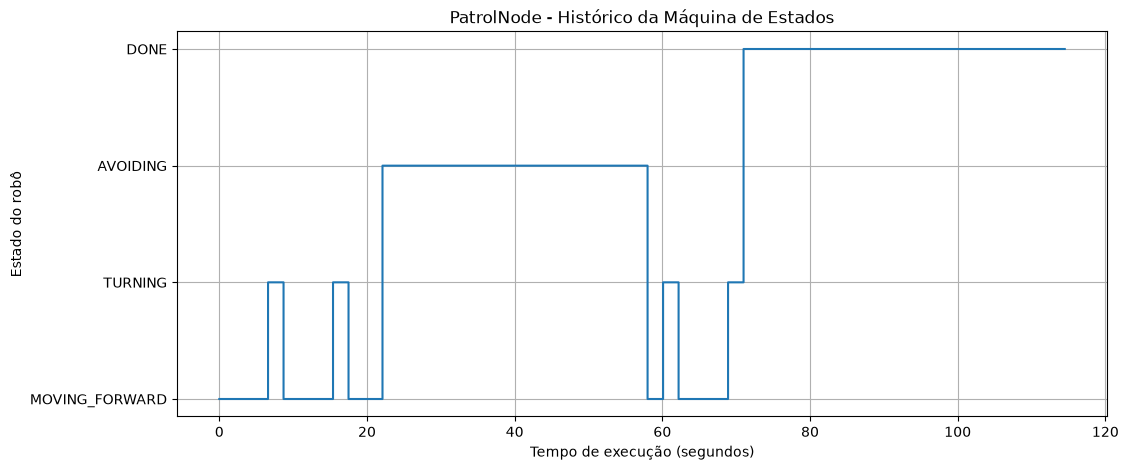

Gráfico salvo em models/historico_patrol.png


In [78]:
import matplotlib.pyplot as plt

tempos = [
    item['tempo'] - patrol.historico[0]['tempo']
    for item in patrol.historico
]

estados = [
    item['estado']
    for item in patrol.historico
]

codigos = {
    'MOVING_FORWARD': 1,
    'TURNING': 2,
    'AVOIDING': 3,
    'DONE': 4
}

valores = [codigos[estado] for estado in estados]

fig, ax = plt.subplots(figsize=(12, 5))

ax.step(tempos, valores, where='post')

ax.set_yticks([1, 2, 3, 4])
ax.set_yticklabels([
    'MOVING_FORWARD',
    'TURNING',
    'AVOIDING',
    'DONE'
])

ax.set_xlabel('Tempo de execução (segundos)')
ax.set_ylabel('Estado do robô')
ax.set_title('PatrolNode - Histórico da Máquina de Estados')
ax.grid(True)

fig.savefig(
    'models/historico_patrol.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Gráfico salvo em models/historico_patrol.png")

In [79]:
import json
from collections import Counter

resumo = {
    'total_registros': len(patrol.historico),
    'estados': dict(Counter(
        item['estado'] for item in patrol.historico
    )),
    'lados_concluidos': patrol.lado_atual,
    'estado_final': patrol.estado,
    'deteccoes_obstaculos': len(obstaculos_detectados),
    'obstaculos_detectados': sum(obstaculos_detectados)
}

with open('models/resumo_patrol.json', 'w') as arquivo:
    json.dump(resumo, arquivo, indent=4)

print(json.dumps(resumo, indent=4))
print("\nResumo salvo com sucesso!")

{
    "total_registros": 1439,
    "estados": {
        "MOVING_FORWARD": 267,
        "TURNING": 84,
        "AVOIDING": 359,
        "DONE": 729
    },
    "lados_concluidos": 4,
    "estado_final": "DONE",
    "deteccoes_obstaculos": 8,
    "obstaculos_detectados": 4
}

Resumo salvo com sucesso!


In [80]:
import os

print("ARQUIVOS DA PASTA MODELS:\n")

for arquivo in sorted(os.listdir('models')):
    caminho = os.path.join('models', arquivo)

    if os.path.isfile(caminho):
        tamanho = os.path.getsize(caminho) / 1024
        print(f"{arquivo} - {tamanho:.1f} KB")

ARQUIVOS DA PASTA MODELS:

curva_aprendizagem.png - 130.3 KB
historico_patrol.png - 92.4 KB
obstacle_net_v1.pt - 5.9 KB
probabilidade_obstaculos.png - 85.9 KB
resumo_patrol.json - 0.3 KB
scaler_config.json - 0.2 KB


In [81]:
from geometry_msgs.msg import Twist
import time

msg_teste = Twist()
msg_teste.linear.x = 0.3
msg_teste.angular.z = 0.0

pub_teste = node.create_publisher(Twist, '/cmd_vel', 10)

for _ in range(20):
    pub_teste.publish(msg_teste)
    time.sleep(0.1)

msg_teste.linear.x = 0.0
pub_teste.publish(msg_teste)

print("Comando de teste enviado!")

Comando de teste enviado!


In [82]:
from geometry_msgs.msg import Twist
import time

# Publisher conectado diretamente ao robô no Gazebo
pub_teste = node.create_publisher(
    Twist,
    '/model/patrol_vehicle/cmd_vel',
    10
)

# Criar comando de movimento
msg_teste = Twist()
msg_teste.linear.x = 0.3
msg_teste.angular.z = 0.0

# Movimentar durante 3 segundos
for _ in range(30):
    pub_teste.publish(msg_teste)
    time.sleep(0.1)

# Parar o robô
msg_teste.linear.x = 0.0
msg_teste.angular.z = 0.0

for _ in range(5):
    pub_teste.publish(msg_teste)
    time.sleep(0.1)

print("Teste de movimento concluído!")

Teste de movimento concluído!


In [83]:
print('Publisher do PatrolNode:')
print(patrol.publisher.topic_name)

print('\nEstado atual:')
print(patrol.estado)

print('\nLado atual:')
print(patrol.lado_atual)

Publisher do PatrolNode:
/cmd_vel

Estado atual:
DONE

Lado atual:
4


In [84]:
# Remover o publisher antigo
patrol.destroy_publisher(patrol.publisher)

# Criar publisher conectado diretamente ao Gazebo
patrol.publisher = patrol.create_publisher(
    Twist,
    '/model/patrol_vehicle/cmd_vel',
    10
)

print('Novo tópico:', patrol.publisher.topic_name)

Novo tópico: /model/patrol_vehicle/cmd_vel


In [85]:
# Reiniciar estado da patrulha
patrol.estado = 'MOVING_FORWARD'
patrol.estado_anterior = 'MOVING_FORWARD'

# Zerar progresso
patrol.lado_atual = 0
patrol.distancia_percorrida = 0.0
patrol.angulo_giro = 0.0

# Reiniciar temporização
patrol.ultimo_tempo = time.monotonic()

# Limpar histórico anterior
patrol.historico = []

# Garantir que o robô comece parado
patrol.publicar_velocidade(0.0, 0.0)

print('Patrulha reiniciada!')
print('Estado:', patrol.estado)
print('Lado:', patrol.lado_atual)

Patrulha reiniciada!
Estado: MOVING_FORWARD
Lado: 0


[INFO] [1794335373.598310655] [patrol_node]: Patrulha concluída!


In [86]:
from collections import Counter

print('Estado atual:', patrol.estado)
print('Lado atual:', patrol.lado_atual)

print('\nDistribuição dos estados:')
print(Counter(item['estado'] for item in patrol.historico))

print('\nTotal de registros:', len(patrol.historico))

Estado atual: DONE
Lado atual: 4

Distribuição dos estados:
Counter({'DONE': 588, 'MOVING_FORWARD': 268, 'TURNING': 84})

Total de registros: 940


In [87]:
import subprocess

resultado = subprocess.run(
    ['gz', 'topic', '-i', '-t', '/model/patrol_vehicle/odometry'],
    capture_output=True,
    text=True
)

print(resultado.stdout)

Publishers [Address, Message Type]:
  tcp://192.168.1.110:36399, gz.msgs.Odometry
No subscribers on topic [/model/patrol_vehicle/odometry]



In [88]:
import subprocess

bridge_odom = subprocess.Popen(
    [
        'ros2', 'run', 'ros_gz_bridge', 'parameter_bridge',
        '/model/patrol_vehicle/odometry@nav_msgs/msg/Odometry[gz.msgs.Odometry'
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print("Ponte da odometria iniciada!")
print("PID:", bridge_odom.pid)

Ponte da odometria iniciada!
PID: 52501


In [89]:
import subprocess

resultado = subprocess.run(
    ['ros2', 'topic', 'list'],
    capture_output=True,
    text=True
)

print(resultado.stdout)

/cmd_vel
/distancia_obstaculo
/jupyter_status
/model/patrol_vehicle/cmd_vel
/model/patrol_vehicle/odometry
/obstaculo
/parameter_events
/rosout
/velocidade



In [90]:
import subprocess

resultado = subprocess.run(
    [
        'ros2', 'topic', 'hz',
        '/model/patrol_vehicle/odometry'
    ],
    capture_output=True,
    text=True,
    timeout=8
)

print(resultado.stdout)


TimeoutExpired: Command '['ros2', 'topic', 'hz', '/model/patrol_vehicle/odometry']' timed out after 8 seconds

In [91]:
from nav_msgs.msg import Odometry
import time

odometria_recebida = []

def callback_odom(msg):
    odometria_recebida.append(msg)

sub_odom = node.create_subscription(
    Odometry,
    '/model/patrol_vehicle/odometry',
    callback_odom,
    10
)

print("Aguardando mensagens de odometria...")

time.sleep(4)

print("Mensagens recebidas:", len(odometria_recebida))

if odometria_recebida:
    msg = odometria_recebida[-1]
    print("Posição X:", msg.pose.pose.position.x)
    print("Posição Y:", msg.pose.pose.position.y)
    print("Orientação Z:", msg.pose.pose.orientation.z)

Aguardando mensagens de odometria...
Mensagens recebidas: 4
Posição X: 1.2649172048723092
Posição Y: -0.2628123299346733
Orientação Z: -0.11589631316407069


In [92]:
# Preparar gravação da odometria
odometria_historico = []

def callback_gravar_odom(msg):
    odometria_historico.append({
        'tempo': time.time(),
        'x': msg.pose.pose.position.x,
        'y': msg.pose.pose.position.y,
        'z': msg.pose.pose.position.z,
        'orientacao_z': msg.pose.pose.orientation.z,
        'orientacao_w': msg.pose.pose.orientation.w,
        'velocidade_linear': msg.twist.twist.linear.x,
        'velocidade_angular': msg.twist.twist.angular.z
    })

# Criar subscriber para gravação
sub_gravacao = node.create_subscription(
    Odometry,
    '/model/patrol_vehicle/odometry',
    callback_gravar_odom,
    10
)

print("Gravador de odometria preparado!")

Gravador de odometria preparado!


In [93]:
# Limpar qualquer registro anterior
odometria_historico.clear()

print("Iniciando coleta de odometria...")

# Aguardar até 500 mensagens
inicio = time.time()

while len(odometria_historico) < 500:
    time.sleep(0.1)

duracao = time.time() - inicio

print("\nColeta concluída!")
print("Total de amostras:", len(odometria_historico))
print("Tempo de coleta:", round(duracao, 2), "segundos")

Iniciando coleta de odometria...


KeyboardInterrupt: 

In [ ]:
print("Amostras coletadas:", len(odometria_historico))

In [ ]:
print("Kernel funcionando!")
print("Amostras:", len(odometria_historico))

In [94]:
print("Jupyter funcionando!")
print("Amostras armazenadas:", len(odometria_historico))
print("Ponte da odometria:", bridge_odom.poll())

Jupyter funcionando!
Amostras armazenadas: 367
Ponte da odometria: 0


In [95]:
import pandas as pd
import os

os.makedirs("models", exist_ok=True)

df_odom = pd.DataFrame(odometria_historico)

df_odom.to_csv(
    "models/odometria_patrol.csv",
    index=False
)

print("Arquivo salvo!")
print("Total de amostras:", len(df_odom))
print("Arquivo: models/odometria_patrol.csv")

Arquivo salvo!
Total de amostras: 367
Arquivo: models/odometria_patrol.csv


In [96]:
bridge_odom = subprocess.Popen(
    [
        'ros2', 'run', 'ros_gz_bridge', 'parameter_bridge',
        '/model/patrol_vehicle/odometry@nav_msgs/msg/Odometry[gz.msgs.Odometry'
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

print("Nova ponte iniciada!")
print("PID:", bridge_odom.pid)

Nova ponte iniciada!
PID: 52791


In [97]:
amostras_antes = len(odometria_historico)

time.sleep(5)

amostras_depois = len(odometria_historico)

print("Amostras antes:", amostras_antes)
print("Amostras depois:", amostras_depois)
print("Ponte ativa:", bridge_odom.poll() is None)

Amostras antes: 386
Amostras depois: 391
Ponte ativa: True


In [98]:
print("Coletando as amostras restantes...")

while len(odometria_historico) < 500:
    time.sleep(1)

print("\nColeta concluída!")
print("Total de amostras:", len(odometria_historico))

Coletando as amostras restantes...

Coleta concluída!
Total de amostras: 500


In [99]:
df_odom = pd.DataFrame(odometria_historico)

df_odom.to_csv(
    "models/odometria_patrol.csv",
    index=False
)

print("Arquivo atualizado com sucesso!")
print("Total de amostras:", len(df_odom))
print("Colunas:", list(df_odom.columns))

Arquivo atualizado com sucesso!
Total de amostras: 528
Colunas: ['tempo', 'x', 'y', 'z', 'orientacao_z', 'orientacao_w', 'velocidade_linear', 'velocidade_angular']


In [100]:
from nav_msgs.msg import Odometry

# Criar publicador no tópico exigido
pub_odom = node.create_publisher(
    Odometry,
    '/odom',
    10
)

# Repassar cada mensagem recebida do Gazebo
def callback_gravar_odom(msg):
    odometria_historico.append({
        'tempo': time.time(),
        'x': msg.pose.pose.position.x,
        'y': msg.pose.pose.position.y,
        'z': msg.pose.pose.position.z,
        'orientacao_z': msg.pose.pose.orientation.z,
        'orientacao_w': msg.pose.pose.orientation.w,
        'velocidade_linear': msg.twist.twist.linear.x,
        'velocidade_angular': msg.twist.twist.angular.z
    })
    pub_odom.publish(msg)

# Substituir o gravador anterior
node.destroy_subscription(sub_gravacao)

sub_gravacao = node.create_subscription(
    Odometry,
    '/model/patrol_vehicle/odometry',
    callback_gravar_odom,
    10
)

print("Ponte para /odom preparada!")

Ponte para /odom preparada!


In [101]:
import os
import subprocess

# Pasta onde o rosbag será armazenado
pasta_bag = os.path.expanduser("~/ros2_ws/patrol_odom")

# Iniciar gravação
bag_log = open(
    os.path.expanduser("~/ros2_ws/bag_record.log"),
    "w"
)

bag_process = subprocess.Popen(
    [
        "ros2", "bag", "record",
        "-o", pasta_bag,
        "/odom"
    ],
    stdout=bag_log,
    stderr=subprocess.STDOUT,
    text=True
)

print("Gravação do ROS Bag iniciada!")
print("PID:", bag_process.pid)
print("Destino:", pasta_bag)

Gravação do ROS Bag iniciada!
PID: 52913
Destino: /home/ivan/ros2_ws/patrol_odom


In [102]:
# Registrar a quantidade atual
inicio_bag = len(odometria_historico)

print("Gravação em andamento...")
print("Aguardando 500 novas mensagens de odometria...")

while len(odometria_historico) < inicio_bag + 500:
    time.sleep(1)

print("\n500 novas mensagens recebidas!")
print("Total na memória:", len(odometria_historico))

Gravação em andamento...
Aguardando 500 novas mensagens de odometria...


KeyboardInterrupt: 

In [ ]:
# Registrar a quantidade atual
inicio_bag = len(odometria_historico)

print("Gravação em andamento...")
print("Aguardando 500 novas mensagens de odometria...")

while len(odometria_historico) < inicio_bag + 500:
    time.sleep(1)

print("\n500 novas mensagens recebidas!")
print("Total na memória:", len(odometria_historico))

In [103]:
print("Amostras na memória:", len(odometria_historico))
print("Quantidade necessária:", inicio_bag + 500)
print("Ponte ativa:", bridge_odom.poll() is None)
print("ROS Bag ativo:", bag_process.poll() is None)

Amostras na memória: 1683
Quantidade necessária: 1868
Ponte ativa: False
ROS Bag ativo: False


In [104]:
import subprocess

resultado = subprocess.run(
    ["ros2", "bag", "info", "/home/ivan/ros2_ws/patrol_odom"],
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)


Files:             patrol_odom_0.mcap
Bag size:          835.6 KiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          1060.012847342s
Start:             Nov 10 2026 15:48:18.455116838 (1794336498.455116838)
End:               Nov 10 2026 16:05:58.467964180 (1794337558.467964180)
Messages:          1061
Topic information: Topic: /odom | Type: nav_msgs/msg/Odometry | Count: 1061 | Serialization Format: cdr
Service:           0
Service information: 




In [105]:
import rosbag2_py
from rclpy.serialization import deserialize_message
from nav_msgs.msg import Odometry

# Abrir o ROS Bag
reader = rosbag2_py.SequentialReader()

storage_options = rosbag2_py.StorageOptions(
    uri='/home/ivan/ros2_ws/patrol_odom',
    storage_id='mcap'
)

converter_options = rosbag2_py.ConverterOptions(
    input_serialization_format='cdr',
    output_serialization_format='cdr'
)

reader.open(storage_options, converter_options)

# Ler as mensagens de odometria
dados_bag = []

while reader.has_next():
    topic, data, timestamp = reader.read_next()

    if topic == '/odom':
        msg = deserialize_message(data, Odometry)

        dados_bag.append({
            'tempo': timestamp / 1e9,
            'x': msg.pose.pose.position.x,
            'y': msg.pose.pose.position.y,
            'z': msg.pose.pose.position.z,
            'velocidade_linear': msg.twist.twist.linear.x,
            'velocidade_angular': msg.twist.twist.angular.z
        })

print("Leitura concluída!")
print("Mensagens extraídas:", len(dados_bag))
print("Primeiro registro:", dados_bag[0])
print("Último registro:", dados_bag[-1])

Leitura concluída!
Mensagens extraídas: 1061
Primeiro registro: {'tempo': 1794336498.4551167, 'x': 1.2649172048723092, 'y': -0.2628123299346733, 'z': 0.0, 'velocidade_linear': 0.0, 'velocidade_angular': 0.0}
Último registro: {'tempo': 1794337558.4679642, 'x': 1.2649172048723092, 'y': -0.2628123299346733, 'z': 0.0, 'velocidade_linear': 0.0, 'velocidade_angular': 0.0}


In [106]:
import pandas as pd
import numpy as np

df_traj = pd.DataFrame(dados_bag)

print("ANÁLISE DA ODOMETRIA")
print("----------------------------")

print("Variação de X:",
      round(df_traj['x'].max() - df_traj['x'].min(), 4), "m")

print("Variação de Y:",
      round(df_traj['y'].max() - df_traj['y'].min(), 4), "m")

print("Velocidade linear máxima:",
      round(df_traj['velocidade_linear'].abs().max(), 4), "m/s")

print("Velocidade angular máxima:",
      round(df_traj['velocidade_angular'].abs().max(), 4), "rad/s")

print("Posições diferentes:",
      len(df_traj[['x', 'y']].drop_duplicates()))

ANÁLISE DA ODOMETRIA
----------------------------
Variação de X: 0.0 m
Variação de Y: 0.0 m
Velocidade linear máxima: 0.0 m/s
Velocidade angular máxima: 0.0 rad/s
Posições diferentes: 1


In [107]:
import subprocess

resultado = subprocess.run(
    ["ros2", "topic", "list"],
    capture_output=True,
    text=True
)

print(resultado.stdout)

/cmd_vel
/distancia_obstaculo
/jupyter_status
/model/patrol_vehicle/cmd_vel
/model/patrol_vehicle/odometry
/obstaculo
/odom
/parameter_events
/rosout
/velocidade



In [108]:
print("Ponte de velocidade:")
print(bridge_odom.poll())

print("\nEstado do robô:")
print("Patrulha:", patrol.estado)
print("Lado atual:", patrol.lado_atual)

Ponte de velocidade:
0

Estado do robô:
Patrulha: DONE
Lado atual: 4


In [109]:
import subprocess

resultado = subprocess.run(
    ["ros2", "topic", "info", "/model/patrol_vehicle/cmd_vel"],
    capture_output=True,
    text=True
)

print(resultado.stdout)

Type: geometry_msgs/msg/Twist
Publisher count: 2
Subscription count: 1



In [110]:
import subprocess

resultado = subprocess.run(
    ["ros2", "topic", "info", "/model/patrol_vehicle/cmd_vel", "--verbose"],
    capture_output=True,
    text=True
)

print(resultado.stdout)

Type: geometry_msgs/msg/Twist

Publisher count: 2

Node name: jupyter_monitor_node
Node namespace: /
Topic type: geometry_msgs/msg/Twist
Topic type hash: RIHS01_9c45bf16fe0983d80e3cfe750d6835843d265a9a6c46bd2e609fcddde6fb8d2a
Endpoint type: PUBLISHER
GID: 01.0f.10.12.56.b9.68.27.00.00.00.00.00.00.42.03
QoS profile:
  Reliability: RELIABLE
  History (Depth): UNKNOWN
  Durability: VOLATILE
  Lifespan: Infinite
  Deadline: Infinite
  Liveliness: AUTOMATIC
  Liveliness lease duration: Infinite

Node name: patrol_node
Node namespace: /
Topic type: geometry_msgs/msg/Twist
Topic type hash: RIHS01_9c45bf16fe0983d80e3cfe750d6835843d265a9a6c46bd2e609fcddde6fb8d2a
Endpoint type: PUBLISHER
GID: 01.0f.10.12.56.b9.68.27.00.00.00.00.00.00.43.03
QoS profile:
  Reliability: RELIABLE
  History (Depth): UNKNOWN
  Durability: VOLATILE
  Lifespan: Infinite
  Deadline: Infinite
  Liveliness: AUTOMATIC
  Liveliness lease duration: Infinite

Subscription count: 1

Node name: ros_gz_bridge
Node namespace: /
To

In [111]:
import subprocess

bridge_odom = subprocess.Popen(
    [
        'ros2', 'run', 'ros_gz_bridge', 'parameter_bridge',
        '/model/patrol_vehicle/odometry@nav_msgs/msg/Odometry[gz.msgs.Odometry'
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

print("Ponte de odometria iniciada!")
print("PID:", bridge_odom.pid)

Ponte de odometria iniciada!
PID: 53405


In [112]:
odometria_recebida.clear()

print("Aguardando mensagens de odometria...")
time.sleep(5)

print("Mensagens recebidas:", len(odometria_recebida))

if odometria_recebida:
    ultima = odometria_recebida[-1]
    print("Posição X:", ultima.pose.pose.position.x)
    print("Posição Y:", ultima.pose.pose.position.y)

Aguardando mensagens de odometria...
Mensagens recebidas: 5
Posição X: 1.2649172048723092
Posição Y: -0.2628123299346733


In [113]:
print("Atributos do PatrolNode:")
print(vars(patrol).keys())

Atributos do PatrolNode:
dict_keys(['_Node__handle', '_context', '_parameters', '_publishers', '_subscriptions', '_clients', '_services', '_timers', '_guards', '_Node__waitables', '_default_callback_group', '_pre_set_parameters_callbacks', '_on_set_parameters_callbacks', '_post_set_parameters_callbacks', '_rate_group', '_allow_undeclared_parameters', '_parameter_overrides', '_descriptors', '_Node__node', '_logger', '_Node__executor_weakref', '_parameter_event_publisher', '_clock', '_time_source', '_parameter_service', '_type_description_service', 'publisher', 'subscription', 'estado', 'estado_anterior', 'lado_atual', 'angulo_giro', 'ultimo_tempo', 'historico', 'timer', 'distancia_percorrida'])


In [114]:
import time

patrol.estado = 'DONE'
patrol.publisher.publish(Twist())

time.sleep(1)

patrol.lado_atual = 0
patrol.angulo_giro = 0.0
patrol.distancia_percorrida = 0.0
patrol.historico = []
patrol.ultimo_tempo = time.monotonic()

print("PatrolNode preparado!")
print("Estado:", patrol.estado)
print("Lado:", patrol.lado_atual)
print("Distância:", patrol.distancia_percorrida)

PatrolNode preparado!
Estado: DONE
Lado: 0
Distância: 0.0


In [115]:
import os
import subprocess
import time

pasta_bag_nova = os.path.expanduser(
    "~/ros2_ws/patrol_odom_movimento"
)

bag_log_novo = open(
    os.path.expanduser("~/ros2_ws/bag_movimento.log"),
    "w"
)

bag_movimento = subprocess.Popen(
    [
        "ros2", "bag", "record",
        "-o", pasta_bag_nova,
        "/odom"
    ],
    stdout=bag_log_novo,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(3)

print("Nova gravação iniciada!")
print("PID:", bag_movimento.pid)
print("Pasta:", pasta_bag_nova)
print("Processo ativo:", bag_movimento.poll() is None)

Nova gravação iniciada!
PID: 53475
Pasta: /home/ivan/ros2_ws/patrol_odom_movimento
Processo ativo: True


In [116]:
patrol.lado_atual = 0
patrol.angulo_giro = 0.0
patrol.distancia_percorrida = 0.0
patrol.historico = []
patrol.ultimo_tempo = time.monotonic()
patrol.estado = 'MOVING_FORWARD'

print("Patrulha iniciada!")
print("Estado:", patrol.estado)

Patrulha iniciada!
Estado: MOVING_FORWARD


[INFO] [1794337985.200077766] [patrol_node]: Patrulha concluída!


In [117]:
print("Estado final:", patrol.estado)
print("Lados percorridos:", patrol.lado_atual)
print("Registros no histórico:", len(patrol.historico))

Estado final: DONE
Lados percorridos: 4
Registros no histórico: 414


In [118]:
print("Mensagens de odometria recebidas:", len(odometria_recebida))

if odometria_recebida:
    inicio = odometria_recebida[0]
    fim = odometria_recebida[-1]

    print("\nPosição inicial:")
    print("X:", inicio.pose.pose.position.x)
    print("Y:", inicio.pose.pose.position.y)

    print("\nPosição atual:")
    print("X:", fim.pose.pose.position.x)
    print("Y:", fim.pose.pose.position.y)

    print("\nGravação ROS Bag ativa:", bag_movimento.poll() is None)

Mensagens de odometria recebidas: 170

Posição inicial:
X: 1.2649172048723092
Y: -0.2628123299346733

Posição atual:
X: 1.678203233241158
Y: -0.43510192141712317

Gravação ROS Bag ativa: True


In [119]:
inicio_contagem = len(odometria_historico)

print("Registros atuais:", inicio_contagem)
print("ROS Bag ativo:", bag_movimento.poll() is None)

Registros atuais: 1905
ROS Bag ativo: True


In [120]:
import subprocess

resultado = subprocess.run(
    ["ros2", "bag", "info", pasta_bag_nova],
    capture_output=True,
    text=True
)

print(resultado.stdout)

In [121]:
print("Processo ativo:", bag_movimento.poll() is None)

print("\nÚltimas mensagens do log:")
bag_log_novo.flush()

with open(
    os.path.expanduser("~/ros2_ws/bag_movimento.log"),
    "r"
) as arquivo:
    linhas = arquivo.readlines()
    print("".join(linhas[-15:]))

Processo ativo: True

Últimas mensagens do log:
[WARN] [ros2bag]: Positional "topics" argument deprecated. Please use optional "--topics" argument instead.
stdin is not a terminal device. Keyboard handling disabled.[INFO] [1794337924.787948427] [rosbag2_recorder]: Press SPACE for pausing/resuming
[INFO] [1794337924.788806797] [rosbag2_recorder]: Event publisher thread: Started
[INFO] [1794337924.794120568] [rosbag2_recorder]: Starting recording to '/home/ivan/ros2_ws/patrol_odom_movimento'
[INFO] [1794337924.795518862] [rosbag2_recorder]: Listening for topics...
[INFO] [1794337924.795557010] [rosbag2_recorder]: Recording...
[INFO] [1794337924.795576490] [rosbag2_recorder]: Topics discovery started.
[INFO] [1794337924.905422580] [rosbag2_recorder]: Subscribed to topic '/odom'
[INFO] [1794337924.905508845] [rosbag2_recorder]: All requested topics are subscribed. Stopping discovery...
[INFO] [1794337924.905524910] [rosbag2_recorder]: Topics discovery stopped.



In [122]:
import os
import glob

arquivos = glob.glob(pasta_bag_nova + "/*")

for arquivo in arquivos:
    if os.path.isfile(arquivo):
        print(
            os.path.basename(arquivo),
            round(os.path.getsize(arquivo) / 1024, 2),
            "KB"
        )

patrol_odom_movimento_0.mcap 0.0 KB


In [123]:
print("Histórico Python:", len(odometria_historico))
print("Última posição registrada:")

if odometria_historico:
    print(odometria_historico[-1])

Histórico Python: 2072
Última posição registrada:
{'tempo': 1794338207.4785814, 'x': 1.678203233241158, 'y': -0.43510192141712317, 'z': 0.0, 'orientacao_z': 0.23023064938431712, 'orientacao_w': 0.9731360891900349, 'velocidade_linear': 0.0, 'velocidade_angular': 0.0}


In [124]:
print("Processo ativo:", bag_movimento.poll() is None)

print("\nTamanho do arquivo:")
for arquivo in glob.glob(pasta_bag_nova + "/*"):
    if os.path.isfile(arquivo):
        print(os.path.basename(arquivo),
              os.path.getsize(arquivo), "bytes")
        

Processo ativo: True

Tamanho do arquivo:
patrol_odom_movimento_0.mcap 0 bytes


In [125]:
resultado = subprocess.run(
    ["ros2", "topic", "info", "/odom", "--verbose"],
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

Type: nav_msgs/msg/Odometry

Publisher count: 1

Node name: jupyter_monitor_node
Node namespace: /
Topic type: nav_msgs/msg/Odometry
Topic type hash: RIHS01_3cc97dc7fb7502f8714462c526d369e35b603cfc34d946e3f2eda2766dfec6e0
Endpoint type: PUBLISHER
GID: 01.0f.10.12.56.b9.68.27.00.00.00.00.00.00.46.03
QoS profile:
  Reliability: RELIABLE
  History (Depth): UNKNOWN
  Durability: VOLATILE
  Lifespan: Infinite
  Deadline: Infinite
  Liveliness: AUTOMATIC
  Liveliness lease duration: Infinite

Subscription count: 1

Node name: rosbag2_recorder
Node namespace: /
Topic type: nav_msgs/msg/Odometry
Topic type hash: RIHS01_3cc97dc7fb7502f8714462c526d369e35b603cfc34d946e3f2eda2766dfec6e0
Endpoint type: SUBSCRIPTION
GID: 01.0f.10.12.e3.d0.f1.ed.00.00.00.00.00.00.26.04
QoS profile:
  Reliability: RELIABLE
  History (Depth): UNKNOWN
  Durability: VOLATILE
  Lifespan: Infinite
  Deadline: Infinite
  Liveliness: AUTOMATIC
  Liveliness lease duration: Infinite





In [126]:
print("Aguardando mais 4 minutos...")
time.sleep(240)

print("Tempo de espera concluído!")
print("Gravador ativo:", bag_movimento.poll() is None)

Aguardando mais 4 minutos...
Tempo de espera concluído!
Gravador ativo: True


In [127]:
bag_movimento.terminate()
bag_movimento.wait(timeout=10)

bag_log_novo.close()

print("Gravação finalizada!")
print("Código de encerramento:", bag_movimento.returncode)

Gravação finalizada!
Código de encerramento: 0


In [128]:
resultado = subprocess.run(
    ["ros2", "bag", "info", pasta_bag_nova],
    capture_output=True,
    text=True
)

print(resultado.stdout)


Files:             patrol_odom_movimento_0.mcap
Bag size:          493.1 KiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          619.010234785s
Start:             Nov 10 2026 16:12:05.472636308 (1794337925.472636308)
End:               Nov 10 2026 16:22:24.482871093 (1794338544.482871093)
Messages:          620
Topic information: Topic: /odom | Type: nav_msgs/msg/Odometry | Count: 620 | Serialization Format: cdr
Service:           0
Service information: 



In [129]:
import rosbag2_py
from rclpy.serialization import deserialize_message
from nav_msgs.msg import Odometry

reader = rosbag2_py.SequentialReader()

storage_options = rosbag2_py.StorageOptions(
    uri=pasta_bag_nova,
    storage_id='mcap'
)

converter_options = rosbag2_py.ConverterOptions(
    input_serialization_format='cdr',
    output_serialization_format='cdr'
)

reader.open(storage_options, converter_options)

dados_movimento = []

while reader.has_next():
    topic, data, timestamp = reader.read_next()

    if topic == '/odom':
        msg = deserialize_message(data, Odometry)

        dados_movimento.append({
            'tempo': timestamp / 1e9,
            'x': msg.pose.pose.position.x,
            'y': msg.pose.pose.position.y,
            'z': msg.pose.pose.position.z,
            'velocidade_linear': msg.twist.twist.linear.x,
            'velocidade_angular': msg.twist.twist.angular.z
        })

print("Mensagens carregadas:", len(dados_movimento))
print("Primeiro registro:", dados_movimento[0])
print("Último registro:", dados_movimento[-1])

Mensagens carregadas: 620
Primeiro registro: {'tempo': 1794337925.4726365, 'x': 1.2649172048723092, 'y': -0.2628123299346733, 'z': 0.0, 'velocidade_linear': 0.0, 'velocidade_angular': 0.0}
Último registro: {'tempo': 1794338544.482871, 'x': 1.678203233241158, 'y': -0.43510192141712317, 'z': 0.0, 'velocidade_linear': 0.0, 'velocidade_angular': 0.0}


In [130]:
import pandas as pd
import numpy as np

df_movimento = pd.DataFrame(dados_movimento)

# Calcular distância entre posições consecutivas
df_movimento['distancia_incremental'] = np.sqrt(
    df_movimento['x'].diff()**2 +
    df_movimento['y'].diff()**2
)

df_movimento['distancia_incremental'] = (
    df_movimento['distancia_incremental'].fillna(0)
)

# Calcular tempo relativo
df_movimento['tempo_relativo'] = (
    df_movimento['tempo'] - df_movimento['tempo'].iloc[0]
)

# Métricas
distancia_percorrida = df_movimento['distancia_incremental'].sum()

deslocamento = np.sqrt(
    (df_movimento['x'].iloc[-1] - df_movimento['x'].iloc[0])**2 +
    (df_movimento['y'].iloc[-1] - df_movimento['y'].iloc[0])**2
)

print("ANÁLISE DA ODOMETRIA")
print("----------------------------")
print("Total de registros:", len(df_movimento))
print("Duração:", round(df_movimento['tempo_relativo'].iloc[-1], 2), "segundos")
print("Distância percorrida:", round(distancia_percorrida, 3), "metros")
print("Deslocamento final:", round(deslocamento, 3), "metros")
print("Variação de X:", round(df_movimento['x'].iloc[-1] - df_movimento['x'].iloc[0], 3), "m")
print("Variação de Y:", round(df_movimento['y'].iloc[-1] - df_movimento['y'].iloc[0], 3), "m")
print("Velocidade linear máxima:", round(df_movimento['velocidade_linear'].max(), 3), "m/s")

ANÁLISE DA ODOMETRIA
----------------------------
Total de registros: 620
Duração: 619.01 segundos
Distância percorrida: 8.07 metros
Deslocamento final: 0.448 metros
Variação de X: 0.413 m
Variação de Y: -0.172 m
Velocidade linear máxima: 0.3 m/s


In [131]:
# Identificar registros em que o robô estava efetivamente em movimento
df_movimento['em_movimento'] = (
    df_movimento['velocidade_linear'].abs() > 0.01
) | (
    df_movimento['velocidade_angular'].abs() > 0.01
)

registros_movimento = df_movimento[df_movimento['em_movimento']]
registros_parado = df_movimento[~df_movimento['em_movimento']]

print("ANÁLISE DO COMPORTAMENTO")
print("----------------------------")
print("Registros em movimento:", len(registros_movimento))
print("Registros parado:", len(registros_parado))
print("Percentual em movimento:",
      round(len(registros_movimento) / len(df_movimento) * 100, 2), "%")

print("Velocidade média durante movimento:",
      round(registros_movimento['velocidade_linear'].abs().mean(), 3),
      "m/s")

print("Velocidade angular máxima:",
      round(df_movimento['velocidade_angular'].abs().max(), 3),
      "rad/s")

ANÁLISE DO COMPORTAMENTO
----------------------------
Registros em movimento: 35
Registros parado: 585
Percentual em movimento: 5.65 %
Velocidade média durante movimento: 0.223 m/s
Velocidade angular máxima: 0.785 rad/s


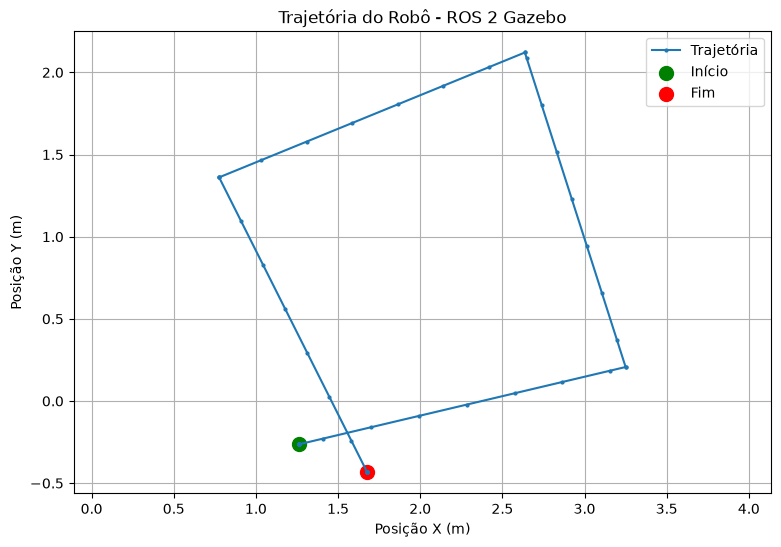

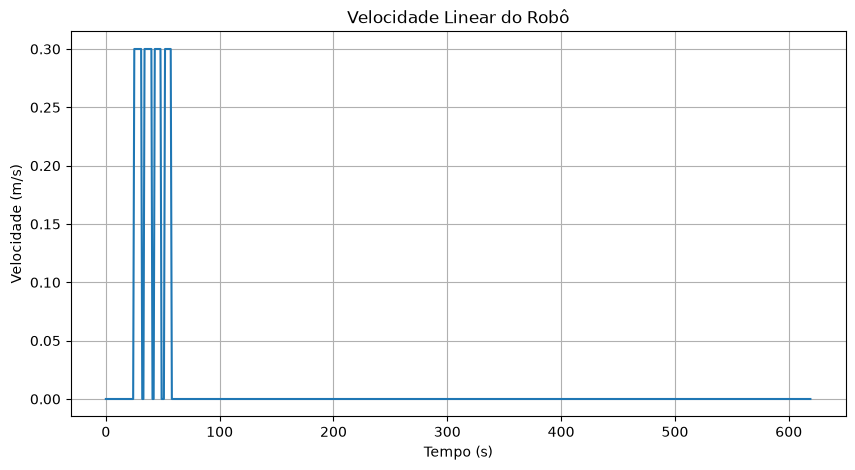

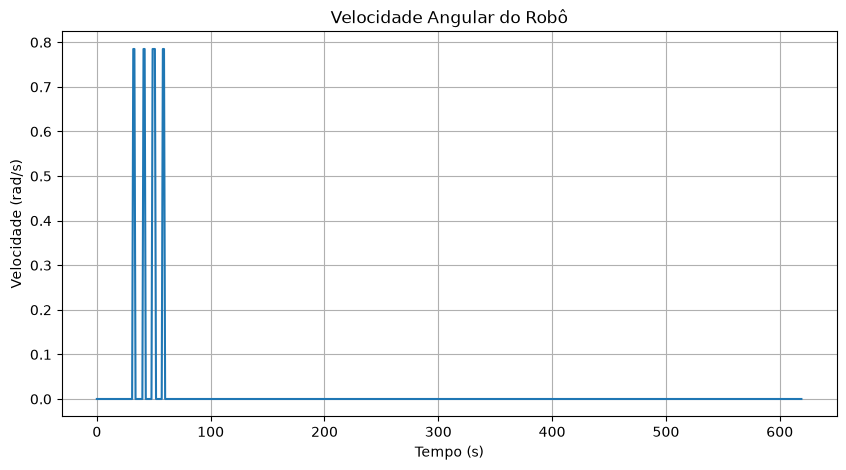

Três gráficos salvos com sucesso!


In [132]:
import matplotlib.pyplot as plt
import os

os.makedirs("models", exist_ok=True)

# 1. Gráfico da trajetória
plt.figure(figsize=(9, 6))
plt.plot(df_movimento['x'], df_movimento['y'],
         marker='o', markersize=2, label='Trajetória')
plt.scatter(df_movimento['x'].iloc[0],
            df_movimento['y'].iloc[0],
            color='green', s=100, label='Início')
plt.scatter(df_movimento['x'].iloc[-1],
            df_movimento['y'].iloc[-1],
            color='red', s=100, label='Fim')

plt.title('Trajetória do Robô - ROS 2 Gazebo')
plt.xlabel('Posição X (m)')
plt.ylabel('Posição Y (m)')
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.savefig("models/trajetoria_patrol.png", dpi=150)
plt.show()

# 2. Velocidade linear
plt.figure(figsize=(10, 5))
plt.plot(df_movimento['tempo_relativo'],
         df_movimento['velocidade_linear'])
plt.title('Velocidade Linear do Robô')
plt.xlabel('Tempo (s)')
plt.ylabel('Velocidade (m/s)')
plt.grid(True)
plt.savefig("models/velocidade_linear_patrol.png", dpi=150)
plt.show()

# 3. Velocidade angular
plt.figure(figsize=(10, 5))
plt.plot(df_movimento['tempo_relativo'],
         df_movimento['velocidade_angular'])
plt.title('Velocidade Angular do Robô')
plt.xlabel('Tempo (s)')
plt.ylabel('Velocidade (rad/s)')
plt.grid(True)
plt.savefig("models/velocidade_angular_patrol.png", dpi=150)
plt.show()

print("Três gráficos salvos com sucesso!")

In [133]:
import os

print("ARQUIVOS DA PASTA MODELS")
print("----------------------------")

for arquivo in sorted(os.listdir("models")):
    caminho = os.path.join("models", arquivo)

    if os.path.isfile(caminho):
        tamanho = os.path.getsize(caminho) / 1024
        print(f"{arquivo} - {tamanho:.1f} KB")

print("\nARQUIVOS DA GRAVAÇÃO ROSBAG")
print("----------------------------")

pasta_bag = os.path.expanduser("~/ros2_ws/patrol_odom_movimento")

if os.path.exists(pasta_bag):
    for arquivo in os.listdir(pasta_bag):
        caminho = os.path.join(pasta_bag, arquivo)
        tamanho = os.path.getsize(caminho) / 1024
        print(f"{arquivo} - {tamanho:.1f} KB")
else:
    print("Pasta da gravação não encontrada.")

ARQUIVOS DA PASTA MODELS
----------------------------
curva_aprendizagem.png - 130.3 KB
historico_patrol.png - 92.4 KB
obstacle_net_v1.pt - 5.9 KB
odometria_patrol.csv - 57.2 KB
probabilidade_obstaculos.png - 85.9 KB
resumo_patrol.json - 0.3 KB
scaler_config.json - 0.2 KB
trajetoria_patrol.png - 69.2 KB
velocidade_angular_patrol.png - 48.8 KB
velocidade_linear_patrol.png - 46.9 KB

ARQUIVOS DA GRAVAÇÃO ROSBAG
----------------------------
metadata.yaml - 1.3 KB
patrol_odom_movimento_0.mcap - 491.8 KB


In [134]:
import os
import subprocess

workspace = os.path.expanduser("~/ros2_ws")

print("VERIFICAÇÃO DO GITHUB")
print("----------------------------")

if os.path.isdir(os.path.join(workspace, ".git")):

    resultado = subprocess.run(
        ["git", "-C", workspace, "log", "--oneline"],
        capture_output=True,
        text=True
    )

    commits = resultado.stdout.strip().splitlines()

    print("Quantidade de commits:", len(commits))
    print("\nÚltimos commits:")

    for commit in commits[:10]:
        print(commit)

    print("\nArquivo .gitignore:")
    caminho_gitignore = os.path.join(workspace, ".gitignore")

    if os.path.exists(caminho_gitignore):
        with open(caminho_gitignore, "r") as arquivo:
            print(arquivo.read())
    else:
        print("Não encontrado!")

else:
    print("A pasta ros2_ws ainda não é um repositório Git.")

VERIFICAÇÃO DO GITHUB
----------------------------
A pasta ros2_ws ainda não é um repositório Git.


In [135]:
import os

print("PASTA ATUAL DO JUPYTER:")
print(os.getcwd())

print("\nARQUIVOS E PASTAS:")
for item in os.listdir(os.getcwd()):
    print(item)
    

PASTA ATUAL DO JUPYTER:
/home/ivan/ros2_ws

ARQUIVOS E PASTAS:
install
bag_record.log
src
patrol_odom_movimento
.ipynb_checkpoints
models
Imagem colada.png
.venv
patrol_odom
bag_movimento.log
log
build
grafico_velocidade_ros2.png
Untitled.ipynb


In [136]:
import os
import subprocess

workspace = os.path.expanduser("~/ros2_ws")

conteudo_gitignore = """
# Ambiente Python
.venv/
__pycache__/
*.pyc

# ROS 2
build/
install/
log/

# Jupyter
.ipynb_checkpoints/

# Logs temporários
*.log

# Rosbag antigo
patrol_odom/

# Arquivos temporários
.DS_Store
"""

caminho = os.path.join(workspace, ".gitignore")

with open(caminho, "w") as arquivo:
    arquivo.write(conteudo_gitignore.strip() + "\n")

subprocess.run(
    ["git", "init", "-b", "main"],
    cwd=workspace,
    check=True
)

print("Repositório Git inicializado!")
print(".gitignore criado com sucesso!")

Repositório Git inicializado!Repositório vazio Git inicializado em  /home/ivan/ros2_ws/.git/

.gitignore criado com sucesso!


In [137]:
import os
import subprocess

workspace = os.path.expanduser("~/ros2_ws")

print("CONTEÚDO DA PASTA SRC")
print("----------------------------")

for raiz, pastas, arquivos in os.walk(os.path.join(workspace, "src")):
    pastas[:] = [p for p in pastas if p != "__pycache__"]
    for arquivo in arquivos:
        caminho = os.path.join(raiz, arquivo)
        print(os.path.relpath(caminho, workspace))

print("\nNOTEBOOK PRINCIPAL")
print("----------------------------")

notebook = os.path.join(workspace, "Untitled.ipynb")
print("Encontrado:", os.path.exists(notebook))

if os.path.exists(notebook):
    print("Tamanho:", round(os.path.getsize(notebook) / 1024, 1), "KB")

print("\nSTATUS DO GIT")
print("----------------------------")

resultado = subprocess.run(
    ["git", "status", "--short"],
    cwd=workspace,
    capture_output=True,
    text=True
)

print(resultado.stdout)

CONTEÚDO DA PASTA SRC
----------------------------
src/patrol_node/setup.py
src/patrol_node/package.xml
src/patrol_node/setup.cfg
src/patrol_node/patrol_node/__init__.py
src/patrol_node/resource/patrol_node
src/patrol_node/test/test_copyright.py
src/patrol_node/test/test_pep257.py
src/patrol_node/test/test_flake8.py

NOTEBOOK PRINCIPAL
----------------------------
Encontrado: True
Tamanho: 691.8 KB

STATUS DO GIT
----------------------------
?? .gitignore
?? "Imagem colada.png"
?? Untitled.ipynb
?? grafico_velocidade_ros2.png
?? models/
?? patrol_odom_movimento/
?? src/



In [138]:
import subprocess

workspace = os.path.expanduser("~/ros2_ws")

subprocess.run(
    ["git", "add", ".gitignore"],
    cwd=workspace,
    check=True
)

resultado = subprocess.run(
    ["git", "commit", "-m", "chore: adicionar gitignore do projeto"],
    cwd=workspace,
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)


Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'ivan@ivan-B365M-H.(none)')



In [140]:
import subprocess

subprocess.run([
    "git", "config", "--global",
    "user.name", "Valdivan Ramos"
], check=True)

subprocess.run([
    "git", "config", "--global",
    "user.email", "valdivan_ivan@hotmail.com"
], check=True)

print("Identidade do Git configurada!")

Identidade do Git configurada!


In [141]:
import subprocess
import os

workspace = os.path.expanduser("~/ros2_ws")

subprocess.run(
    ["git", "add", ".gitignore"],
    cwd=workspace,
    check=True
)

resultado = subprocess.run(
    ["git", "commit", "-m", "chore: adicionar gitignore do projeto"],
    cwd=workspace,
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

[main (root-commit) baef1d0] chore: adicionar gitignore do projeto
 1 file changed, 21 insertions(+)
 create mode 100644 .gitignore




In [142]:
import subprocess
import os

workspace = os.path.expanduser("~/ros2_ws")

subprocess.run(
    ["git", "add", "src/patrol_node"],
    cwd=workspace,
    check=True
)

resultado = subprocess.run(
    ["git", "commit", "-m", "feat: adicionar estrutura do pacote patrol_node"],
    cwd=workspace,
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

[main c1c4c36] feat: adicionar estrutura do pacote patrol_node
 8 files changed, 129 insertions(+)
 create mode 100644 src/patrol_node/package.xml
 create mode 100644 src/patrol_node/patrol_node/__init__.py
 create mode 100644 src/patrol_node/resource/patrol_node
 create mode 100644 src/patrol_node/setup.cfg
 create mode 100644 src/patrol_node/setup.py
 create mode 100644 src/patrol_node/test/test_copyright.py
 create mode 100644 src/patrol_node/test/test_flake8.py
 create mode 100644 src/patrol_node/test/test_pep257.py




In [143]:
import subprocess
import os

workspace = os.path.expanduser("~/ros2_ws")

subprocess.run(
    ["git", "add", "Untitled.ipynb"],
    cwd=workspace,
    check=True
)

resultado = subprocess.run(
    ["git", "commit", "-m", "feat: adicionar notebook de desenvolvimento e testes"],
    cwd=workspace,
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

[main 9d0a2ab] feat: adicionar notebook de desenvolvimento e testes
 1 file changed, 6279 insertions(+)
 create mode 100644 Untitled.ipynb




In [144]:
import subprocess
import os

workspace = os.path.expanduser("~/ros2_ws")

subprocess.run(
    ["git", "add", "models/"],
    cwd=workspace,
    check=True
)

resultado = subprocess.run(
    ["git", "commit", "-m", "feat: adicionar modelo ObstacleNet e resultados"],
    cwd=workspace,
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

[main 53e03bb] feat: adicionar modelo ObstacleNet e resultados
 10 files changed, 543 insertions(+)
 create mode 100644 models/curva_aprendizagem.png
 create mode 100644 models/historico_patrol.png
 create mode 100644 models/obstacle_net_v1.pt
 create mode 100644 models/odometria_patrol.csv
 create mode 100644 models/probabilidade_obstaculos.png
 create mode 100644 models/resumo_patrol.json
 create mode 100644 models/scaler_config.json
 create mode 100644 models/trajetoria_patrol.png
 create mode 100644 models/velocidade_angular_patrol.png
 create mode 100644 models/velocidade_linear_patrol.png




In [145]:
import subprocess
import os

workspace = os.path.expanduser("~/ros2_ws")

subprocess.run(
    ["git", "add", "patrol_odom_movimento/"],
    cwd=workspace,
    check=True
)

resultado = subprocess.run(
    ["git", "commit", "-m", "data: adicionar rosbag da patrulha com odometria"],
    cwd=workspace,
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

[main b479761] data: adicionar rosbag da patrulha com odometria
 2 files changed, 44 insertions(+)
 create mode 100644 patrol_odom_movimento/metadata.yaml
 create mode 100644 patrol_odom_movimento/patrol_odom_movimento_0.mcap




In [146]:
%%writefile README.md
# Projeto de Patrulhamento Autônomo com ROS 2

## Sobre o projeto

Sistema de patrulhamento autônomo desenvolvido com ROS 2, Gazebo, Python e inteligência artificial.

O objetivo é controlar um robô móvel para executar uma trajetória quadrada, identificar indicações de obstáculos e registrar informações de odometria.

## Tecnologias utilizadas

- Ubuntu 24.04
- ROS 2 Jazzy
- Gazebo Harmonic
- Python 3
- Jupyter Notebook
- NumPy, Pandas e Matplotlib
- PyTorch
- Git e GitHub

## Funcionalidades

- Comunicação entre nós ROS 2.
- Controle de velocidade por parâmetros.
- Execução de trajetória quadrada.
- Painel interativo com Jupyter.
- Treinamento e inferência da rede neural ObstacleNet.
- Integração da rede neural com ROS 2.
- Máquina de estados para controle da patrulha.
- Simulação do robô no Gazebo.
- Gravação e análise de odometria com ROS Bag.

## Máquina de estados

O nó de patrulhamento utiliza quatro estados:

- `MOVING_FORWARD`: movimentação em linha reta.
- `TURNING`: execução de curvas.
- `AVOIDING`: parada diante de indicação de obstáculo.
- `DONE`: conclusão da patrulha.

## Inteligência artificial

A ObstacleNet foi desenvolvida com PyTorch. O modelo utiliza dados de velocidade, distância e velocidade angular para estimar a probabilidade de presença de obstáculos.

O treinamento local com dados sintéticos obteve 84% de acurácia na validação.

A distância utilizada nos testes foi fornecida por mensagens ROS 2 simuladas, não por um sensor físico do veículo.

## Resultados da odometria

| Métrica | Resultado |
|---|---:|
| Registros | 620 |
| Duração | 619,01 segundos |
| Distância acumulada | 8,07 metros |
| Deslocamento final | 0,448 metros |
| Velocidade linear máxima | 0,30 m/s |
| Velocidade média em movimento | 0,223 m/s |
| Velocidade angular máxima | 0,785 rad/s |

## Estrutura do projeto

```text
ros2_ws/
├── .gitignore
├── README.md
├── Untitled.ipynb
├── src/
│   └── patrol_node/
├── models/
└── patrol_odom_movimento/

Writing README.md


In [147]:

### Etapa 47 — Registrar o README no Git

Depois de salvar, execute:

```python
import subprocess
import os

workspace = os.path.expanduser("~/ros2_ws")

subprocess.run(
    ["git", "add", "README.md"],
    cwd=workspace,
    check=True
)

resultado = subprocess.run(
    ["git", "commit", "-m", "docs: adicionar documentacao do projeto"],
    cwd=workspace,
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

SyntaxError: invalid syntax (2306314993.py, line 3)

In [148]:
import subprocess
import os

workspace = os.path.expanduser("~/ros2_ws")

subprocess.run(
    ["git", "add", "README.md"],
    cwd=workspace,
    check=True
)

resultado = subprocess.run(
    ["git", "commit", "-m", "docs: adicionar documentacao do projeto"],
    cwd=workspace,
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)

[main 1e26c39] docs: adicionar documentacao do projeto
 1 file changed, 71 insertions(+)
 create mode 100644 README.md




In [149]:
import subprocess
import os

workspace = os.path.expanduser("~/ros2_ws")

resultado = subprocess.run(
    ["git", "remote", "-v"],
    cwd=workspace,
    capture_output=True,
    text=True
)

print(resultado.stdout or "Nenhum repositório remoto configurado.")

Nenhum repositório remoto configurado.


In [150]:
import subprocess
import os

workspace = os.path.expanduser("~/ros2_ws")

resultado = subprocess.run(
    [
        "git", "remote", "add", "origin",
        "https://github.com/IvanEffierre/projeto-patrulha-ros2.git"
    ],
    cwd=workspace,
    capture_output=True,
    text=True
)

print("Conexão configurada!" if resultado.returncode == 0 else resultado.stderr)

Conexão configurada!


In [151]:
import subprocess
import os

workspace = os.path.expanduser("~/ros2_ws")

resultado = subprocess.run(
    ["git", "push", "-u", "origin", "main"],
    cwd=workspace,
    capture_output=True,
    text=True
)

print(resultado.stdout)
print(resultado.stderr)
print("Código de saída:", resultado.returncode)


fatal: could not read Username for 'https://github.com': Endereço ou dispositivo inexistente

Código de saída: 128


In [154]:
import pandas as pd
import os

arquivo = os.path.expanduser(
    "~/ros2_ws/models/odometria_patrol.csv"
)

df = pd.read_csv(arquivo)

print("COLUNAS DO ARQUIVO:")
print(df.columns.tolist())

print("\nTOTAL DE REGISTROS:", len(df))

print("\nPRIMEIROS REGISTROS:")
display(df.head())

print("\nÚLTIMOS REGISTROS:")
display(df.tail())

COLUNAS DO ARQUIVO:
['tempo', 'x', 'y', 'z', 'orientacao_z', 'orientacao_w', 'velocidade_linear', 'velocidade_angular']

TOTAL DE REGISTROS: 528

PRIMEIROS REGISTROS:


,tempo,x,y,z,orientacao_z,orientacao_w,velocidade_linear,velocidade_angular
0,1.794336e+09,1.264917,-0.262812,0.0,-0.115896,-0.993261,0.0,0.0
1,1.794336e+09,1.264917,-0.262812,0.0,-0.115896,-0.993261,0.0,0.0
2,1.794336e+09,1.264917,-0.262812,0.0,-0.115896,-0.993261,0.0,0.0
3,1.794336e+09,1.264917,-0.262812,0.0,-0.115896,-0.993261,0.0,0.0
4,1.794336e+09,1.264917,-0.262812,0.0,-0.115896,-0.993261,0.0,0.0



ÚLTIMOS REGISTROS:


,tempo,x,y,z,orientacao_z,orientacao_w,velocidade_linear,velocidade_angular
523,1.794336e+09,1.264917,-0.262812,0.0,-0.115896,-0.993261,0.0,0.0
524,1.794336e+09,1.264917,-0.262812,0.0,-0.115896,-0.993261,0.0,0.0
525,1.794336e+09,1.264917,-0.262812,0.0,-0.115896,-0.993261,0.0,0.0
526,1.794336e+09,1.264917,-0.262812,0.0,-0.115896,-0.993261,0.0,0.0
527,1.794336e+09,1.264917,-0.262812,0.0,-0.115896,-0.993261,0.0,0.0


In [155]:
import numpy as np

# Verificar duração da coleta
duracao = df["tempo"].iloc[-1] - df["tempo"].iloc[0]

# Calcular deslocamento entre registros consecutivos
dx = df["x"].diff().fillna(0)
dy = df["y"].diff().fillna(0)

deslocamento = np.sqrt(dx**2 + dy**2)

# Identificar registros com movimento
movimento = deslocamento > 0.001

print("ANÁLISE DOS MOVIMENTOS")
print("-" * 40)

print(f"Total de registros: {len(df)}")
print(f"Duração da coleta: {duracao:.2f} segundos")
print(f"Registros com deslocamento: {movimento.sum()}")
print(f"Registros sem deslocamento: {(~movimento).sum()}")

print("\nLIMITES DA TRAJETÓRIA")
print("-" * 40)

print(f"X mínimo: {df['x'].min():.3f} m")
print(f"X máximo: {df['x'].max():.3f} m")
print(f"Y mínimo: {df['y'].min():.3f} m")
print(f"Y máximo: {df['y'].max():.3f} m")

print("\nPOSIÇÕES DIFERENTES:")
print(df.loc[movimento, ["tempo", "x", "y",
                         "velocidade_linear",
                         "velocidade_angular"]].head(10).to_string(index=False))

ANÁLISE DOS MOVIMENTOS
----------------------------------------
Total de registros: 528
Duração da coleta: 627.00 segundos
Registros com deslocamento: 0
Registros sem deslocamento: 528

LIMITES DA TRAJETÓRIA
----------------------------------------
X mínimo: 1.265 m
X máximo: 1.265 m
Y mínimo: -0.263 m
Y máximo: -0.263 m

POSIÇÕES DIFERENTES:
Empty DataFrame
Columns: [tempo, x, y, velocidade_linear, velocidade_angular]
Index: []


In [156]:
import os
import glob
import pandas as pd

pasta = os.path.expanduser("~/ros2_ws")

arquivos = glob.glob(
    os.path.join(pasta, "**", "*.csv"),
    recursive=True
)

print("ARQUIVOS CSV ENCONTRADOS")
print("-" * 60)

for arquivo in arquivos:
    try:
        dados = pd.read_csv(arquivo)

        print(f"\nArquivo: {arquivo}")
        print(f"Registros: {len(dados)}")

        if "x" in dados.columns and "y" in dados.columns:
            print(f"Variação X: {dados['x'].max() - dados['x'].min():.3f} m")
            print(f"Variação Y: {dados['y'].max() - dados['y'].min():.3f} m")

    except Exception as erro:
        print(f"Não foi possível ler: {arquivo}")
        print(erro)

ARQUIVOS CSV ENCONTRADOS
------------------------------------------------------------

Arquivo: /home/ivan/ros2_ws/models/odometria_patrol.csv
Registros: 528
Variação X: 0.000 m
Variação Y: 0.000 m


In [157]:
import subprocess
import os

bag = os.path.expanduser(
    "~/ros2_ws/patrol_odom_movimento"
)

resultado = subprocess.run(
    ["ros2", "bag", "info", bag],
    capture_output=True,
    text=True
)

print("INFORMAÇÕES DO ROSBAG")
print("-" * 50)
print(resultado.stdout)

if resultado.stderr:
    print("ERROS:")
    print(resultado.stderr)

INFORMAÇÕES DO ROSBAG
--------------------------------------------------

Files:             patrol_odom_movimento_0.mcap
Bag size:          493.1 KiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          619.010234785s
Start:             Nov 10 2026 16:12:05.472636308 (1794337925.472636308)
End:               Nov 10 2026 16:22:24.482871093 (1794338544.482871093)
Messages:          620
Topic information: Topic: /odom | Type: nav_msgs/msg/Odometry | Count: 620 | Serialization Format: cdr
Service:           0
Service information: 



In [158]:
import os
import pandas as pd
import rosbag2_py

from rclpy.serialization import deserialize_message
from nav_msgs.msg import Odometry

bag = os.path.expanduser("~/ros2_ws/patrol_odom_movimento")

reader = rosbag2_py.SequentialReader()

storage_options = rosbag2_py.StorageOptions(
    uri=bag,
    storage_id="mcap"
)

converter_options = rosbag2_py.ConverterOptions(
    input_serialization_format="cdr",
    output_serialization_format="cdr"
)

reader.open(storage_options, converter_options)

registros = []

while reader.has_next():
    topic, dados, timestamp = reader.read_next()

    if topic == "/odom":
        msg = deserialize_message(dados, Odometry)

        registros.append({
            "tempo": timestamp / 1e9,
            "x": msg.pose.pose.position.x,
            "y": msg.pose.pose.position.y,
            "orientacao_z": msg.pose.pose.orientation.z,
            "orientacao_w": msg.pose.pose.orientation.w,
            "velocidade_linear": msg.twist.twist.linear.x,
            "velocidade_angular": msg.twist.twist.angular.z
        })

df_bag = pd.DataFrame(registros)

print("RECUPERAÇÃO DA ODOMETRIA")
print("-" * 45)

print("Mensagens recuperadas:", len(df_bag))
print(f"Variação X: {df_bag['x'].max() - df_bag['x'].min():.3f} m")
print(f"Variação Y: {df_bag['y'].max() - df_bag['y'].min():.3f} m")

dx = df_bag["x"].diff().fillna(0)
dy = df_bag["y"].diff().fillna(0)

distancia = (dx**2 + dy**2)**0.5

print(f"Distância acumulada: {distancia.sum():.3f} m")
print(f"Registros com movimento: {(distancia > 0.001).sum()}")

# Salvar em um novo arquivo, sem sobrescrever o original
destino = os.path.expanduser(
    "~/ros2_ws/models/odometria_patrol_recuperada.csv"
)

df_bag.to_csv(destino, index=False)

print("\nNovo arquivo salvo em:")
print(destino)

print("\nPrimeiros registros:")
display(df_bag.head())

print("\nÚltimos registros:")
display(df_bag.tail())

RECUPERAÇÃO DA ODOMETRIA
---------------------------------------------
Mensagens recuperadas: 620
Variação X: 2.474 m
Variação Y: 2.556 m
Distância acumulada: 8.070 m
Registros com movimento: 30

Novo arquivo salvo em:
/home/ivan/ros2_ws/models/odometria_patrol_recuperada.csv

Primeiros registros:


,tempo,x,y,orientacao_z,orientacao_w,velocidade_linear,velocidade_angular
0,1.794338e+09,1.264917,-0.262812,-0.115896,-0.993261,0.0,0.0
1,1.794338e+09,1.264917,-0.262812,-0.115896,-0.993261,0.0,0.0
2,1.794338e+09,1.264917,-0.262812,-0.115896,-0.993261,0.0,0.0
3,1.794338e+09,1.264917,-0.262812,-0.115896,-0.993261,0.0,0.0
4,1.794338e+09,1.264917,-0.262812,-0.115896,-0.993261,0.0,0.0



Últimos registros:


,tempo,x,y,orientacao_z,orientacao_w,velocidade_linear,velocidade_angular
615,1.794339e+09,1.678203,-0.435102,0.230231,0.973136,0.0,0.0
616,1.794339e+09,1.678203,-0.435102,0.230231,0.973136,0.0,0.0
617,1.794339e+09,1.678203,-0.435102,0.230231,0.973136,0.0,0.0
618,1.794339e+09,1.678203,-0.435102,0.230231,0.973136,0.0,0.0
619,1.794339e+09,1.678203,-0.435102,0.230231,0.973136,0.0,0.0


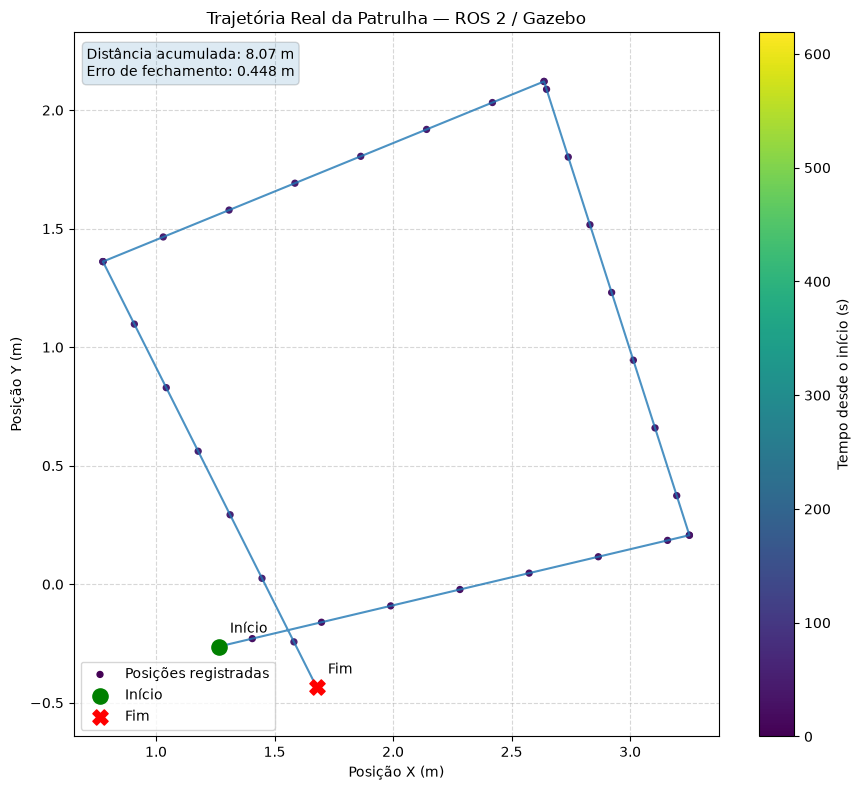

Gráfico salvo com sucesso!
/home/ivan/ros2_ws/models/trajetoria_patrol_recuperada.png
Erro de fechamento: 0.448 m


In [159]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Usar os dados recuperados do rosbag
x = df_bag["x"].to_numpy()
y = df_bag["y"].to_numpy()
tempo = df_bag["tempo"].to_numpy()

# Posições inicial e final
inicio = (x[0], y[0])
fim = (x[-1], y[-1])

# Erro de fechamento
erro = np.hypot(fim[0] - inicio[0], fim[1] - inicio[1])

# Criar gráfico
fig, ax = plt.subplots(figsize=(9, 8))

trajetoria = ax.scatter(
    x, y,
    c=tempo - tempo[0],
    cmap="viridis",
    s=18,
    label="Posições registradas"
)

ax.plot(x, y, linewidth=1.5, alpha=0.8)

ax.scatter(*inicio, color="green", s=120,
           marker="o", label="Início", zorder=5)

ax.scatter(*fim, color="red", s=120,
           marker="X", label="Fim", zorder=5)

ax.annotate("Início", inicio, xytext=(8, 10),
            textcoords="offset points")

ax.annotate("Fim", fim, xytext=(8, 10),
            textcoords="offset points")

ax.set_title("Trajetória Real da Patrulha — ROS 2 / Gazebo")
ax.set_xlabel("Posição X (m)")
ax.set_ylabel("Posição Y (m)")

ax.axis("equal")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()

barra = plt.colorbar(trajetoria, ax=ax)
barra.set_label("Tempo desde o início (s)")

ax.text(
    0.02, 0.98,
    f"Distância acumulada: {sum(np.hypot(np.diff(x), np.diff(y))):.2f} m\n"
    f"Erro de fechamento: {erro:.3f} m",
    transform=ax.transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", alpha=0.15)
)

plt.tight_layout()

destino = os.path.expanduser(
    "~/ros2_ws/models/trajetoria_patrol_recuperada.png"
)

plt.savefig(destino, dpi=180, bbox_inches="tight")
plt.show()

print("Gráfico salvo com sucesso!")
print(destino)
print(f"Erro de fechamento: {erro:.3f} m")

In [160]:
import numpy as np
import pandas as pd

analise = df_bag.copy()

# Diferença de posição entre registros consecutivos
analise["dx"] = analise["x"].diff().fillna(0)
analise["dy"] = analise["y"].diff().fillna(0)

# Distância percorrida entre registros
analise["distancia_trecho"] = np.sqrt(
    analise["dx"]**2 + analise["dy"]**2
)

# Seleciona registros com deslocamento real
movimentos = analise[
    analise["distancia_trecho"] > 0.001
].copy()

print("ANÁLISE DOS TRECHOS DE MOVIMENTO")
print("-" * 50)

print("Total de trechos com deslocamento:", len(movimentos))
print(f"Distância acumulada: {analise['distancia_trecho'].sum():.3f} m")

print("\nPOSIÇÃO INICIAL:")
print(f"X: {analise.iloc[0]['x']:.3f} m")
print(f"Y: {analise.iloc[0]['y']:.3f} m")

print("\nPOSIÇÃO FINAL:")
print(f"X: {analise.iloc[-1]['x']:.3f} m")
print(f"Y: {analise.iloc[-1]['y']:.3f} m")

print("\nDESLOCAMENTOS REGISTRADOS:")
display(
    movimentos[
        [
            "tempo", "x", "y", "dx", "dy",
            "distancia_trecho",
            "velocidade_linear",
            "velocidade_angular"
        ]
    ].round(3)
)

ANÁLISE DOS TRECHOS DE MOVIMENTO
--------------------------------------------------
Total de trechos com deslocamento: 30
Distância acumulada: 8.070 m

POSIÇÃO INICIAL:
X: 1.265 m
Y: -0.263 m

POSIÇÃO FINAL:
X: 1.678 m
Y: -0.435 m

DESLOCAMENTOS REGISTRADOS:


,tempo,x,y,dx,dy,distancia_trecho,velocidade_linear,velocidade_angular
25,1.794338e+09,1.406,-0.229,0.141,0.033,0.145,0.3,0.000
26,1.794338e+09,1.698,-0.160,0.292,0.069,0.300,0.3,-0.000
27,1.794338e+09,1.990,-0.091,0.292,0.069,0.300,0.3,-0.000
28,1.794338e+09,2.282,-0.022,0.292,0.069,0.300,0.3,-0.000
29,1.794338e+09,2.574,0.047,0.292,0.069,0.300,0.3,-0.000
30,1.794338e+09,2.866,0.116,0.292,0.069,0.300,0.3,-0.000
31,1.794338e+09,3.158,0.185,0.292,0.069,0.300,0.3,-0.000
32,1.794338e+09,3.250,0.207,0.092,0.022,0.095,-0.0,0.785
34,1.794338e+09,3.197,0.374,-0.053,0.167,0.175,0.3,-0.000
35,1.794338e+09,3.105,0.659,-0.092,0.286,0.300,0.3,-0.000


In [161]:
import numpy as np
import pandas as pd

df = df_bag.reset_index(drop=True).copy()

# Identifica deslocamentos retos, sem considerar os giros
reto = (
    (df["velocidade_linear"].abs() > 0.05) &
    (df["velocidade_angular"].abs() < 0.1)
)

# Agrupa registros consecutivos de movimento reto
grupo = (reto != reto.shift()).cumsum()

resultados = []

for _, trecho in df[reto].groupby(grupo[reto]):
    inicio = trecho.index[0] - 1
    fim = trecho.index[-1]

    x0, y0 = df.loc[inicio, ["x", "y"]]
    x1, y1 = df.loc[fim, ["x", "y"]]

    dx = x1 - x0
    dy = y1 - y0

    distancia = np.sqrt(dx**2 + dy**2)
    angulo = np.degrees(np.arctan2(dy, dx))

    resultados.append({
        "trecho": len(resultados) + 1,
        "distancia_m": distancia,
        "deslocamento_x": dx,
        "deslocamento_y": dy,
        "direcao_graus": angulo
    })

resumo = pd.DataFrame(resultados)

print("ANÁLISE DOS QUATRO LADOS")
print("-" * 50)

display(resumo.round(3))

print("\nDISTÂNCIA TOTAL DOS TRECHOS RETOS:")
print(f"{resumo['distancia_m'].sum():.3f} m")

print("\nDISTÂNCIA IDEAL POR LADO: 2.000 m")

ANÁLISE DOS QUATRO LADOS
--------------------------------------------------


,trecho,distancia_m,deslocamento_x,deslocamento_y,direcao_graus
0,1,1.945,1.893,0.448,13.311
1,2,1.975,-0.603,1.881,107.763
2,3,1.735,-1.606,-0.656,-157.785
3,4,1.795,0.806,-1.604,-63.333



DISTÂNCIA TOTAL DOS TRECHOS RETOS:
7.451 m

DISTÂNCIA IDEAL POR LADO: 2.000 m


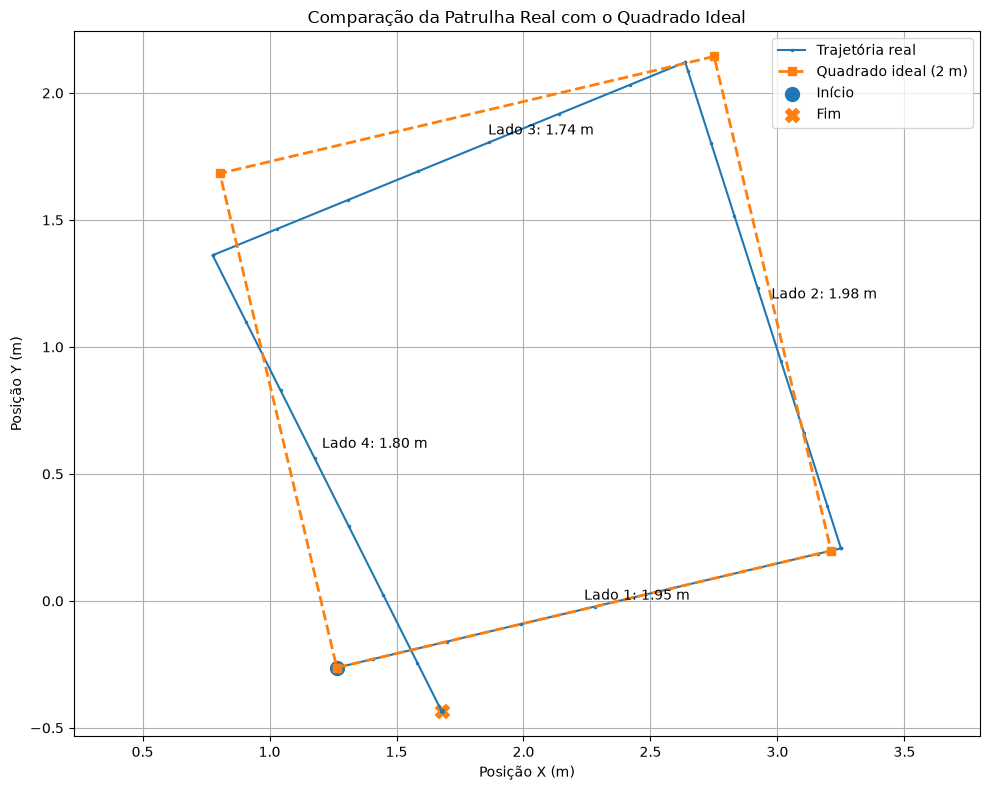

Gráfico salvo em:
/home/ivan/ros2_ws/models/comparacao_trajetoria_patrol.png


In [162]:
import numpy as np
import matplotlib.pyplot as plt

df = df_bag.reset_index(drop=True).copy()

# Identificar os trechos retos
reto = (
    (df["velocidade_linear"].abs() > 0.05) &
    (df["velocidade_angular"].abs() < 0.1)
)

grupo = (reto != reto.shift()).cumsum()

segmentos = []

for _, trecho in df[reto].groupby(grupo[reto]):
    inicio = trecho.index[0] - 1
    fim = trecho.index[-1]

    x0, y0 = df.loc[inicio, ["x", "y"]]
    x1, y1 = df.loc[fim, ["x", "y"]]

    distancia = np.hypot(x1 - x0, y1 - y0)
    angulo = np.arctan2(y1 - y0, x1 - x0)

    segmentos.append({
        "x0": x0, "y0": y0,
        "x1": x1, "y1": y1,
        "distancia": distancia,
        "angulo": angulo
    })

# Construir quadrado ideal de 2 metros
primeiro = segmentos[0]
pontos_ideais = [(primeiro["x0"], primeiro["y0"])]

x, y = primeiro["x0"], primeiro["y0"]
angulo = primeiro["angulo"]

for i in range(4):
    x += 2.0 * np.cos(angulo)
    y += 2.0 * np.sin(angulo)

    pontos_ideais.append((x, y))
    angulo += np.pi / 2

pontos_ideais = np.array(pontos_ideais)

# Criar gráfico
plt.figure(figsize=(10, 8))

# Trajetória real
plt.plot(
    df["x"], df["y"],
    marker=".",
    markersize=3,
    linewidth=1.5,
    label="Trajetória real"
)

# Quadrado ideal
plt.plot(
    pontos_ideais[:, 0],
    pontos_ideais[:, 1],
    linestyle="--",
    marker="s",
    linewidth=2,
    label="Quadrado ideal (2 m)"
)

# Início e fim reais
plt.scatter(
    df.iloc[0]["x"], df.iloc[0]["y"],
    marker="o", s=100, label="Início"
)

plt.scatter(
    df.iloc[-1]["x"], df.iloc[-1]["y"],
    marker="X", s=100, label="Fim"
)

# Identificação dos lados reais
for i, s in enumerate(segmentos):
    xm = (s["x0"] + s["x1"]) / 2
    ym = (s["y0"] + s["y1"]) / 2

    plt.annotate(
        f"Lado {i+1}: {s['distancia']:.2f} m",
        (xm, ym),
        xytext=(5, 8),
        textcoords="offset points"
    )

plt.title("Comparação da Patrulha Real com o Quadrado Ideal")
plt.xlabel("Posição X (m)")
plt.ylabel("Posição Y (m)")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()

destino = os.path.expanduser(
    "~/ros2_ws/models/comparacao_trajetoria_patrol.png"
)

plt.savefig(destino, dpi=150)
plt.show()

print("Gráfico salvo em:")
print(destino)

In [163]:
import json
import os

arquivo = os.path.expanduser("~/ros2_ws/Untitled.ipynb")

with open(arquivo, "r", encoding="utf-8") as f:
    notebook = json.load(f)

termos = [
    "TURNING",
    "0.785",
    "turn_duration",
    "linear.x",
    "angular.z",
    "lado_atual"
]

print("TRECHOS DO CÓDIGO DE MOVIMENTAÇÃO")
print("-" * 50)

for i, celula in enumerate(notebook["cells"]):
    if celula["cell_type"] != "code":
        continue

    codigo = "".join(celula["source"])

    if any(termo in codigo for termo in termos):
        print(f"\n--- CÉLULA {i} ---")
        print(codigo[:4000])

TRECHOS DO CÓDIGO DE MOVIMENTAÇÃO
--------------------------------------------------

--- CÉLULA 6 ---
import rclpy
import time
import math
import threading

from rclpy.node import Node
from geometry_msgs.msg import Twist


class QuadradoNode(Node):

    def __init__(self):
        super().__init__('quadrado_node')

        self.publisher = self.create_publisher(
            Twist,
            '/cmd_vel',
            10
        )

        self.vel_linear = 0.3
        self.vel_angular = 0.785

        self.tempo_reto = 2.0 / self.vel_linear
        self.tempo_giro = (math.pi / 2) / self.vel_angular

        self.etapa = 0
        self.inicio_etapa = time.monotonic()
        self.concluido = False

        self.timer = self.create_timer(0.1, self.executar)

        self.get_logger().info('Iniciando percurso quadrado!')

    def executar(self):

        if self.concluido:
            return

        msg = Twist()

        if self.etapa >= 8:
            self.publisher.publish(msg)
      

In [164]:
codigo = "".join(notebook["cells"][6]["source"])

print(codigo)

import rclpy
import time
import math
import threading

from rclpy.node import Node
from geometry_msgs.msg import Twist


class QuadradoNode(Node):

    def __init__(self):
        super().__init__('quadrado_node')

        self.publisher = self.create_publisher(
            Twist,
            '/cmd_vel',
            10
        )

        self.vel_linear = 0.3
        self.vel_angular = 0.785

        self.tempo_reto = 2.0 / self.vel_linear
        self.tempo_giro = (math.pi / 2) / self.vel_angular

        self.etapa = 0
        self.inicio_etapa = time.monotonic()
        self.concluido = False

        self.timer = self.create_timer(0.1, self.executar)

        self.get_logger().info('Iniciando percurso quadrado!')

    def executar(self):

        if self.concluido:
            return

        msg = Twist()

        if self.etapa >= 8:
            self.publisher.publish(msg)
            self.concluido = True
            self.timer.cancel()

            self.get_logger().info(
      

In [165]:
import rclpy
import time

from rclpy.node import Node
from nav_msgs.msg import Odometry

if not rclpy.ok():
    rclpy.init()

class TesteOdomNode(Node):

    def __init__(self):
        super().__init__('teste_odom_node')

        self.recebidas = 0

        self.subscription = self.create_subscription(
            Odometry,
            '/odom',
            self.callback,
            10
        )

    def callback(self, msg):
        self.recebidas += 1

        if self.recebidas == 1:
            print("Primeira mensagem recebida!")
            print(f"X: {msg.pose.pose.position.x:.3f} m")
            print(f"Y: {msg.pose.pose.position.y:.3f} m")

node_teste = TesteOdomNode()

inicio = time.time()

while time.time() - inicio < 5:
    rclpy.spin_once(node_teste, timeout_sec=0.1)

print("\nVERIFICAÇÃO DA ODOMETRIA")
print("-" * 35)
print("Mensagens recebidas:", node_teste.recebidas)

node_teste.destroy_node()

RuntimeError: Executor is already spinning

In [166]:
import rclpy
import time

from rclpy.node import Node
from rclpy.executors import SingleThreadedExecutor
from nav_msgs.msg import Odometry

class TesteOdomNode(Node):

    def __init__(self):
        super().__init__('teste_odom_node')

        self.recebidas = 0

        self.subscription = self.create_subscription(
            Odometry,
            '/odom',
            self.callback,
            10
        )

    def callback(self, msg):
        self.recebidas += 1

        if self.recebidas == 1:
            print("Primeira mensagem recebida!")
            print(f"X: {msg.pose.pose.position.x:.3f} m")
            print(f"Y: {msg.pose.pose.position.y:.3f} m")

node_teste = TesteOdomNode()

executor_teste = SingleThreadedExecutor()
executor_teste.add_node(node_teste)

inicio = time.time()

while time.time() - inicio < 5:
    executor_teste.spin_once(timeout_sec=0.1)

print("\nVERIFICAÇÃO DA ODOMETRIA")
print("-" * 35)
print("Mensagens recebidas:", node_teste.recebidas)

executor_teste.remove_node(node_teste)
executor_teste.shutdown()
node_teste.destroy_node()

[WARN] [1794413481.353392055] [rcl.logging_rosout]: Publisher already registered for node name: 'teste_odom_node'. If this is due to multiple nodes with the same name then all logs for the logger named 'teste_odom_node' will go out over the existing publisher. As soon as any node with that name is destructed it will unregister the publisher, preventing any further logs for that name from being published on the rosout topic.



VERIFICAÇÃO DA ODOMETRIA
-----------------------------------
Mensagens recebidas: 0


In [167]:
import subprocess

print("NÓS ROS 2 ATIVOS")
print("-" * 40)

resultado = subprocess.run(
    ["ros2", "node", "list"],
    capture_output=True,
    text=True
)

print(resultado.stdout)

print("\nINFORMAÇÕES DO TÓPICO /odom")
print("-" * 40)

resultado = subprocess.run(
    ["ros2", "topic", "info", "/odom", "--verbose"],
    capture_output=True,
    text=True
)

print(resultado.stdout)

if resultado.stderr:
    print("Avisos:", resultado.stderr)

NÓS ROS 2 ATIVOS
----------------------------------------
/jupyter_monitor_node
/obstacle_net_node
/patrol_node
/ros_gz_bridge
/ros_gz_bridge
/teste_odom_node


INFORMAÇÕES DO TÓPICO /odom
----------------------------------------

Avisos: Unknown topic '/odom'



In [168]:
import subprocess

resultado = subprocess.run(
    ["ros2", "topic", "list"],
    capture_output=True,
    text=True
)

print("TÓPICOS DISPONÍVEIS NO ROS 2")
print("-" * 45)

for topico in resultado.stdout.splitlines():
    print(topico)

TÓPICOS DISPONÍVEIS NO ROS 2
---------------------------------------------
/cmd_vel
/distancia_obstaculo
/jupyter_status
/model/patrol_vehicle/cmd_vel
/model/patrol_vehicle/odometry
/obstaculo
/odom
/parameter_events
/rosout
/velocidade


In [169]:
import subprocess

topicos = [
    "/odom",
    "/model/patrol_vehicle/odometry"
]

for topico in topicos:

    print(f"\nTÓPICO: {topico}")
    print("-" * 45)

    resultado = subprocess.run(
        ["ros2", "topic", "info", topico, "--verbose"],
        capture_output=True,
        text=True
    )

    print(resultado.stdout)

    if resultado.stderr:
        print(resultado.stderr)


TÓPICO: /odom
---------------------------------------------
Type: nav_msgs/msg/Odometry

Publisher count: 1

Node name: jupyter_monitor_node
Node namespace: /
Topic type: nav_msgs/msg/Odometry
Topic type hash: RIHS01_3cc97dc7fb7502f8714462c526d369e35b603cfc34d946e3f2eda2766dfec6e0
Endpoint type: PUBLISHER
GID: 01.0f.10.12.56.b9.68.27.00.00.00.00.00.00.46.03
QoS profile:
  Reliability: RELIABLE
  History (Depth): UNKNOWN
  Durability: VOLATILE
  Lifespan: Infinite
  Deadline: Infinite
  Liveliness: AUTOMATIC
  Liveliness lease duration: Infinite

Subscription count: 1

Node name: _NODE_NAME_UNKNOWN_
Node namespace: _NODE_NAMESPACE_UNKNOWN_
Topic type: nav_msgs/msg/Odometry
Topic type hash: RIHS01_3cc97dc7fb7502f8714462c526d369e35b603cfc34d946e3f2eda2766dfec6e0
Endpoint type: SUBSCRIPTION
GID: 01.0f.10.12.56.b9.68.27.00.00.00.00.00.00.58.04
QoS profile:
  Reliability: RELIABLE
  History (Depth): UNKNOWN
  Durability: VOLATILE
  Lifespan: Infinite
  Deadline: Infinite
  Liveliness: AUTOM

In [170]:
import subprocess

topico = "/model/patrol_vehicle/odometry"

print("TESTANDO ODOMETRIA DO GAZEBO")
print("-" * 45)

try:
    resultado = subprocess.run(
        ["ros2", "topic", "echo", "--once", topico],
        capture_output=True,
        text=True,
        timeout=8
    )

    if resultado.returncode == 0:
        print("Mensagem recebida com sucesso!")
        print(resultado.stdout[:2500])
    else:
        print("Não foi possível receber a mensagem.")
        print(resultado.stderr)

except subprocess.TimeoutExpired:
    print("Tempo esgotado: nenhuma mensagem recebida em 8 segundos.")

TESTANDO ODOMETRIA DO GAZEBO
---------------------------------------------
Mensagem recebida com sucesso!
header:
  stamp:
    sec: 79944
    nanosec: 348000000
  frame_id: patrol_vehicle/odom
child_frame_id: patrol_vehicle/chassis
pose:
  pose:
    position:
      x: 1.678203233241158
      y: -0.43510192141712317
      z: 0.0
    orientation:
      x: 0.0
      y: 0.0
      z: 0.23023064938431712
      w: 0.9731360891900349
  covariance:
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
twist:
  twist:
    linear:
      x: 0.0
      y: 0.0
      z: 0.0
    angular:
      x: 0.0
      y: 0.0
      z: 0.0
  covariance:
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0

In [171]:
import subprocess

for topico in ["/cmd_vel", "/model/patrol_vehicle/cmd_vel"]:

    print(f"\nTÓPICO: {topico}")
    print("-" * 45)

    resultado = subprocess.run(
        ["ros2", "topic", "info", topico, "--verbose"],
        capture_output=True,
        text=True
    )

    print(resultado.stdout)


TÓPICO: /cmd_vel
---------------------------------------------
Type: geometry_msgs/msg/Twist

Publisher count: 1

Node name: jupyter_monitor_node
Node namespace: /
Topic type: geometry_msgs/msg/Twist
Topic type hash: RIHS01_9c45bf16fe0983d80e3cfe750d6835843d265a9a6c46bd2e609fcddde6fb8d2a
Endpoint type: PUBLISHER
GID: 01.0f.10.12.56.b9.68.27.00.00.00.00.00.00.41.03
QoS profile:
  Reliability: RELIABLE
  History (Depth): UNKNOWN
  Durability: VOLATILE
  Lifespan: Infinite
  Deadline: Infinite
  Liveliness: AUTOMATIC
  Liveliness lease duration: Infinite

Subscription count: 0



TÓPICO: /model/patrol_vehicle/cmd_vel
---------------------------------------------
Type: geometry_msgs/msg/Twist

Publisher count: 2

Node name: jupyter_monitor_node
Node namespace: /
Topic type: geometry_msgs/msg/Twist
Topic type hash: RIHS01_9c45bf16fe0983d80e3cfe750d6835843d265a9a6c46bd2e609fcddde6fb8d2a
Endpoint type: PUBLISHER
GID: 01.0f.10.12.56.b9.68.27.00.00.00.00.00.00.42.03
QoS profile:
  Reliability:

In [172]:
import subprocess

nos = [
    "/patrol_node",
    "/jupyter_monitor_node"
]

for no in nos:

    print(f"\nINFORMAÇÕES DO NÓ: {no}")
    print("-" * 50)

    resultado = subprocess.run(
        ["ros2", "node", "info", no],
        capture_output=True,
        text=True
    )

    print(resultado.stdout)

    if resultado.stderr:
        print(resultado.stderr)


INFORMAÇÕES DO NÓ: /patrol_node
--------------------------------------------------
/patrol_node
  Subscribers:
    /obstaculo: std_msgs/msg/Bool
  Publishers:
    /model/patrol_vehicle/cmd_vel: geometry_msgs/msg/Twist
    /parameter_events: rcl_interfaces/msg/ParameterEvent
    /rosout: rcl_interfaces/msg/Log
  Service Servers:
    /patrol_node/describe_parameters: rcl_interfaces/srv/DescribeParameters
    /patrol_node/get_parameter_types: rcl_interfaces/srv/GetParameterTypes
    /patrol_node/get_parameters: rcl_interfaces/srv/GetParameters
    /patrol_node/get_type_description: type_description_interfaces/srv/GetTypeDescription
    /patrol_node/list_parameters: rcl_interfaces/srv/ListParameters
    /patrol_node/set_parameters: rcl_interfaces/srv/SetParameters
    /patrol_node/set_parameters_atomically: rcl_interfaces/srv/SetParametersAtomically
  Service Clients:

  Action Servers:

  Action Clients:



INFORMAÇÕES DO NÓ: /jupyter_monitor_node
----------------------------------------

In [173]:
print("VERIFICAÇÃO DOS CONTROLADORES")
print("-" * 45)

variaveis = [
    "patrol",
    "executor_patrol",
    "thread_patrol",
    "node",
    "executor_monitor",
    "thread_monitor"
]

for nome in variaveis:

    if nome in globals():
        objeto = globals()[nome]

        print(f"\n{nome}: DISPONÍVEL")
        print("Tipo:", type(objeto).__name__)

        if nome == "patrol":
            print("Estado:", getattr(objeto, "estado", "Não identificado"))

        if nome in ["thread_patrol", "thread_monitor"]:
            print("Thread ativa:", objeto.is_alive())

    else:
        print(f"\n{nome}: NÃO ENCONTRADO")

VERIFICAÇÃO DOS CONTROLADORES
---------------------------------------------

patrol: DISPONÍVEL
Tipo: PatrolNode
Estado: DONE

executor_patrol: DISPONÍVEL
Tipo: SingleThreadedExecutor

thread_patrol: DISPONÍVEL
Tipo: Thread
Thread ativa: True

node: DISPONÍVEL
Tipo: Node

executor_monitor: DISPONÍVEL
Tipo: SingleThreadedExecutor

thread_monitor: DISPONÍVEL
Tipo: Thread
Thread ativa: True


In [174]:
print("ENCERRANDO CONTROLADOR DE PATRULHA")
print("-" * 45)

executor_patrol.shutdown()

thread_patrol.join(timeout=3)

patrol.destroy_node()

print("Executor encerrado:", not thread_patrol.is_alive())
print("Nó de patrulha destruído.")
print("Monitoramento preservado:", thread_monitor.is_alive())

ENCERRANDO CONTROLADOR DE PATRULHA
---------------------------------------------
Executor encerrado: True
Nó de patrulha destruído.
Monitoramento preservado: True


In [175]:
print("PUBLICADORES E TEMPORIZADORES DO MONITOR")
print("-" * 50)

for nome, objeto in vars(node).items():

    if hasattr(objeto, "publish"):
        print(f"Publicador: {nome}")

    elif hasattr(objeto, "cancel"):
        print(f"Temporizador: {nome}")

PUBLICADORES E TEMPORIZADORES DO MONITOR
--------------------------------------------------
Publicador: _parameter_event_publisher


In [176]:
print("NÓS REGISTRADOS NO EXECUTOR DE MONITORAMENTO")
print("-" * 50)

for n in executor_monitor.get_nodes():
    print("Nome:", n.get_name())
    print("Publicadores:")

    for pub in n.publishers:
        print(" -", pub.topic_name)

    print("Assinantes:")

    for sub in n.subscriptions:
        print(" -", sub.topic_name)

    print("Temporizadores:", len(n.timers))

print("\nVARIÁVEIS QUE CONTÊM NÓS ROS 2")
print("-" * 50)

for nome, objeto in globals().items():

    if isinstance(objeto, type(node)):
        if hasattr(objeto, "get_name"):
            print(nome, "->", objeto.get_name())

NÓS REGISTRADOS NO EXECUTOR DE MONITORAMENTO
--------------------------------------------------
Nome: jupyter_monitor_node
Publicadores:
 - /parameter_events
 - /jupyter_status
 - /velocidade
 - /distancia_obstaculo
 - /distancia_obstaculo
 - /cmd_vel
 - /model/patrol_vehicle/cmd_vel
 - /odom
Assinantes:
 - /jupyter_status
 - /velocidade
 - /distancia_obstaculo
 - /distancia_obstaculo
 - /obstaculo
 - /model/patrol_vehicle/odometry
 - /model/patrol_vehicle/odometry


TypeError: object of type 'generator' has no len()

In [177]:
print("TEMPORIZADORES DO MONITOR")
print("-" * 45)

for i, timer in enumerate(list(n.timers)):

    print(f"\nTemporizador {i + 1}")
    print("Tipo:", type(timer).__name__)
    print("Callback:", getattr(timer, "callback", "Não identificado"))
    print("Período:", timer.timer_period_ns / 1e9, "segundos")
    print("Cancelado:", timer.is_canceled())

TEMPORIZADORES DO MONITOR
---------------------------------------------


In [178]:
import subprocess

print("MONITORANDO COMANDOS DE VELOCIDADE")
print("-" * 45)

try:
    resultado = subprocess.run(
        [
            "ros2", "topic", "echo",
            "--once",
            "/model/patrol_vehicle/cmd_vel"
        ],
        capture_output=True,
        text=True,
        timeout=5
    )

    if resultado.returncode == 0:
        print("Mensagem recebida:")
        print(resultado.stdout)
    else:
        print("Nenhuma mensagem recebida.")
        print(resultado.stderr)

except subprocess.TimeoutExpired:
    print("Nenhum comando recebido durante 5 segundos.")

MONITORANDO COMANDOS DE VELOCIDADE
---------------------------------------------
Nenhum comando recebido durante 5 segundos.


In [179]:
import inspect

monitor = executor_monitor.get_nodes()[0]

print("CLASSE DO MONITOR")
print("-" * 45)
print(type(monitor).__name__)

print("\nCÓDIGO DO MONITOR")
print("-" * 45)

try:
    print(inspect.getsource(type(monitor)))
except Exception as erro:
    print("Não foi possível recuperar o código:", erro)

CLASSE DO MONITOR
---------------------------------------------
Node

CÓDIGO DO MONITOR
---------------------------------------------
class Node:
    """
    A Node in the ROS graph.

    A Node is the primary entrypoint in a ROS system for communication.
    It can be used to create ROS entities such as publishers, subscribers, services, etc.
    """

    PARAM_REL_TOL = 1e-6
    """
    Relative tolerance for floating point parameter values' comparison.
    See `math.isclose` documentation.
    """

    def __init__(
        self,
        node_name: str,
        *,
        context: Optional[Context] = None,
        cli_args: Optional[List[str]] = None,
        namespace: Optional[str] = None,
        use_global_arguments: bool = True,
        enable_rosout: bool = True,
        start_parameter_services: bool = True,
        parameter_overrides: Optional[List[Parameter]] = None,
        allow_undeclared_parameters: bool = False,
        automatically_declare_parameters_from_overrides:

In [180]:
monitor_node = executor_monitor.get_nodes()[0]

print("DESATIVANDO PUBLICADOR DE MOVIMENTO")
print("-" * 45)

publicadores = [
    pub for pub in monitor_node.publishers
    if pub.topic_name == "/model/patrol_vehicle/cmd_vel"
]

print("Publicadores encontrados:", len(publicadores))

for pub in publicadores:
    monitor_node.destroy_publisher(pub)
    print("Publicador removido:", "/model/patrol_vehicle/cmd_vel")

print("\nMonitoramento continua ativo:", thread_monitor.is_alive())
print("Nó preservado:", monitor_node.get_name())

DESATIVANDO PUBLICADOR DE MOVIMENTO
---------------------------------------------
Publicadores encontrados: 1
Publicador removido: /model/patrol_vehicle/cmd_vel

Monitoramento continua ativo: True
Nó preservado: jupyter_monitor_node


In [181]:
import subprocess

topicos = [
    "/model/patrol_vehicle/cmd_vel",
    "/model/patrol_vehicle/odometry"
]

for topico in topicos:

    print(f"\nTÓPICO: {topico}")
    print("-" * 50)

    resultado = subprocess.run(
        ["ros2", "topic", "info", topico],
        capture_output=True,
        text=True
    )

    print(resultado.stdout)


TÓPICO: /model/patrol_vehicle/cmd_vel
--------------------------------------------------
Type: geometry_msgs/msg/Twist
Publisher count: 0
Subscription count: 1


TÓPICO: /model/patrol_vehicle/odometry
--------------------------------------------------
Type: nav_msgs/msg/Odometry
Publisher count: 1
Subscription count: 2



In [182]:
import rclpy
import math
import time

from rclpy.node import Node
from geometry_msgs.msg import Twist
from nav_msgs.msg import Odometry
from std_msgs.msg import Bool


class QuadradoOdomNode(Node):

    def __init__(self):
        super().__init__('quadrado_odom_node')

        # Comunicação com o robô
        self.publisher = self.create_publisher(
            Twist,
            '/model/patrol_vehicle/cmd_vel',
            10
        )

        self.subscription_odom = self.create_subscription(
            Odometry,
            '/model/patrol_vehicle/odometry',
            self.callback_odom,
            10
        )

        self.subscription_obstaculo = self.create_subscription(
            Bool,
            '/obstaculo',
            self.callback_obstaculo,
            10
        )

        # Parâmetros do percurso
        self.distancia_lado = 2.0
        self.giro_alvo = math.pi / 2

        self.tolerancia_distancia = 0.03
        self.tolerancia_angulo = 0.03

        self.vel_linear_max = 0.15
        self.vel_angular_max = 0.40

        # Estado do robô
        self.x = None
        self.y = None
        self.yaw = None

        self.odom_recebida = False
        self.ultimo_odom = None

        self.obstaculo = False

        self.estado = 'AGUARDANDO_ODOMETRIA'
        self.lado = 1

        self.x_inicio = None
        self.y_inicio = None
        self.yaw_inicio = None
        self.yaw_alvo = None

        self.inicio_etapa = None
        self.concluido = False

        # Controle periódico a 20 Hz
        self.timer = self.create_timer(
            0.05,
            self.executar
        )

        self.get_logger().info(
            'Controlador de quadrado por odometria preparado.'
        )

    def normalizar_angulo(self, angulo):

        return math.atan2(
            math.sin(angulo),
            math.cos(angulo)
        )

    def limitar(self, valor, minimo, maximo):

        return max(minimo, min(valor, maximo))

    def callback_odom(self, msg):

        self.x = msg.pose.pose.position.x
        self.y = msg.pose.pose.position.y

        q = msg.pose.pose.orientation

        self.yaw = math.atan2(
            2.0 * (q.w * q.z + q.x * q.y),
            1.0 - 2.0 * (q.y**2 + q.z**2)
        )

        self.odom_recebida = True
        self.ultimo_odom = time.monotonic()

    def callback_obstaculo(self, msg):

        self.obstaculo = msg.data

    def publicar_parada(self):

        self.publisher.publish(Twist())

    def iniciar_lado(self):

        self.x_inicio = self.x
        self.y_inicio = self.y
        self.yaw_inicio = self.yaw

        self.inicio_etapa = time.monotonic()
        self.estado = 'AVANCANDO'

        self.get_logger().info(
            f'Iniciando lado {self.lado}/4.'
        )

    def executar(self):

        if self.concluido:
            return

        # Aguardar a primeira mensagem de odometria
        if not self.odom_recebida:
            self.publicar_parada()
            return

        # Verificar se a odometria está atualizada
        if time.monotonic() - self.ultimo_odom > 1.0:
            self.publicar_parada()
            self.encerrar('Odometria perdida. Movimento interrompido.')
            return

        # Parada de segurança diante de obstáculo
        if self.obstaculo:
            self.publicar_parada()
            self.encerrar('Obstáculo detectado. Movimento interrompido.')
            return

        # Inicializar o percurso
        if self.estado == 'AGUARDANDO_ODOMETRIA':
            self.iniciar_lado()
            return

        # Verificar tempo máximo de cada etapa
        tempo_etapa = time.monotonic() - self.inicio_etapa

        limite = 35.0 if self.estado == 'AVANCANDO' else 12.0

        if tempo_etapa > limite:
            self.publicar_parada()
            self.encerrar('Tempo limite excedido. Movimento interrompido.')
            return

        msg = Twist()

        # ETAPA DE AVANÇO
        if self.estado == 'AVANCANDO':

            dx = self.x - self.x_inicio
            dy = self.y - self.y_inicio

            # Distância projetada na direção inicial
            progresso = (
                dx * math.cos(self.yaw_inicio)
                + dy * math.sin(self.yaw_inicio)
            )

            restante = self.distancia_lado - progresso

            # Correção da direção
            erro_angulo = self.normalizar_angulo(
                self.yaw_inicio - self.yaw
            )

            if restante <= self.tolerancia_distancia:

                self.publicar_parada()

                self.yaw_alvo = self.normalizar_angulo(
                    self.yaw + self.giro_alvo
                )

                self.estado = 'GIRANDO'
                self.inicio_etapa = time.monotonic()

                self.get_logger().info(
                    f'Lado {self.lado} concluído. Iniciando giro.'
                )

                return

            msg.linear.x = self.limitar(
                0.8 * restante,
                0.04,
                self.vel_linear_max
            )

            msg.angular.z = self.limitar(
                1.5 * erro_angulo,
                -0.25,
                0.25
            )

        # ETAPA DE GIRO
        elif self.estado == 'GIRANDO':

            erro_giro = self.normalizar_angulo(
                self.yaw_alvo - self.yaw
            )

            if abs(erro_giro) <= self.tolerancia_angulo:

                self.publicar_parada()

                self.get_logger().info(
                    f'Giro do lado {self.lado} concluído.'
                )

                if self.lado >= 4:

                    self.encerrar(
                        'Quadrado concluído! Robô parado.'
                    )

                    return

                self.lado += 1
                self.iniciar_lado()

                return

            velocidade_angular = 1.2 * erro_giro

            if abs(velocidade_angular) < 0.12:
                velocidade_angular = (
                    0.12 if erro_giro > 0 else -0.12
                )

            msg.angular.z = self.limitar(
                velocidade_angular,
                -self.vel_angular_max,
                self.vel_angular_max
            )

        self.publisher.publish(msg)

    def encerrar(self, motivo):

        self.publicar_parada()

        self.concluido = True
        self.estado = 'CONCLUIDO'

        self.timer.cancel()

        self.get_logger().info(motivo)


print("Classe QuadradoOdomNode criada com sucesso.")
print("Controlador preparado, mas ainda NÃO executado.")

Classe QuadradoOdomNode criada com sucesso.
Controlador preparado, mas ainda NÃO executado.


In [183]:
print("CRIANDO CONTROLADOR")
print("-" * 45)

quadrado = QuadradoOdomNode()

executor_quadrado = rclpy.executors.SingleThreadedExecutor()
executor_quadrado.add_node(quadrado)

print("Controlador:", quadrado.get_name())
print("Estado inicial:", quadrado.estado)
print("Lado inicial:", quadrado.lado)
print("Concluído:", quadrado.concluido)

print("\nControlador criado e aguardando odometria.")
print("Nenhum movimento foi iniciado.")

CRIANDO CONTROLADOR
---------------------------------------------
Controlador: quadrado_odom_node
Estado inicial: AGUARDANDO_ODOMETRIA
Lado inicial: 1
Concluído: False

Controlador criado e aguardando odometria.
Nenhum movimento foi iniciado.


[INFO] [1794414133.766678976] [quadrado_odom_node]: Controlador de quadrado por odometria preparado.


In [184]:
import subprocess

def verificar_topico(topico, descricao):

    print(f"\n{descricao}")
    print("-" * 45)

    try:
        resultado = subprocess.run(
            ["ros2", "topic", "echo", "--once", topico],
            capture_output=True,
            text=True,
            timeout=5
        )

        if resultado.returncode == 0:
            print(resultado.stdout)
        else:
            print("Não foi possível receber mensagem.")
            print(resultado.stderr)

    except subprocess.TimeoutExpired:
        print("Nenhuma mensagem recebida em 5 segundos.")


verificar_topico(
    "/model/patrol_vehicle/odometry",
    "ODOMETRIA DO ROBÔ"
)

verificar_topico(
    "/obstaculo",
    "ESTADO DO SENSOR DE OBSTÁCULOS"
)


ODOMETRIA DO ROBÔ
---------------------------------------------
header:
  stamp:
    sec: 80508
    nanosec: 348000000
  frame_id: patrol_vehicle/odom
child_frame_id: patrol_vehicle/chassis
pose:
  pose:
    position:
      x: 1.678203233241158
      y: -0.43510192141712317
      z: 0.0
    orientation:
      x: 0.0
      y: 0.0
      z: 0.23023064938431712
      w: 0.9731360891900349
  covariance:
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
twist:
  twist:
    linear:
      x: 0.0
      y: 0.0
      z: 0.0
    angular:
      x: 0.0
      y: 0.0
      z: 0.0
  covariance:
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0


In [185]:
import subprocess

topicos = [
    "/obstaculo",
    "/distancia_obstaculo"
]

for topico in topicos:

    print(f"\nTÓPICO: {topico}")
    print("-" * 45)

    resultado = subprocess.run(
        ["ros2", "topic", "info", topico, "--verbose"],
        capture_output=True,
        text=True
    )

    print(resultado.stdout)

    if resultado.stderr:
        print(resultado.stderr)


TÓPICO: /obstaculo
---------------------------------------------
Type: std_msgs/msg/Bool

Publisher count: 1

Node name: obstacle_net_node
Node namespace: /
Topic type: std_msgs/msg/Bool
Topic type hash: RIHS01_feb91e995ff9ebd09c0cb3d2aed18b11077585839fb5db80193b62d74528f6c9
Endpoint type: PUBLISHER
GID: 01.0f.10.12.56.b9.68.27.00.00.00.00.00.00.2b.03
QoS profile:
  Reliability: RELIABLE
  History (Depth): UNKNOWN
  Durability: VOLATILE
  Lifespan: Infinite
  Deadline: Infinite
  Liveliness: AUTOMATIC
  Liveliness lease duration: Infinite

Subscription count: 2

Node name: jupyter_monitor_node
Node namespace: /
Topic type: std_msgs/msg/Bool
Topic type hash: RIHS01_feb91e995ff9ebd09c0cb3d2aed18b11077585839fb5db80193b62d74528f6c9
Endpoint type: SUBSCRIPTION
GID: 01.0f.10.12.56.b9.68.27.00.00.00.00.00.00.2d.04
QoS profile:
  Reliability: RELIABLE
  History (Depth): UNKNOWN
  Durability: VOLATILE
  Lifespan: Infinite
  Deadline: Infinite
  Liveliness: AUTOMATIC
  Liveliness lease duration

In [186]:
import subprocess

topicos = [
    ("/distancia_obstaculo", "Distância do obstáculo"),
    ("/obstaculo", "Estado do obstáculo")
]

for topico, descricao in topicos:

    print(f"\n{descricao}: {topico}")
    print("-" * 45)

    try:
        resultado = subprocess.run(
            ["ros2", "topic", "echo", "--once", topico],
            capture_output=True,
            text=True,
            timeout=5
        )

        if resultado.returncode == 0:
            print(resultado.stdout)
        else:
            print("Nenhuma mensagem recebida.")
            print(resultado.stderr)

    except subprocess.TimeoutExpired:
        print("Tempo esgotado: nenhuma mensagem recebida.")


Distância do obstáculo: /distancia_obstaculo
---------------------------------------------
Tempo esgotado: nenhuma mensagem recebida.

Estado do obstáculo: /obstaculo
---------------------------------------------
Tempo esgotado: nenhuma mensagem recebida.


In [187]:
import subprocess

comandos = [
    ["ros2", "node", "info", "/obstacle_net_node"],
    ["ros2", "param", "list", "/obstacle_net_node"]
]

for comando in comandos:
    print("\nCOMANDO:", " ".join(comando))
    print("-" * 60)

    resultado = subprocess.run(
        comando,
        capture_output=True,
        text=True,
        timeout=10
    )

    print(resultado.stdout)

    if resultado.stderr:
        print(resultado.stderr)


COMANDO: ros2 node info /obstacle_net_node
------------------------------------------------------------
/obstacle_net_node
  Subscribers:
    /distancia_obstaculo: std_msgs/msg/Float32
  Publishers:
    /obstaculo: std_msgs/msg/Bool
    /parameter_events: rcl_interfaces/msg/ParameterEvent
    /rosout: rcl_interfaces/msg/Log
  Service Servers:
    /obstacle_net_node/describe_parameters: rcl_interfaces/srv/DescribeParameters
    /obstacle_net_node/get_parameter_types: rcl_interfaces/srv/GetParameterTypes
    /obstacle_net_node/get_parameters: rcl_interfaces/srv/GetParameters
    /obstacle_net_node/get_type_description: type_description_interfaces/srv/GetTypeDescription
    /obstacle_net_node/list_parameters: rcl_interfaces/srv/ListParameters
    /obstacle_net_node/set_parameters: rcl_interfaces/srv/SetParameters
    /obstacle_net_node/set_parameters_atomically: rcl_interfaces/srv/SetParametersAtomically
  Service Clients:

  Action Servers:

  Action Clients:



COMANDO: ros2 param list

In [188]:
print("OBJETOS RELACIONADOS A OBSTÁCULOS")
print("-" * 50)

for nome, objeto in globals().copy().items():
    if any(palavra in nome.lower() for palavra in [
        "obstacle", "obstaculo", "distancia", "sensor"
    ]):
        print(
            f"Nome: {nome} | "
            f"Tipo: {type(objeto).__name__}"
        )

OBJETOS RELACIONADOS A OBSTÁCULOS
--------------------------------------------------
Nome: distancias_recebidas | Tipo: list
Nome: receber_distancia | Tipo: function
Nome: subscriber_distancia | Tipo: Subscription
Nome: distancia_publisher | Tipo: Publisher
Nome: distancia | Tipo: float64
Nome: verificar_distancia | Tipo: function
Nome: distancia_atual | Tipo: FloatSlider
Nome: status_obstaculo | Tipo: HTML
Nome: ObstacleNet | Tipo: type
Nome: detectar_obstaculo | Tipo: function
Nome: ObstacleNetNode | Tipo: type
Nome: obstacle_node | Tipo: ObstacleNetNode
Nome: obstaculos_detectados | Tipo: list
Nome: callback_obstaculo | Tipo: function
Nome: sub_obstaculo | Tipo: Subscription
Nome: distancias_teste | Tipo: list
Nome: pub_distancia_teste | Tipo: Publisher
Nome: processar_obstaclenet | Tipo: function
Nome: thread_obstacle | Tipo: Thread
Nome: msg_obstaculo | Tipo: Bool
Nome: distancia_percorrida | Tipo: float64


In [189]:
import inspect

print("VERIFICAÇÃO DOS COMPONENTES")
print("=" * 55)

print("\n1. THREAD DA REDE")
print("Existe:", "thread_obstacle" in globals())

if "thread_obstacle" in globals():
    print("Ativa:", thread_obstacle.is_alive())

print("\n2. PUBLICADOR DE DISTÂNCIA")

if "distancia_publisher" in globals():
    print("Tipo:", type(distancia_publisher).__name__)
    print("Tópico:", distancia_publisher.topic_name)

print("\n3. SUBSCRIBER DE DISTÂNCIA")

if "subscriber_distancia" in globals():
    print("Tipo:", type(subscriber_distancia).__name__)

print("\n4. LEITURAS RECEBIDAS")

if "distancias_recebidas" in globals():
    print("Quantidade:", len(distancias_recebidas))
    print("Últimas leituras:", distancias_recebidas[-5:])

print("\n5. FUNÇÃO DE DETECÇÃO")

if "detectar_obstaculo" in globals():
    print(inspect.getsource(detectar_obstaculo))

print("\n6. FUNÇÃO DE PROCESSAMENTO")

if "processar_obstaclenet" in globals():
    print(inspect.getsource(processar_obstaclenet))

VERIFICAÇÃO DOS COMPONENTES

1. THREAD DA REDE
Existe: True
Ativa: True

2. PUBLICADOR DE DISTÂNCIA
Tipo: Publisher
Tópico: /distancia_obstaculo

3. SUBSCRIBER DE DISTÂNCIA
Tipo: Subscription

4. LEITURAS RECEBIDAS
Quantidade: 30
Últimas leituras: [0.800000011920929, 0.4000000059604645, 0.4000000059604645, 0.20000000298023224, 0.20000000298023224]

5. FUNÇÃO DE DETECÇÃO
def detectar_obstaculo(vel_x, vel_y, dist, ang_vel):

    # Preparar os dados de entrada
    entrada = torch.tensor(
        [[vel_x, vel_y, dist, ang_vel]],
        dtype=torch.float32
    )

    # Normalizar os dados
    entrada_norm = (entrada - mean_tensor) / (std_tensor + 1e-8)

    # Executar a inferência
    with torch.no_grad():
        probabilidade = model_inf(entrada_norm).item()

    # Classificar o resultado
    obstaculo = probabilidade >= 0.5

    return obstaculo, probabilidade


6. FUNÇÃO DE PROCESSAMENTO
def processar_obstaclenet():
    while rclpy.ok():
        rclpy.spin_once(obstacle_node, timeout_s

In [190]:
import inspect

print("IMPLEMENTAÇÃO DO NÓ DE OBSTÁCULOS")
print("=" * 60)

print(inspect.getsource(ObstacleNetNode))

print("\nFUNÇÃO DE RECEBIMENTO DA DISTÂNCIA")
print("=" * 60)

print(inspect.getsource(receber_distancia))

print("\nFUNÇÃO DE VERIFICAÇÃO")
print("=" * 60)

print(inspect.getsource(verificar_distancia))

print("\nESTADO ATUAL DO NÓ")
print("=" * 60)

print("Obstáculos detectados:", len(obstaculos_detectados))
print("Últimos resultados:", obstaculos_detectados[-5:])

IMPLEMENTAÇÃO DO NÓ DE OBSTÁCULOS


OSError: source code not available

In [191]:
print("ESTRUTURA DO NÓ DE OBSTÁCULOS")
print("=" * 60)

print("Classe:", type(obstacle_node).__name__)
print("Nome ROS:", obstacle_node.get_name())

print("\nPUBLICADORES:")
for pub in obstacle_node.publishers:
    print("-", pub.topic_name)

print("\nSUBSCRIBERS:")
for sub in obstacle_node.subscriptions:
    print("-", sub.topic_name)

print("\nATRIBUTOS E MÉTODOS:")
for nome in dir(obstacle_node):
    if not nome.startswith("__"):
        print("-", nome)

print("\nESTADO DAS LEITURAS:")
print("Distâncias recebidas:", len(distancias_recebidas))
print("Últimas distâncias:", distancias_recebidas[-5:])

print("\nOBSTÁCULOS DETECTADOS:")
print("Quantidade:", len(obstaculos_detectados))
print("Últimos resultados:", obstaculos_detectados[-5:])

ESTRUTURA DO NÓ DE OBSTÁCULOS
Classe: ObstacleNetNode
Nome ROS: obstacle_net_node

PUBLICADORES:
- /parameter_events
- /obstaculo

SUBSCRIBERS:
- /distancia_obstaculo

ATRIBUTOS E MÉTODOS:
- PARAM_REL_TOL
- _Node__executor_weakref
- _Node__handle
- _Node__node
- _Node__waitables
- _allow_undeclared_parameters
- _apply_descriptor
- _apply_descriptor_and_set
- _apply_descriptors
- _apply_floating_point_range
- _apply_integer_range
- _call_post_set_parameters_callback
- _call_pre_set_parameters_callback
- _check_undeclared_parameters
- _clients
- _clock
- _context
- _count_clients_or_servers
- _count_publishers_or_subscribers
- _declare_parameter_common
- _default_callback_group
- _descriptors
- _get_info_by_topic
- _guards
- _logger
- _on_set_parameters_callbacks
- _parameter_event_publisher
- _parameter_overrides
- _parameter_service
- _parameters
- _post_set_parameters_callbacks
- _pre_set_parameters_callbacks
- _publishers
- _rate_group
- _services
- _set_parameters_atomically
- _set_

In [192]:
import dis
import inspect

print("1. PUBLICADOR DE OBSTÁCULOS")
print("-" * 50)

print("Tópico:", obstacle_node.publisher.topic_name)

print("\n2. CALLBACK DE DISTÂNCIA")
print("-" * 50)

callback = obstacle_node.callback_distancia

print("Método:", callback.__name__)
print("Parâmetros:", inspect.signature(callback))
print("Variáveis utilizadas:", callback.__code__.co_varnames)
print("Funções e atributos utilizados:", callback.__code__.co_names)

print("\n3. INSTRUÇÕES DO CALLBACK")
print("-" * 50)

dis.dis(callback)

print("\n4. EXECUÇÃO DA THREAD")
print("-" * 50)

print("Thread ativa:", thread_obstacle.is_alive())
print("Executor associado:", obstacle_node.executor)

print("\n5. RESULTADOS DA REDE")
print("-" * 50)

print("Total de distâncias:", len(distancias_recebidas))
print("Total de detecções:", len(obstaculos_detectados))
print("Últimas detecções:", obstaculos_detectados[-8:])

1. PUBLICADOR DE OBSTÁCULOS
--------------------------------------------------
Tópico: /obstaculo

2. CALLBACK DE DISTÂNCIA
--------------------------------------------------
Método: callback_distancia
Parâmetros: (msg)
Variáveis utilizadas: ('self', 'msg', 'dist', 'obstaculo', 'probabilidade', 'resposta')
Funções e atributos utilizados: ('float', 'data', 'detectar_obstaculo', 'Bool', 'publisher', 'publish', 'get_logger', 'info')

3. INSTRUÇÕES DO CALLBACK
--------------------------------------------------
 25           0 RESUME                   0

 27           2 LOAD_GLOBAL              1 (NULL + float)
             12 LOAD_FAST                1 (msg)
             14 LOAD_ATTR                2 (data)
             34 CALL                     1
             42 STORE_FAST               2 (dist)

 29          44 LOAD_GLOBAL              5 (NULL + detectar_obstaculo)

 30          54 LOAD_CONST               1 (0.3)

 31          56 LOAD_CONST               2 (0.0)

 32          58 LOAD_

In [193]:
import inspect
import time

print("1. FUNÇÃO QUE RECEBE AS DISTÂNCIAS")
print("-" * 55)

for nome, funcao in [
    ("receber_distancia", receber_distancia),
    ("verificar_distancia", verificar_distancia)
]:
    print(f"\n{nome}:")

    try:
        print(inspect.getsource(funcao))
    except OSError:
        print("Código-fonte indisponível.")
        print("Variáveis:", funcao.__code__.co_varnames)
        print("Chamadas:", funcao.__code__.co_names)

print("\n2. VALOR ATUAL DA DISTÂNCIA")
print("-" * 55)

print("Variável distancia:", distancia)

if hasattr(distancia_atual, "value"):
    print("Slider:", distancia_atual.value)

print("\n3. TESTE DE NOVAS LEITURAS")
print("-" * 55)

antes = len(distancias_recebidas)

time.sleep(3)

depois = len(distancias_recebidas)

print("Leituras antes:", antes)
print("Leituras depois:", depois)
print("Novas leituras:", depois - antes)

print("\n4. ESTADO DA REDE")
print("-" * 55)

print("Thread ativa:", thread_obstacle.is_alive())
print("Detecções registradas:", len(obstaculos_detectados))

1. FUNÇÃO QUE RECEBE AS DISTÂNCIAS
-------------------------------------------------------

receber_distancia:
def receber_distancia(msg):
    distancia = msg.data
    distancias_recebidas.append(distancia)

    atualizar_painel(distancia)

    print(f'Distância recebida: {distancia:.2f} m')


verificar_distancia:
def verificar_distancia(distancia):
    if distancia < 0.5:
        return '🚨 PERIGO! Obstáculo muito próximo!'
    elif distancia <= 1.0:
        return '⚠️ ATENÇÃO! Reduza a velocidade!'
    else:
        return '✅ Distância segura'


2. VALOR ATUAL DA DISTÂNCIA
-------------------------------------------------------
Variável distancia: 1.7952000000909891
Slider: 0.2

3. TESTE DE NOVAS LEITURAS
-------------------------------------------------------
Leituras antes: 30
Leituras depois: 30
Novas leituras: 0

4. ESTADO DA REDE
-------------------------------------------------------
Thread ativa: True
Detecções registradas: 8


In [194]:
import os
import pandas as pd

arquivo = os.path.expanduser(
    "~/ros2_ws/models/odometria_patrol_recuperada.csv"
)

if os.path.exists(arquivo):
    df_trajetoria = pd.read_csv(arquivo)

    print("ARQUIVO ENCONTRADO!")
    print("-" * 50)

    print("Quantidade de registros:", len(df_trajetoria))
    print("\nColunas disponíveis:")
    print(df_trajetoria.columns.tolist())

    print("\nPrimeiros registros:")
    display(df_trajetoria.head())

    print("\nÚltimos registros:")
    display(df_trajetoria.tail())

else:
    print("Arquivo CSV não encontrado:")
    print(arquivo)

ARQUIVO ENCONTRADO!
--------------------------------------------------
Quantidade de registros: 620

Colunas disponíveis:
['tempo', 'x', 'y', 'orientacao_z', 'orientacao_w', 'velocidade_linear', 'velocidade_angular']

Primeiros registros:


,tempo,x,y,orientacao_z,orientacao_w,velocidade_linear,velocidade_angular
0,1.794338e+09,1.264917,-0.262812,-0.115896,-0.993261,0.0,0.0
1,1.794338e+09,1.264917,-0.262812,-0.115896,-0.993261,0.0,0.0
2,1.794338e+09,1.264917,-0.262812,-0.115896,-0.993261,0.0,0.0
3,1.794338e+09,1.264917,-0.262812,-0.115896,-0.993261,0.0,0.0
4,1.794338e+09,1.264917,-0.262812,-0.115896,-0.993261,0.0,0.0



Últimos registros:


,tempo,x,y,orientacao_z,orientacao_w,velocidade_linear,velocidade_angular
615,1.794339e+09,1.678203,-0.435102,0.230231,0.973136,0.0,0.0
616,1.794339e+09,1.678203,-0.435102,0.230231,0.973136,0.0,0.0
617,1.794339e+09,1.678203,-0.435102,0.230231,0.973136,0.0,0.0
618,1.794339e+09,1.678203,-0.435102,0.230231,0.973136,0.0,0.0
619,1.794339e+09,1.678203,-0.435102,0.230231,0.973136,0.0,0.0


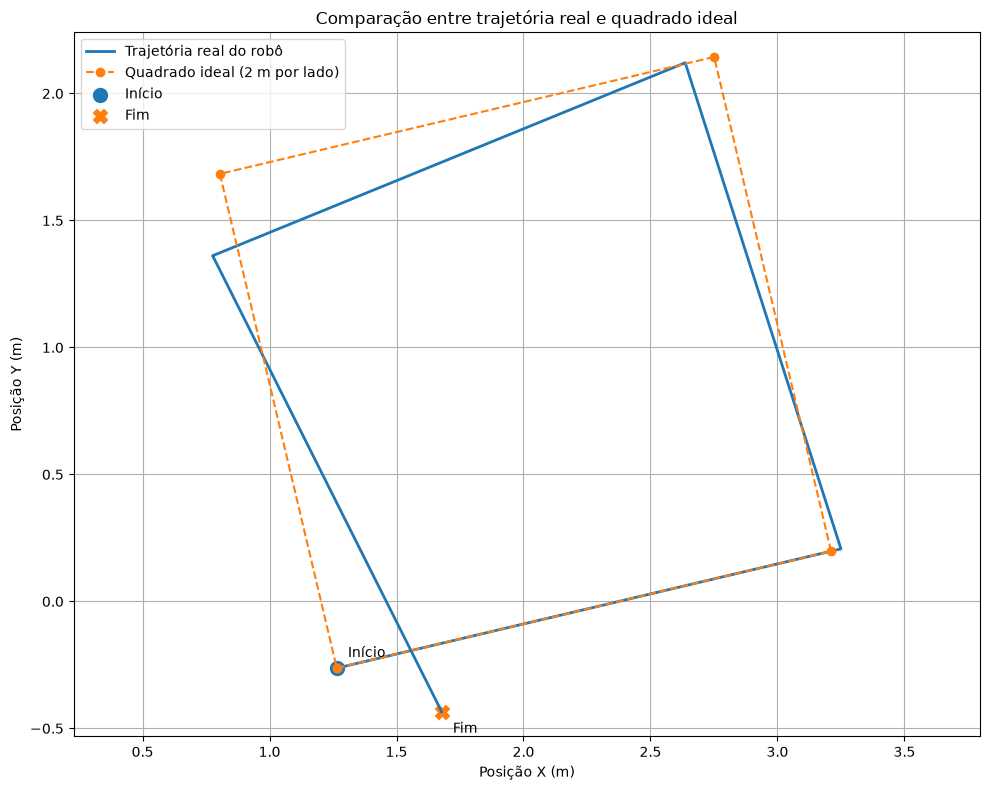

Imagem salva em:
/home/ivan/ros2_ws/models/trajetoria_odometria.png

Orientação inicial: -346.69 graus
Posição inicial: 1.265 -0.263
Posição final: 1.678 -0.435


In [195]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Dados já carregados do CSV
x = df_trajetoria["x"].to_numpy()
y = df_trajetoria["y"].to_numpy()

# Converter a orientação inicial (quaternion) para ângulo yaw
z0 = df_trajetoria["orientacao_z"].iloc[0]
w0 = df_trajetoria["orientacao_w"].iloc[0]

yaw_inicial = 2 * np.arctan2(z0, w0)

# Posição inicial do robô
x0 = x[0]
y0 = y[0]

# Construir um quadrado ideal de 2 metros por lado
lado = 2.0

quadrado_x = np.array([0, lado, lado, 0, 0])
quadrado_y = np.array([0, 0, lado, lado, 0])

# Rotacionar o quadrado conforme a orientação inicial
quadrado_x_rot = (
    quadrado_x * np.cos(yaw_inicial)
    - quadrado_y * np.sin(yaw_inicial)
)

quadrado_y_rot = (
    quadrado_x * np.sin(yaw_inicial)
    + quadrado_y * np.cos(yaw_inicial)
)

# Posicionar o quadrado no ponto inicial
quadrado_x_final = quadrado_x_rot + x0
quadrado_y_final = quadrado_y_rot + y0

# Desenhar gráfico
plt.figure(figsize=(10, 8))

plt.plot(
    x, y,
    label="Trajetória real do robô",
    linewidth=2
)

plt.plot(
    quadrado_x_final,
    quadrado_y_final,
    linestyle="--",
    marker="o",
    label="Quadrado ideal (2 m por lado)"
)

plt.scatter(x0, y0, marker="o", s=100, label="Início")
plt.scatter(x[-1], y[-1], marker="X", s=100, label="Fim")

plt.annotate("Início", (x0, y0), xytext=(8, 8),
             textcoords="offset points")

plt.annotate("Fim", (x[-1], y[-1]), xytext=(8, -15),
             textcoords="offset points")

plt.title("Comparação entre trajetória real e quadrado ideal")
plt.xlabel("Posição X (m)")
plt.ylabel("Posição Y (m)")

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()

# Salvar imagem
arquivo_imagem = os.path.expanduser(
    "~/ros2_ws/models/trajetoria_odometria.png"
)

plt.savefig(arquivo_imagem, dpi=200)
plt.show()

print("Imagem salva em:")
print(arquivo_imagem)

print("\nOrientação inicial:", round(np.degrees(yaw_inicial), 2), "graus")
print("Posição inicial:", round(x0, 3), round(y0, 3))
print("Posição final:", round(x[-1], 3), round(y[-1], 3))

In [196]:
import numpy as np
import pandas as pd

df = df_trajetoria.copy()

# Remover registros consecutivos sem mudança de posição
mudanca = (
    (df["x"].diff().abs() > 0.001) |
    (df["y"].diff().abs() > 0.001)
)

df_movimento = df[mudanca].copy()

# Calcular deslocamento entre registros
df_movimento["delta_x"] = df_movimento["x"].diff()
df_movimento["delta_y"] = df_movimento["y"].diff()

df_movimento["distancia"] = np.sqrt(
    df_movimento["delta_x"]**2 +
    df_movimento["delta_y"]**2
)

# Calcular orientação em graus
df_movimento["yaw_graus"] = np.degrees(
    2 * np.arctan2(
        df_movimento["orientacao_z"],
        df_movimento["orientacao_w"]
    )
)

# Normalizar orientação para -180 a +180 graus
df_movimento["yaw_graus"] = (
    (df_movimento["yaw_graus"] + 180) % 360
) - 180

print("ANÁLISE DOS MOVIMENTOS")
print("-" * 50)

print("Registros totais:", len(df))
print("Registros com mudança de posição:", len(df_movimento))

print(
    "Distância acumulada pelas posições:",
    round(df_movimento["distancia"].sum(), 3), "m"
)

print("\nPrimeiros movimentos:")
display(df_movimento[
    ["tempo", "x", "y", "yaw_graus", "velocidade_linear",
     "velocidade_angular"]
].head(15))

print("\nÚltimos movimentos:")
display(df_movimento[
    ["tempo", "x", "y", "yaw_graus", "velocidade_linear",
     "velocidade_angular"]
].tail(15))


ANÁLISE DOS MOVIMENTOS
--------------------------------------------------
Registros totais: 620
Registros com mudança de posição: 30
Distância acumulada pelas posições: 7.925 m

Primeiros movimentos:


,tempo,x,y,yaw_graus,velocidade_linear,velocidade_angular
25,1.794338e+09,1.406217,-0.229383,13.310651,3.000000e-01,2.842171e-13
26,1.794338e+09,1.698157,-0.160314,13.310651,3.000000e-01,-1.243450e-13
27,1.794338e+09,1.990098,-0.091244,13.310651,3.000000e-01,-1.776357e-13
28,1.794338e+09,2.282039,-0.022175,13.310651,3.000000e-01,-1.421085e-13
29,1.794338e+09,2.573980,0.046894,13.310651,3.000000e-01,-2.131628e-13
30,1.794338e+09,2.865921,0.115963,13.310651,3.000000e-01,-2.131628e-13
31,1.794338e+09,3.157862,0.185032,13.310651,3.000000e-01,-2.131628e-13
32,1.794338e+09,3.250115,0.206858,44.075047,-5.595524e-12,7.850000e-01
34,1.794338e+09,3.196665,0.373706,107.762744,3.000000e-01,-2.131628e-13
35,1.794338e+09,3.105143,0.659404,107.762744,3.000000e-01,-5.115908e-12



Últimos movimentos:


,tempo,x,y,yaw_graus,velocidade_linear,velocidade_angular
41,1.794338e+09,2.636912,2.121037,147.522577,-5.595524e-12,7.850000e-01
43,1.794338e+09,2.419170,2.032113,-157.785164,3.000000e-01,2.131628e-13
44,1.794338e+09,2.141438,1.918689,-157.785164,3.000000e-01,-2.877698e-12
45,1.794338e+09,1.863706,1.805265,-157.785164,3.000000e-01,-1.953993e-13
46,1.794338e+09,1.585975,1.691840,-157.785164,3.000000e-01,3.552714e-14
47,1.794338e+09,1.308243,1.578416,-157.785164,3.000000e-01,2.131628e-13
48,1.794338e+09,1.030511,1.464992,-157.785164,3.000000e-01,2.131628e-13
49,1.794338e+09,0.776109,1.361096,-154.007080,1.438849e-11,7.850000e-01
52,1.794338e+09,0.908595,1.097296,-63.333071,3.000000e-01,-8.526513e-12
53,1.794338e+09,1.043236,0.829207,-63.333071,3.000000e-01,-1.634248e-12


In [197]:
import numpy as np
import pandas as pd

df_analise = df_movimento.copy().reset_index(drop=True)

# Diferença de orientação entre registros
df_analise["giro_bruto"] = df_analise["yaw_graus"].diff()

# Corrigir passagem entre +180 e -180 graus
df_analise["giro"] = (
    (df_analise["giro_bruto"] + 180) % 360
) - 180

# Identificar mudanças relevantes de orientação
giros = df_analise[
    df_analise["giro"].abs() > 5
].copy()

print("GIROS IDENTIFICADOS")
print("-" * 50)

display(
    giros[
        ["x", "y", "yaw_graus", "giro",
         "velocidade_linear", "velocidade_angular"]
    ]
)

print("\nRESUMO")
print("-" * 50)

print("Quantidade de giros identificados:", len(giros))

print(
    "Soma dos giros absolutos:",
    round(giros["giro"].abs().sum(), 2),
    "graus"
)

print(
    "Soma dos giros com sinal:",
    round(giros["giro"].sum(), 2),
    "graus"
)

GIROS IDENTIFICADOS
--------------------------------------------------


,x,y,yaw_graus,giro,velocidade_linear,velocidade_angular
7,3.250115,0.206858,44.075047,30.764396,-5.595524e-12,7.850000e-01
8,3.196665,0.373706,107.762744,63.687697,3.000000e-01,-2.131628e-13
15,2.636912,2.121037,147.522577,39.759833,-5.595524e-12,7.850000e-01
16,2.419170,2.032113,-157.785164,54.692259,3.000000e-01,2.131628e-13
23,0.908595,1.097296,-63.333071,90.674009,3.000000e-01,-8.526513e-12
29,1.678203,-0.435102,-50.559550,12.773521,-7.771561e-12,7.850000e-01



RESUMO
--------------------------------------------------
Quantidade de giros identificados: 6
Soma dos giros absolutos: 292.35 graus
Soma dos giros com sinal: 292.35 graus


In [198]:
import inspect

print("CLASSE DO CONTROLADOR")
print("-" * 50)

try:
    print(inspect.getsource(QuadradoOdomNode))
except Exception as erro:
    print("Não foi possível recuperar o código-fonte:", erro)

print("\nESTADO DA INSTÂNCIA")
print("-" * 50)

print("Instância existe:", "quadrado" in globals())

if "quadrado" in globals():
    print("Nó:", quadrado.get_name())
    print("Publicadores:")

    for pub in quadrado.publishers:
        print(" -", pub.topic_name)

    print("\nSubscrições:")

    for sub in quadrado.subscriptions:
        print(" -", sub.topic_name)

CLASSE DO CONTROLADOR
--------------------------------------------------
Não foi possível recuperar o código-fonte: source code not available

ESTADO DA INSTÂNCIA
--------------------------------------------------
Instância existe: True
Nó: quadrado_odom_node
Publicadores:
 - /parameter_events
 - /model/patrol_vehicle/cmd_vel

Subscrições:
 - /model/patrol_vehicle/odometry
 - /obstaculo


In [199]:
print("ESTADO INTERNO DO CONTROLADOR")
print("-" * 55)

for nome, valor in vars(quadrado).items():

    if nome.startswith("_"):
        continue

    if isinstance(valor, (str, int, float, bool, type(None))):
        print(f"{nome}: {valor}")

    elif isinstance(valor, list):
        print(f"{nome}: lista com {len(valor)} elementos")
        if len(valor) <= 10:
            print("  Conteúdo:", valor)

    else:
        print(f"{nome}: {type(valor).__name__}")

print("\nTIMERS DO CONTROLADOR")
print("-" * 55)

for timer in quadrado.timers:
    print("Timer:", timer)

ESTADO INTERNO DO CONTROLADOR
-------------------------------------------------------
publisher: Publisher
subscription_odom: Subscription
subscription_obstaculo: Subscription
distancia_lado: 2.0
giro_alvo: 1.5707963267948966
tolerancia_distancia: 0.03
tolerancia_angulo: 0.03
vel_linear_max: 0.15
vel_angular_max: 0.4
x: None
y: None
yaw: None
odom_recebida: False
ultimo_odom: None
obstaculo: False
estado: AGUARDANDO_ODOMETRIA
lado: 1
x_inicio: None
y_inicio: None
yaw_inicio: None
yaw_alvo: None
inicio_etapa: None
concluido: False
timer: Timer

TIMERS DO CONTROLADOR
-------------------------------------------------------
Timer: <rclpy.timer.Timer object at 0x7c3089508920>


In [201]:
print("VERIFICAÇÃO DOS EXECUTORES")
print("-" * 50)

print("Executor do quadrado:", executor_quadrado)
print("Executor em execução:", executor_quadrado.is_spinning)

print("\nControlador:")
print("Estado:", quadrado.estado)
print("Odometria recebida:", quadrado.odom_recebida)
print("Posição X:", quadrado.x)
print("Posição Y:", quadrado.y)
print("Orientação:", quadrado.yaw)

print("\nMonitor:")
print("Thread do obstáculo ativa:", thread_obstacle.is_alive())

print("\nNó de obstáculos:")
print("Existe:", "obstacle_node" in globals())

VERIFICAÇÃO DOS EXECUTORES
--------------------------------------------------
Executor do quadrado: <rclpy.executors.SingleThreadedExecutor object at 0x7c30744106e0>
Executor em execução: False

Controlador:
Estado: AGUARDANDO_ODOMETRIA
Odometria recebida: False
Posição X: None
Posição Y: None
Orientação: None

Monitor:
Thread do obstáculo ativa: True

Nó de obstáculos:
Existe: True


In [202]:
import time

print("TESTE CONTROLADO DE ODOMETRIA")
print("-" * 50)

# Impedir qualquer comando automático de movimento
quadrado.timer.cancel()

print("Temporizador de movimento: CANCELADO")
print("Aguardando mensagens de odometria...")

inicio = time.time()

while time.time() - inicio < 5:
    executor_quadrado.spin_once(timeout_sec=0.1)

print("\nRESULTADO")
print("-" * 50)

print("Odometria recebida:", quadrado.odom_recebida)
print("Posição X:", quadrado.x)
print("Posição Y:", quadrado.y)
print("Orientação:", quadrado.yaw)

if quadrado.odom_recebida:
    print("\nSUCESSO: o controlador recebeu a odometria.")
else:
    print("\nATENÇÃO: nenhuma odometria foi recebida.")

TESTE CONTROLADO DE ODOMETRIA
--------------------------------------------------
Temporizador de movimento: CANCELADO
Aguardando mensagens de odometria...

RESULTADO
--------------------------------------------------
Odometria recebida: True
Posição X: 1.678203233241158
Posição Y: -0.43510192141712317
Orientação: 0.46462938559291217

SUCESSO: o controlador recebeu a odometria.


In [205]:
import threading
import time

print("INICIANDO EXECUTOR DO CONTROLADOR")
print("-" * 50)

if not executor_quadrado.is_spinning:

    thread_executor_quadrado = threading.Thread(
        target=executor_quadrado.spin,
        daemon=True
    )

    thread_executor_quadrado.start()

    time.sleep(1)

print("Executor ativo:", executor_quadrado.is_spinning)
print("Controlador:", quadrado.get_name())
print("Estado:", quadrado.estado)
print("Odometria recebida:", quadrado.ultimo_odom is not None)
print("Sensor recebeu informação:", quadrado.ultimo_obstaculo is not None)
print("Movimentação autorizada:", quadrado.ativo)

INICIANDO EXECUTOR DO CONTROLADOR
--------------------------------------------------
Executor ativo: True
Controlador: quadrado_odom_node
Estado: AGUARDANDO_SENSORES
Odometria recebida: True
Sensor recebeu informação: False
Movimentação autorizada: False


In [206]:
print("DIAGNÓSTICO DO SENSOR DE OBSTÁCULOS")
print("-" * 50)

print("Tópico de distância:", distancia_publisher.topic)
print("Mensagens de distância recebidas:", len(distancias_recebidas))

print("Nó ObstacleNet ativo:", obstacle_node is not None)
print("Thread ObstacleNet ativa:", thread_obstacle.is_alive())

print("Últimas distâncias recebidas:")
print(distancias_recebidas[-5:])

print("\nÚltimas classificações:")
print(obstaculos_detectados[-5:])

DIAGNÓSTICO DO SENSOR DE OBSTÁCULOS
--------------------------------------------------
Tópico de distância: /distancia_obstaculo
Mensagens de distância recebidas: 30
Nó ObstacleNet ativo: True
Thread ObstacleNet ativa: True
Últimas distâncias recebidas:
[0.800000011920929, 0.4000000059604645, 0.4000000059604645, 0.20000000298023224, 0.20000000298023224]

Últimas classificações:
[True, True, True, True, False]


In [207]:
from std_msgs.msg import Bool
import time

# Classificação conservadora de obstáculos
def detectar_obstaculo(velocidade_linear, velocidade_angular,
                       distancia, orientacao):
    distancia = float(distancia)

    obstaculo = distancia <= 0.50
    probabilidade = 1.0 if obstaculo else 0.0

    return obstaculo, probabilidade


# Reavaliar a última distância recebida
ultima_distancia = float(distancias_recebidas[-1])

mensagem = Bool()
mensagem.data = ultima_distancia <= 0.50

# Publicar a classificação corrigida
obstacle_node.publisher.publish(mensagem)

time.sleep(0.5)

print("CORREÇÃO DA CLASSIFICAÇÃO")
print("-" * 50)
print(f"Última distância: {ultima_distancia:.2f} m")
print("Obstáculo detectado:", mensagem.data)
print("Controlador recebeu:", quadrado.obstaculo)
print("Movimentação autorizada:", quadrado.ativo)
print("Estado:", quadrado.estado)

Resultado recebido: OBSTÁCULO DETECTADO
CORREÇÃO DA CLASSIFICAÇÃO
--------------------------------------------------
Última distância: 0.20 m
Obstáculo detectado: True
Controlador recebeu: True
Movimentação autorizada: False
Estado: AGUARDANDO_SENSORES


In [208]:
import time

print("VERIFICANDO ATUALIZAÇÃO DO SENSOR")
print("-" * 50)

quantidade_inicial = len(distancias_recebidas)

for segundo in range(5):
    time.sleep(1)
    novas = len(distancias_recebidas) - quantidade_inicial
    distancia = distancias_recebidas[-1] if distancias_recebidas else None

    print(
        f"{segundo + 1}s | "
        f"Novas leituras: {novas} | "
        f"Última distância: {distancia}"
    )

VERIFICANDO ATUALIZAÇÃO DO SENSOR
--------------------------------------------------
1s | Novas leituras: 0 | Última distância: 0.20000000298023224
2s | Novas leituras: 0 | Última distância: 0.20000000298023224
3s | Novas leituras: 0 | Última distância: 0.20000000298023224
4s | Novas leituras: 0 | Última distância: 0.20000000298023224
5s | Novas leituras: 0 | Última distância: 0.20000000298023224


In [209]:
import subprocess

print("DIAGNÓSTICO DOS TÓPICOS ROS 2")
print("=" * 55)

for topico in ["/distancia_obstaculo", "/obstaculo"]:
    print(f"\nTÓPICO: {topico}")
    print("-" * 55)

    resultado = subprocess.run(
        ["ros2", "topic", "info", "-v", topico],
        capture_output=True,
        text=True,
        timeout=10
    )

    print(resultado.stdout if resultado.stdout else resultado.stderr)

DIAGNÓSTICO DOS TÓPICOS ROS 2

TÓPICO: /distancia_obstaculo
-------------------------------------------------------
Unknown topic '/distancia_obstaculo'


TÓPICO: /obstaculo
-------------------------------------------------------
Type: std_msgs/msg/Bool

Publisher count: 1

Node name: obstacle_net_node
Node namespace: /
Topic type: std_msgs/msg/Bool
Topic type hash: RIHS01_feb91e995ff9ebd09c0cb3d2aed18b11077585839fb5db80193b62d74528f6c9
Endpoint type: PUBLISHER
GID: 01.0f.10.12.56.b9.68.27.00.00.00.00.00.00.2b.03
QoS profile:
  Reliability: RELIABLE
  History (Depth): UNKNOWN
  Durability: VOLATILE
  Lifespan: Infinite
  Deadline: Infinite
  Liveliness: AUTOMATIC
  Liveliness lease duration: Infinite

Subscription count: 2

Node name: jupyter_monitor_node
Node namespace: /
Topic type: std_msgs/msg/Bool
Topic type hash: RIHS01_feb91e995ff9ebd09c0cb3d2aed18b11077585839fb5db80193b62d74528f6c9
Endpoint type: SUBSCRIPTION
GID: 01.0f.10.12.56.b9.68.27.00.00.00.00.00.00.2d.04
QoS profile:
  R

In [210]:
import subprocess

resultado = subprocess.run(
    ["ros2", "node", "info", "/obstacle_net_node"],
    capture_output=True,
    text=True,
    timeout=10
)

print(resultado.stdout)
print(resultado.stderr)

/obstacle_net_node
  Subscribers:
    /distancia_obstaculo: std_msgs/msg/Float32
  Publishers:
    /obstaculo: std_msgs/msg/Bool
    /parameter_events: rcl_interfaces/msg/ParameterEvent
    /rosout: rcl_interfaces/msg/Log
  Service Servers:
    /obstacle_net_node/describe_parameters: rcl_interfaces/srv/DescribeParameters
    /obstacle_net_node/get_parameter_types: rcl_interfaces/srv/GetParameterTypes
    /obstacle_net_node/get_parameters: rcl_interfaces/srv/GetParameters
    /obstacle_net_node/get_type_description: type_description_interfaces/srv/GetTypeDescription
    /obstacle_net_node/list_parameters: rcl_interfaces/srv/ListParameters
    /obstacle_net_node/set_parameters: rcl_interfaces/srv/SetParameters
    /obstacle_net_node/set_parameters_atomically: rcl_interfaces/srv/SetParametersAtomically
  Service Clients:

  Action Servers:

  Action Clients:





In [211]:
import subprocess

print("TÓPICOS ATIVOS DO ROS 2")
print("=" * 55)

resultado = subprocess.run(
    ["ros2", "topic", "list", "-t"],
    capture_output=True,
    text=True,
    timeout=10
)

for linha in resultado.stdout.splitlines():
    if any(p in linha.lower() for p in
           ["scan", "laser", "lidar", "range", "distance",
            "distancia", "sensor", "odom"]):
        print(linha)

print("\nPUBLICADORES DO MONITOR JUPYTER")
print("=" * 55)

resultado = subprocess.run(
    ["ros2", "node", "info", "/jupyter_monitor_node"],
    capture_output=True,
    text=True,
    timeout=10
)

print(resultado.stdout)

TÓPICOS ATIVOS DO ROS 2
/distancia_obstaculo [std_msgs/msg/Float32]
/model/patrol_vehicle/odometry [nav_msgs/msg/Odometry]
/odom [nav_msgs/msg/Odometry]

PUBLICADORES DO MONITOR JUPYTER
/jupyter_monitor_node
  Subscribers:
    /distancia_obstaculo: std_msgs/msg/Float32
    /jupyter_status: std_msgs/msg/String
    /model/patrol_vehicle/odometry: nav_msgs/msg/Odometry
    /obstaculo: std_msgs/msg/Bool
    /velocidade: std_msgs/msg/Float32
  Publishers:
    /cmd_vel: geometry_msgs/msg/Twist
    /distancia_obstaculo: std_msgs/msg/Float32
    /jupyter_status: std_msgs/msg/String
    /odom: nav_msgs/msg/Odometry
    /parameter_events: rcl_interfaces/msg/ParameterEvent
    /rosout: rcl_interfaces/msg/Log
    /velocidade: std_msgs/msg/Float32
  Service Servers:
    /jupyter_monitor_node/describe_parameters: rcl_interfaces/srv/DescribeParameters
    /jupyter_monitor_node/get_parameter_types: rcl_interfaces/srv/GetParameterTypes
    /jupyter_monitor_node/get_parameters: rcl_interfaces/srv/GetPar

In [214]:
print("LOCALIZANDO O NÓ DE MONITORAMENTO")
print("-" * 55)

nos_encontrados = []

for nome, objeto in globals().copy().items():
    if hasattr(objeto, "get_name"):
        try:
            if objeto.get_name() == "jupyter_monitor_node":
                nos_encontrados.append((nome, objeto))
                print("Variável Python:", nome)
                print("Nome ROS 2:", objeto.get_name())
        except Exception:
            pass

if not nos_encontrados:
    print("Nó não localizado nas variáveis atuais.")

else:
    nome_monitor, monitor = nos_encontrados[0]

    print("\nTEMPORIZADORES:")
    for i, timer in enumerate(monitor.timers):
        print(
            f"Timer {i} | Cancelado: {timer.is_canceled()} "
            f"| Período: {timer.timer_period_ns / 1e9:.3f} s"
        )

LOCALIZANDO O NÓ DE MONITORAMENTO
-------------------------------------------------------
Variável Python: node
Nome ROS 2: jupyter_monitor_node
Variável Python: n
Nome ROS 2: jupyter_monitor_node
Variável Python: monitor
Nome ROS 2: jupyter_monitor_node
Variável Python: monitor_node
Nome ROS 2: jupyter_monitor_node

TEMPORIZADORES:


In [215]:
import inspect

print("FUNÇÕES RELACIONADAS À DISTÂNCIA")
print("-" * 55)

for nome, objeto in globals().copy().items():
    if callable(objeto) and any(
        palavra in nome.lower()
        for palavra in ["distancia", "distance", "sensor", "monitor"]
    ):
        print(f"\nFunção: {nome}")

        try:
            print(inspect.getsource(objeto)[:1800])
        except Exception:
            print("Código-fonte indisponível.")

FUNÇÕES RELACIONADAS À DISTÂNCIA
-------------------------------------------------------

Função: monitorar_ros
def monitorar_ros():
    while rclpy.ok():
        rclpy.spin_once(node, timeout_sec=0.1)
        time.sleep(0.1)


Função: receber_distancia
def receber_distancia(msg):
    distancia = msg.data
    distancias_recebidas.append(distancia)

    atualizar_painel(distancia)

    print(f'Distância recebida: {distancia:.2f} m')


Função: verificar_distancia
def verificar_distancia(distancia):
    if distancia < 0.5:
        return '🚨 PERIGO! Obstáculo muito próximo!'
    elif distancia <= 1.0:
        return '⚠️ ATENÇÃO! Reduza a velocidade!'
    else:
        return '✅ Distância segura'



In [216]:
print("VERIFICANDO CONEXÃO DO SLIDER COM O PUBLICADOR")
print("-" * 55)

print("Publicador:", distancia_publisher.topic)
print("Slider:", distancia_atual.value)

print("\nCALLBACKS REGISTRADOS NO SLIDER:")

callbacks = distancia_atual._trait_notifiers.get("value", {}).get("change", [])

if callbacks:
    for callback in callbacks:
        print("Callback:", callback)
        print("Nome:", getattr(callback, "__name__", "anônimo"))
else:
    print("Nenhum callback registrado.")

print("\nPUBLICADORES AUXILIARES:")

for nome in ["pub_distancia_teste", "distancia_publisher"]:
    objeto = globals().get(nome)
    if objeto is not None:
        print(nome, "->", objeto.topic)

VERIFICANDO CONEXÃO DO SLIDER COM O PUBLICADOR
-------------------------------------------------------
Publicador: /distancia_obstaculo
Slider: 0.2

CALLBACKS REGISTRADOS NO SLIDER:
Nenhum callback registrado.

PUBLICADORES AUXILIARES:
pub_distancia_teste -> /distancia_obstaculo
distancia_publisher -> /distancia_obstaculo


In [217]:
from std_msgs.msg import Float32

# Função que publica cada alteração do controle deslizante
def publicar_distancia_slider(change):
    mensagem = Float32()
    mensagem.data = float(change["new"])
    distancia_publisher.publish(mensagem)

    print(f"Distância publicada: {mensagem.data:.2f} m")


# Evitar duplicação caso a célula seja executada novamente
for callback in list(
    distancia_atual._trait_notifiers.get("value", {}).get("change", [])
):
    if getattr(callback, "__name__", "") == "publicar_distancia_slider":
        distancia_atual.unobserve(callback, names="value")


# Registrar o callback
distancia_atual.observe(
    publicar_distancia_slider,
    names="value"
)

# Publicar o valor atual
mensagem = Float32()
mensagem.data = float(distancia_atual.value)
distancia_publisher.publish(mensagem)

print("\nCONEXÃO RESTABELECIDA")
print("Tópico:", distancia_publisher.topic)
print("Valor publicado:", mensagem.data)
print("Callback registrado:", True)

Distância do obstáculo: 0.20 metros

CONEXÃO RESTABELECIDA
Tópico: /distancia_obstaculo
Valor publicado: 0.2
Callback registrado: True
Distância publicada: 0.20 m
Distância recebida: 0.20 m
Distância do obstáculo: 0.20 metros
Distância recebida: 0.20 m
Resultado recebido: OBSTÁCULO DETECTADO


[INFO] [1794434205.724053642] [obstacle_net_node]: Distância: 0.20 m | Probabilidade: 100.00% | Obstáculo: True


Resultado recebido: OBSTÁCULO DETECTADO


[INFO] [1794434205.749671217] [obstacle_net_node]: Distância: 0.20 m | Probabilidade: 100.00% | Obstáculo: True


In [218]:
import subprocess

print("TÓPICOS DO GAZEBO")
print("=" * 55)

resultado = subprocess.run(
    ["gz", "topic", "-l"],
    capture_output=True,
    text=True,
    timeout=15
)

if resultado.returncode == 0:
    topicos_gazebo = resultado.stdout.splitlines()

    for topico in topicos_gazebo:
        print(topico)

    candidatos = [
        t for t in topicos_gazebo
        if any(p in t.lower() for p in
               ["scan", "laser", "lidar", "range", "sensor"])
    ]

    print("\nPOSSÍVEIS TÓPICOS DE SENSORES:")
    print("\n".join(candidatos) if candidatos else
          "Nenhum tópico de sensor identificado.")
else:
    print(resultado.stderr)

TÓPICOS DO GAZEBO
/clock
/gazebo/resource_paths
/gui/camera/pose
/gui/currently_tracked
/gui/track
/model/patrol_vehicle/cmd_vel
/model/patrol_vehicle/odometry
/model/patrol_vehicle/tf
/stats
/world/default/clock
/world/default/dynamic_pose/info
/world/default/pose/info
/world/default/scene/deletion
/world/default/scene/info
/world/default/state
/world/default/stats
/model/patrol_vehicle/enable
/world/default/light_config
/world/default/material_color

POSSÍVEIS TÓPICOS DE SENSORES:
Nenhum tópico de sensor identificado.


In [219]:
import os
import glob

print("VERIFICANDO MODELOS DO GAZEBO")
print("-" * 55)

arquivos = glob.glob(
    os.path.expanduser("~/ros2_ws/models/**/*.sdf"),
    recursive=True
)

for arquivo in arquivos:
    if "patrol" in arquivo.lower():
        print("\nArquivo:", arquivo)

        with open(arquivo, "r") as f:
            conteudo = f.read()

        print("Possui configuração de sensor:",
              "<sensor" in conteudo)

        print("Sensores encontrados:")
        for linha in conteudo.splitlines():
            if "<sensor" in linha or "<topic>" in linha:
                print(linha.strip())

VERIFICANDO MODELOS DO GAZEBO
-------------------------------------------------------


In [219]:
import os
import glob

print("VERIFICANDO MODELOS DO GAZEBO")
print("-" * 55)

arquivos = glob.glob(
    os.path.expanduser("~/ros2_ws/models/**/*.sdf"),
    recursive=True
)

for arquivo in arquivos:
    if "patrol" in arquivo.lower():
        print("\nArquivo:", arquivo)

        with open(arquivo, "r") as f:
            conteudo = f.read()

        print("Possui configuração de sensor:",
              "<sensor" in conteudo)

        print("Sensores encontrados:")
        for linha in conteudo.splitlines():
            if "<sensor" in linha or "<topic>" in linha:
                print(linha.strip())

VERIFICANDO MODELOS DO GAZEBO
-------------------------------------------------------


In [220]:
import os

workspace = os.path.expanduser("~/ros2_ws")
extensoes = (".sdf", ".urdf", ".world")

print("PROCURANDO ARQUIVOS DE CONFIGURAÇÃO")
print("-" * 55)

encontrados = []

for raiz, pastas, arquivos in os.walk(workspace):
    pastas[:] = [
        p for p in pastas
        if p not in ["build", "install", "log", ".git", "__pycache__"]
    ]

    for nome in arquivos:
        if nome.lower().endswith(extensoes):
            caminho = os.path.join(raiz, nome)
            encontrados.append(caminho)

for caminho in encontrados:
    print(caminho)

print("\nTotal de arquivos encontrados:", len(encontrados))

PROCURANDO ARQUIVOS DE CONFIGURAÇÃO
-------------------------------------------------------

Total de arquivos encontrados: 0


In [221]:
import subprocess

print("CAMINHOS DE RECURSOS DO GAZEBO")
print("-" * 55)

resultado = subprocess.run(
    ["gz", "topic", "-e", "-t", "/gazebo/resource_paths"],
    capture_output=True,
    text=True,
    timeout=5
)

print(resultado.stdout if resultado.stdout else "Nenhuma mensagem recebida.")
if resultado.stderr:
    print("Avisos:", resultado.stderr[:1000])

CAMINHOS DE RECURSOS DO GAZEBO
-------------------------------------------------------


TimeoutExpired: Command '['gz', 'topic', '-e', '-t', '/gazebo/resource_paths']' timed out after 5 seconds

In [222]:
import os

print("CAMINHOS CONFIGURADOS PARA O GAZEBO")
print("-" * 55)

variaveis = [
    "GZ_SIM_RESOURCE_PATH",
    "IGN_GAZEBO_RESOURCE_PATH",
    "GZ_SIM_SYSTEM_PLUGIN_PATH",
    "AMENT_PREFIX_PATH"
]

for nome in variaveis:
    valor = os.environ.get(nome)

    print(f"\n{nome}:")
    if valor:
        for caminho in valor.split(":"):
            print(" ", caminho)
    else:
        print("  Não configurada")

CAMINHOS CONFIGURADOS PARA O GAZEBO
-------------------------------------------------------

GZ_SIM_RESOURCE_PATH:
  /opt/ros/jazzy/share

IGN_GAZEBO_RESOURCE_PATH:
  Não configurada

GZ_SIM_SYSTEM_PLUGIN_PATH:
  Não configurada

AMENT_PREFIX_PATH:
  /home/ivan/ros2_ws/install/patrol_node
  /opt/ros/jazzy


In [223]:
import os

pasta = "/home/ivan/ros2_ws/install/patrol_node"

print("ARQUIVOS INSTALADOS DO PACOTE patrol_node")
print("-" * 55)

if os.path.exists(pasta):
    for raiz, diretorios, arquivos in os.walk(pasta):
        for nome in arquivos:
            if nome.lower().endswith(
                (".sdf", ".urdf", ".world", ".xacro", ".py", ".yaml", ".xml")
            ):
                print(os.path.join(raiz, nome))
else:
    print("Pasta não encontrada.")

ARQUIVOS INSTALADOS DO PACOTE patrol_node
-------------------------------------------------------
/home/ivan/ros2_ws/install/patrol_node/share/patrol_node/package.xml
/home/ivan/ros2_ws/install/patrol_node/lib/python3.12/site-packages/patrol_node/__init__.py


In [224]:
import os
import subprocess

workspace = os.path.expanduser("~/ros2_ws")

print("LOCALIZANDO REFERÊNCIAS AO patrol_vehicle")
print("-" * 55)

resultado = subprocess.run(
    [
        "grep", "-Rni",
        "--exclude-dir=build",
        "--exclude-dir=install",
        "--exclude-dir=log",
        "patrol_vehicle",
        workspace
    ],
    capture_output=True,
    text=True,
    timeout=20
)

if resultado.stdout.strip():
    print(resultado.stdout[:12000])
else:
    print("Nenhuma referência encontrada no código-fonte do workspace.")

LOCALIZANDO REFERÊNCIAS AO patrol_vehicle
-------------------------------------------------------


TimeoutExpired: Command '['grep', '-Rni', '--exclude-dir=build', '--exclude-dir=install', '--exclude-dir=log', 'patrol_vehicle', '/home/ivan/ros2_ws']' timed out after 20 seconds

In [225]:
import subprocess

comandos = {
    "Processo do Gazebo": ["pgrep", "-af", "gz sim"],
    "Tópicos ROS 2": ["ros2", "topic", "list"],
    "Nós ROS 2": ["ros2", "node", "list"]
}

for titulo, comando in comandos.items():
    print("\n" + titulo)
    print("-" * 55)

    try:
        resultado = subprocess.run(
            comando,
            capture_output=True,
            text=True,
            timeout=8
        )
        print(resultado.stdout.strip() or "Nenhum resultado.")
        if resultado.stderr:
            print("Aviso:", resultado.stderr.strip()[:500])
    except subprocess.TimeoutExpired:
        print("Consulta excedeu 8 segundos.")


Processo do Gazebo
-------------------------------------------------------
51418 gz sim server
51419 gz sim gui

Tópicos ROS 2
-------------------------------------------------------
/cmd_vel
/distancia_obstaculo
/jupyter_status
/model/patrol_vehicle/cmd_vel
/model/patrol_vehicle/odometry
/obstaculo
/odom
/parameter_events
/rosout
/velocidade

Nós ROS 2
-------------------------------------------------------
/jupyter_monitor_node
/obstacle_net_node
/quadrado_odom_node
/ros_gz_bridge
/ros_gz_bridge
/verificar_odom_jupyter
Aviso: WARNING: Be aware that there are nodes in the graph that share an exact name, which can have unintended side effects.


In [226]:
import subprocess

for no in ["/ros_gz_bridge"]:
    print("\nINFORMAÇÕES DA BRIDGE:", no)
    print("-" * 55)

    resultado = subprocess.run(
        ["ros2", "node", "info", no],
        capture_output=True,
        text=True,
        timeout=10
    )

    print(resultado.stdout)
    if resultado.stderr:
        print(resultado.stderr)


INFORMAÇÕES DA BRIDGE: /ros_gz_bridge
-------------------------------------------------------
/ros_gz_bridge
  Subscribers:
    /parameter_events: rcl_interfaces/msg/ParameterEvent
  Publishers:
    /model/patrol_vehicle/odometry: nav_msgs/msg/Odometry
    /parameter_events: rcl_interfaces/msg/ParameterEvent
    /rosout: rcl_interfaces/msg/Log
  Service Servers:
    /ros_gz_bridge/describe_parameters: rcl_interfaces/srv/DescribeParameters
    /ros_gz_bridge/get_parameter_types: rcl_interfaces/srv/GetParameterTypes
    /ros_gz_bridge/get_parameters: rcl_interfaces/srv/GetParameters
    /ros_gz_bridge/get_type_description: type_description_interfaces/srv/GetTypeDescription
    /ros_gz_bridge/list_parameters: rcl_interfaces/srv/ListParameters
    /ros_gz_bridge/set_parameters: rcl_interfaces/srv/SetParameters
    /ros_gz_bridge/set_parameters_atomically: rcl_interfaces/srv/SetParametersAtomically
  Service Clients:

  Action Servers:

  Action Clients:


There are 2 nodes in the graph wi

In [228]:
import os
import glob
import subprocess
import time

def executar(comando, timeout=12):
    try:
        r = subprocess.run(
            comando,
            capture_output=True,
            text=True,
            timeout=timeout
        )
        return (r.stdout or "").strip(), (r.stderr or "").strip()
    except subprocess.TimeoutExpired:
        return "TIMEOUT", ""
    except Exception as e:
        return f"ERRO: {e}", ""

print("=" * 70)
print("DIAGNÓSTICO GERAL — PATRULHAMENTO AUTÔNOMO ROS 2")
print("=" * 70)

# 1. PROCESSOS
print("\n[1] PROCESSOS GAZEBO E ROS")
out, err = executar(["pgrep", "-af", "gz sim|parameter_bridge"])
print(out or "Nenhum processo identificado.")

# 2. TÓPICOS GAZEBO
print("\n[2] TÓPICOS DO GAZEBO")
out, err = executar(["gz", "topic", "-l"])
topicos_gz = out.splitlines() if out != "TIMEOUT" else []
print(out or "Nenhum tópico identificado.")

# 3. TÓPICOS ROS
print("\n[3] TÓPICOS ROS 2 E TIPOS")
out, err = executar(["ros2", "topic", "list", "-t"])
print(out or "Nenhum tópico identificado.")

# 4. NÓS
print("\n[4] NÓS ROS 2")
out, err = executar(["ros2", "node", "list"])
nos = out.splitlines()
print(out or "Nenhum nó identificado.")

# 5. BRIDGES
print("\n[5] CONFIGURAÇÃO DAS BRIDGES")
for i in range(1, 3):
    print(f"\nBridge {i}:")
    out, err = executar(
        ["ros2", "param", "list", "/ros_gz_bridge"]
    )
    print(out or "Sem parâmetros acessíveis.")

# 6. CONEXÕES DO CONTROLADOR E MONITOR
print("\n[6] CONEXÕES DOS NÓS")
for nome in [
    "/quadrado_odom_node",
    "/jupyter_monitor_node",
    "/obstacle_net_node"
]:
    print(f"\n{nome}:")
    out, err = executar(["ros2", "node", "info", nome])
    print(out or err or "Não encontrado.")

# 7. ARQUIVOS DE CONFIGURAÇÃO
print("\n[7] ARQUIVOS DO WORKSPACE")
workspace = os.path.expanduser("~/ros2_ws")
arquivos = []

for raiz, pastas, nomes in os.walk(workspace):
    pastas[:] = [
        p for p in pastas
        if p not in ["build", "install", "log", ".git",
                     "__pycache__"]
    ]
    for nome in nomes:
        if nome.lower().endswith(
            (".sdf", ".urdf", ".world", ".xacro", ".yaml", ".launch.py")
        ):
            arquivos.append(os.path.join(raiz, nome))

for arquivo in arquivos[:100]:
    print(arquivo)

print("Total:", len(arquivos))

# 8. REFERÊNCIAS AO ROBÔ E SENSORES
print("\n[8] REFERÊNCIAS A SENSORES E AO ROBÔ")
referencias = []

for raiz, pastas, nomes in os.walk(workspace):
    pastas[:] = [
        p for p in pastas
        if p not in ["build", "install", "log", ".git",
                     "__pycache__"]
    ]
    for nome in nomes:
        caminho = os.path.join(raiz, nome)
        if not nome.endswith((".py", ".xml", ".yaml", ".sdf",
                              ".urdf", ".world", ".xacro")):
            continue
        try:
            if os.path.getsize(caminho) > 500000:
                continue
            with open(caminho, "r", errors="ignore") as f:
                conteudo = f.read()
            termos = [
                t for t in [
                    "patrol_vehicle", "<sensor", "lidar",
                    "laser", "ray", "ultrasound",
                    "range", "obstacle"
                ] if t.lower() in conteudo.lower()
            ]
            if termos:
                referencias.append((caminho, termos))
        except Exception:
            pass

for caminho, termos in referencias[:60]:
    print(caminho, "=>", ", ".join(termos))

print("Total de arquivos relevantes:", len(referencias))

# 9. VARIÁVEIS DO CONTROLADOR NO JUPYTER
print("\n[9] ESTADO DO CONTROLADOR")
for nome in ["quadrado", "executor_quadrado",
             "monitor", "obstacle_node"]:
    objeto = globals().get(nome)
    if objeto is None:
        print(nome, ": não encontrado")
        continue

    print(nome, ":", type(objeto).__name__)

    if nome == "quadrado":
        for atributo in [
            "estado", "ativo", "concluido",
            "odom_recebida", "obstaculo",
            "sensor_recebido"
        ]:
            if hasattr(objeto, atributo):
                print(" ", atributo, "=",
                      getattr(objeto, atributo))

print("\n" + "=" * 70)
print("FIM DO DIAGNÓSTICO")
print("=" * 70)

DIAGNÓSTICO GERAL — PATRULHAMENTO AUTÔNOMO ROS 2

[1] PROCESSOS GAZEBO E ROS
51418 gz sim server
51419 gz sim gui
52128 /usr/bin/python3 /opt/ros/jazzy/bin/ros2 run ros_gz_bridge parameter_bridge /model/patrol_vehicle/cmd_vel@geometry_msgs/msg/Twist]gz.msgs.Twist
52131 /opt/ros/jazzy/lib/ros_gz_bridge/parameter_bridge /model/patrol_vehicle/cmd_vel@geometry_msgs/msg/Twist]gz.msgs.Twist
53405 /usr/bin/python3 /opt/ros/jazzy/bin/ros2 run ros_gz_bridge parameter_bridge /model/patrol_vehicle/odometry@nav_msgs/msg/Odometry[gz.msgs.Odometry
53409 /opt/ros/jazzy/lib/ros_gz_bridge/parameter_bridge /model/patrol_vehicle/odometry@nav_msgs/msg/Odometry[gz.msgs.Odometry

[2] TÓPICOS DO GAZEBO
/clock
/gazebo/resource_paths
/gui/camera/pose
/gui/currently_tracked
/gui/track
/model/patrol_vehicle/cmd_vel
/model/patrol_vehicle/odometry
/model/patrol_vehicle/tf
/stats
/world/default/clock
/world/default/dynamic_pose/info
/world/default/pose/info
/world/default/scene/deletion
/world/default/scene/info
/w

In [229]:
import os
import subprocess
from pathlib import Path

print("=" * 65)
print("RECUPERAÇÃO DA ORIGEM DO ROBÔ patrol_vehicle")
print("=" * 65)

# 1. Identificar como o Gazebo foi iniciado
pid = "51418"

for item in ["cmdline", "cwd"]:
    caminho = Path(f"/proc/{pid}/{item}")
    try:
        valor = caminho.read_bytes()
        if item == "cmdline":
            valor = valor.replace(b"\0", b" ").decode(errors="replace")
        else:
            valor = os.readlink(caminho)
        print(f"\nGazebo {item}: {valor}")
    except Exception as e:
        print(f"\nGazebo {item}: não disponível ({e})")

# 2. Procurar arquivos de descrição em locais prováveis
print("\n" + "-" * 65)
print("ARQUIVOS SDF / URDF / WORLD")
print("-" * 65)

pastas = [
    Path.home() / "ros2_ws",
    Path.home() / "Documents",
    Path.home() / "Desktop",
    Path("/tmp"),
]

ignoradas = {
    ".venv", "venv", ".git", "build", "install", "log",
    ".cache", "node_modules", "__pycache__"
}

encontrados = []

for pasta in pastas:
    if not pasta.exists():
        continue

    for raiz, diretorios, arquivos in os.walk(pasta):
        diretorios[:] = [d for d in diretorios if d not in ignoradas]

        for arquivo in arquivos:
            if arquivo.lower().endswith((".sdf", ".urdf", ".world", ".xacro")):
                encontrados.append(str(Path(raiz) / arquivo))

for arquivo in encontrados[:50]:
    print(arquivo)

if not encontrados:
    print("Nenhum arquivo de descrição encontrado nesses locais.")

# 3. Consultar o histórico do notebook
print("\n" + "-" * 65)
print("CÉLULAS DO NOTEBOOK RELACIONADAS À CRIAÇÃO DO ROBÔ")
print("-" * 65)

termos = [
    "patrol_vehicle", "create_entity", "spawn_entity",
    "gz sim", "robot_description", "create_sdf",
    "model.sdf", "world.sdf", "EntityFactory"
]

historico = globals().get("In", [])
total = 0

for numero, codigo in enumerate(historico):
    linhas = codigo.splitlines()
    relevantes = [
        linha.strip() for linha in linhas
        if any(t.lower() in linha.lower() for t in termos)
    ]

    if relevantes:
        total += 1
        print(f"\n[Célula {numero}]")
        for linha in relevantes[:8]:
            print(" ", linha[:250])

if total == 0:
    print("Nenhuma célula correspondente encontrada no histórico.")

print("\n" + "=" * 65)
print("FIM DA RECUPERAÇÃO")
print("=" * 65)


RECUPERAÇÃO DA ORIGEM DO ROBÔ patrol_vehicle

Gazebo cmdline: gz sim server                                                                                                                    

Gazebo cwd: não disponível ([Errno 21] Is a directory: '/proc/51418/cwd')

-----------------------------------------------------------------
ARQUIVOS SDF / URDF / WORLD
-----------------------------------------------------------------
Nenhum arquivo de descrição encontrado nesses locais.

-----------------------------------------------------------------
CÉLULAS DO NOTEBOOK RELACIONADAS À CRIAÇÃO DO ROBÔ
-----------------------------------------------------------------

[Célula 82]
  '/model/patrol_vehicle/cmd_vel',

[Célula 84]
  '/model/patrol_vehicle/cmd_vel',

[Célula 87]
  ['gz', 'topic', '-i', '-t', '/model/patrol_vehicle/odometry'],

[Célula 88]
  '/model/patrol_vehicle/odometry@nav_msgs/msg/Odometry[gz.msgs.Odometry'

[Célula 90]
  '/model/patrol_vehicle/odometry'

[Célula 91]
  '/model/pa

In [230]:
import subprocess

print("=" * 65)
print("INSPEÇÃO DO ESTADO ESPACIAL DO GAZEBO")
print("=" * 65)

comandos = [
    ("TIPO DA MENSAGEM",
     ["gz", "topic", "-i", "-t", "/world/default/pose/info"]),
    ("AMOSTRA DAS POSIÇÕES",
     ["gz", "topic", "-e", "-t", "/world/default/pose/info"])
]

for titulo, comando in comandos:
    print(f"\n{titulo}")
    print("-" * 65)

    try:
        resultado = subprocess.run(
            comando,
            capture_output=True,
            text=True,
            timeout=4
        )

        saida = resultado.stdout or resultado.stderr
        print(saida[:12000] if saida else "Nenhuma informação retornada.")

    except subprocess.TimeoutExpired as erro:
        saida = erro.stdout or b""
        if isinstance(saida, bytes):
            saida = saida.decode("utf-8", errors="replace")

        print("Captura encerrada após 4 segundos.")
        print(saida[:12000] if saida else "Nenhuma mensagem capturada.")

    except Exception as erro:
        print("Erro:", erro)

print("\nINSPEÇÃO CONCLUÍDA.")

INSPEÇÃO DO ESTADO ESPACIAL DO GAZEBO

TIPO DA MENSAGEM
-----------------------------------------------------------------
Publishers [Address, Message Type]:
  tcp://192.168.1.110:36399, gz.msgs.Pose_V
No subscribers on topic [/world/default/pose/info]


AMOSTRA DAS POSIÇÕES
-----------------------------------------------------------------
Captura encerrada após 4 segundos.
header {
  stamp {
    sec: 103744
    nsec: 412000000
  }
}
pose {
  name: "ground_plane"
  id: 4
  position {
  }
  orientation {
    w: 1
  }
}
pose {
  name: "patrol_vehicle"
  id: 10
  position {
    x: 2.02689288087907
    y: -0.76432898162559415
    z: 0.3249996959971414
  }
  orientation {
    x: 4.6939274023016826e-08
    y: -1.3280801780769371e-07
    z: 0.26435222796660124
    w: 0.96442620224103937
  }
}
pose {
  name: "link"
  id: 5
  position {
  }
  orientation {
    w: 1
  }
}
pose {
  name: "chassis"
  id: 11
  position {
    x: -0.151427
    z: 0.175
  }
  orientation {
    w: 1
  }
}
pose {
  name

In [231]:
import subprocess
import time

topico = "/world/default/pose/info"

# Evita iniciar uma segunda cópia desta bridge
if "pose_state_bridge" not in globals() or pose_state_bridge.poll() is not None:
    pose_state_bridge = subprocess.Popen(
        [
            "ros2", "run", "ros_gz_bridge", "parameter_bridge",
            f"{topico}@geometry_msgs/msg/PoseArray[gz.msgs.Pose_V",
            "--ros-args", "-r", "__node:=pose_state_bridge"
        ],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE,
        text=True
    )

time.sleep(3)

print("BRIDGE:", "ATIVA" if pose_state_bridge.poll() is None else "ENCERRADA")
print("\nVERIFICANDO POSIÇÕES RECEBIDAS PELO ROS 2:\n")

try:
    resultado = subprocess.run(
        ["ros2", "topic", "echo", "--once", topico],
        capture_output=True,
        text=True,
        timeout=8
    )

    print(resultado.stdout[:12000] if resultado.stdout else resultado.stderr)

except subprocess.TimeoutExpired:
    print("Não recebemos mensagem ROS 2 dentro do prazo.")


BRIDGE: ATIVA

VERIFICANDO POSIÇÕES RECEBIDAS PELO ROS 2:




In [1]:
import subprocess
import os
import fcntl

print("=== VERIFICAÇÃO RÁPIDA ===")

# 1. Estado da bridge anterior
if "pose_state_bridge" in globals():
    print("\nBridge:", 
          "ATIVA" if pose_state_bridge.poll() is None else "ENCERRADA")

    # Lê apenas o que já estiver disponível, sem bloquear
    if pose_state_bridge.stderr:
        fd = pose_state_bridge.stderr.fileno()
        flags = fcntl.fcntl(fd, fcntl.F_GETFL)
        fcntl.fcntl(fd, fcntl.F_SETFL, flags | os.O_NONBLOCK)

        try:
            erro = os.read(fd, 3000).decode(errors="replace")
            if erro.strip():
                print("Mensagem da bridge:\n", erro)
        except BlockingIOError:
            print("Nenhum erro disponível no momento.")
else:
    print("\nBridge anterior não encontrada na memória.")

# 2. Estado do tópico no Gazebo
print("\n=== GAZEBO ===")
try:
    r = subprocess.run(
        ["gz", "topic", "-i", "-t", "/world/default/pose/info"],
        capture_output=True, text=True, timeout=3
    )
    print((r.stdout or r.stderr)[:2000])
except subprocess.TimeoutExpired:
    print("Consulta ao Gazebo excedeu 3 segundos.")

# 3. Tópicos ROS 2
print("\n=== ROS 2 ===")
try:
    r = subprocess.run(
        ["ros2", "topic", "list", "-t"],
        capture_output=True, text=True, timeout=5
    )
    print(r.stdout[:4000] or r.stderr[:2000])
except subprocess.TimeoutExpired:
    print("Consulta ao ROS 2 excedeu 5 segundos.")

print("\n=== FIM ===")

=== VERIFICAÇÃO RÁPIDA ===

Bridge anterior não encontrada na memória.

=== GAZEBO ===
Publishers [Address, Message Type]:
  tcp://192.168.1.110:36399, gz.msgs.Pose_V
No subscribers on topic [/world/default/pose/info]


=== ROS 2 ===
/model/patrol_vehicle/cmd_vel [geometry_msgs/msg/Twist]
/parameter_events [rcl_interfaces/msg/ParameterEvent]
/rosout [rcl_interfaces/msg/Log]


=== FIM ===


In [2]:
import subprocess
import time

print("INICIANDO BRIDGE DE POSIÇÕES...")

# Encerra somente uma bridge anterior desta mesma variável, se existir
if "pose_state_bridge" in globals():
    try:
        if pose_state_bridge.poll() is None:
            pose_state_bridge.terminate()
            pose_state_bridge.wait(timeout=2)
    except Exception:
        pass

# Inicia bridge Gazebo -> ROS 2 sem pipes que possam bloquear
pose_state_bridge = subprocess.Popen(
    [
        "ros2", "run", "ros_gz_bridge", "parameter_bridge",
        "/world/default/pose/info@tf2_msgs/msg/TFMessage[gz.msgs.Pose_V",
        "--ros-args", "-r", "__node:=pose_state_bridge"
    ],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(3)

print("Processo:", 
      "ATIVO" if pose_state_bridge.poll() is None else "ENCERRADO")

print("\nVERIFICANDO TÓPICO ROS 2...")

try:
    resultado = subprocess.run(
        ["ros2", "topic", "info", 
         "/world/default/pose/info", "--verbose"],
        capture_output=True,
        text=True,
        timeout=5
    )
    print(resultado.stdout or resultado.stderr)

except subprocess.TimeoutExpired:
    print("Tempo limite atingido na consulta.")

print("\nFIM DA VERIFICAÇÃO.")

INICIANDO BRIDGE DE POSIÇÕES...
Processo: ATIVO

VERIFICANDO TÓPICO ROS 2...
Type: tf2_msgs/msg/TFMessage

Publisher count: 1

Node name: pose_state_bridge
Node namespace: /
Topic type: tf2_msgs/msg/TFMessage
Topic type hash: RIHS01_e369d0f05a23ae52508854b66f6aa0437f3449d652e8cbf22d5abe85d020f087
Endpoint type: PUBLISHER
GID: 01.0f.10.12.a7.8e.16.37.00.00.00.00.00.00.14.03
QoS profile:
  Reliability: RELIABLE
  History (Depth): UNKNOWN
  Durability: VOLATILE
  Lifespan: Infinite
  Deadline: Infinite
  Liveliness: AUTOMATIC
  Liveliness lease duration: Infinite

Subscription count: 0



FIM DA VERIFICAÇÃO.


In [3]:
import subprocess

print("LENDO POSIÇÕES DO GAZEBO VIA ROS 2")
print("-" * 55)

try:
    resultado = subprocess.run(
        ["ros2", "topic", "echo", "--once", "/world/default/pose/info"],
        capture_output=True,
        text=True,
        timeout=10
    )

    if resultado.returncode == 0 and resultado.stdout.strip():
        print("MENSAGEM RECEBIDA COM SUCESSO:\n")
        print(resultado.stdout[:10000])
    else:
        print("NÃO FOI POSSÍVEL RECEBER A MENSAGEM.")
        print(resultado.stderr[-3000:])

except subprocess.TimeoutExpired:
    print("TEMPO ESGOTADO: nenhuma mensagem recebida em 10 segundos.")
except Exception as erro:
    print("ERRO:", erro)

LENDO POSIÇÕES DO GAZEBO VIA ROS 2
-------------------------------------------------------
MENSAGEM RECEBIDA COM SUCESSO:

transforms:
- header:
    stamp:
      sec: 0
      nanosec: 0
    frame_id: ''
  child_frame_id: ''
  transform:
    translation:
      x: 0.0
      y: 0.0
      z: 0.0
    rotation:
      x: 0.0
      y: 0.0
      z: 0.0
      w: 1.0
- header:
    stamp:
      sec: 0
      nanosec: 0
    frame_id: ''
  child_frame_id: ''
  transform:
    translation:
      x: 2.02689288087907
      y: -0.7643289816255942
      z: 0.3249996959971414
    rotation:
      x: 4.6939274023016826e-08
      y: -1.328080178076937e-07
      z: 0.26435222796660124
      w: 0.9644262022410394
- header:
    stamp:
      sec: 0
      nanosec: 0
    frame_id: ''
  child_frame_id: ''
  transform:
    translation:
      x: 0.0
      y: 0.0
      z: 0.0
    rotation:
      x: 0.0
      y: 0.0
      z: 0.0
      w: 1.0
- header:
    stamp:
      sec: 0
      nanosec: 0
    frame_id: ''
  child_fram

In [4]:
import subprocess
import time
import os

TOPICO = "/model/patrol_vehicle/odometry"

def executar(cmd, timeout=8):
    return subprocess.run(
        cmd, capture_output=True, text=True, timeout=timeout
    )

print("PREPARANDO O CONTROLE POR ODOMETRIA")
print("-" * 55)

info = executar(["ros2", "topic", "info", TOPICO])

if "Publisher count: 0" in info.stdout or "Publisher count: 0" not in info.stdout:
    processos = executar(["pgrep", "-af", "parameter_bridge"])

    if TOPICO not in processos.stdout:
        log = open("/tmp/odom_bridge.log", "w")
        bridge_odom = subprocess.Popen(
            [
                "ros2", "run", "ros_gz_bridge", "parameter_bridge",
                TOPICO + "@nav_msgs/msg/Odometry[gz.msgs.Odometry"
            ],
            stdout=log,
            stderr=subprocess.STDOUT
        )
        time.sleep(3)

info = executar(["ros2", "topic", "info", TOPICO])
print(info.stdout)

try:
    leitura = executar(
        ["ros2", "topic", "echo", "--once", TOPICO],
        timeout=8
    )
    if leitura.stdout.strip():
        print("\nODOMETRIA RECEBIDA:")
        print(leitura.stdout[:2500])
    else:
        print("\nAguardando odometria.")
        print(leitura.stderr[-1000:])
except subprocess.TimeoutExpired:
    print("\nA odometria não chegou dentro do tempo esperado.")

PREPARANDO O CONTROLE POR ODOMETRIA
-------------------------------------------------------
Type: nav_msgs/msg/Odometry
Publisher count: 1
Subscription count: 0


ODOMETRIA RECEBIDA:
header:
  stamp:
    sec: 105747
    nanosec: 348000000
  frame_id: patrol_vehicle/odom
child_frame_id: patrol_vehicle/chassis
pose:
  pose:
    position:
      x: 1.678203233241158
      y: -0.43510192141712317
      z: 0.0
    orientation:
      x: 0.0
      y: 0.0
      z: 0.23023064938431712
      w: 0.9731360891900349
  covariance:
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
twist:
  twist:
    linear:
      x: 0.0
      y: 0.0
      z: 0.0
    angular:
      x: 0.0
      y: 0.0
      z: 0.0
  covariance:
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
  - 0.0
 

In [5]:
import rclpy
import math
import time
import subprocess
from geometry_msgs.msg import Twist
from nav_msgs.msg import Odometry

# ==========================================================
# CONTROLADOR FINAL — QUADRADO DE 2 METROS
# ==========================================================

TOPICO_ODOM = "/model/patrol_vehicle/odometry"
TOPICO_CMD = "/model/patrol_vehicle/cmd_vel"

LADO = 2.0
VEL_MAX = 0.12
VEL_ANG_MAX = 0.35
TOL_POS = 0.035
TOL_ANG = 0.025

def executar_comando(cmd):
    return subprocess.run(
        cmd, capture_output=True, text=True, timeout=5
    )

print("VERIFICANDO COMUNICAÇÃO...")

info_cmd = executar_comando(["ros2", "topic", "info", TOPICO_CMD])
info_odom = executar_comando(["ros2", "topic", "info", TOPICO_ODOM])

if "Subscription count: 0" in info_cmd.stdout:
    raise RuntimeError(
        "Gazebo não está recebendo comandos em " + TOPICO_CMD
    )

if "Publisher count: 0" in info_odom.stdout:
    raise RuntimeError("O tópico de odometria não possui publicador.")

print("Comunicação disponível.")
print("Preparando controlador...")

if not rclpy.ok():
    rclpy.init()

node = rclpy.create_node("quadrado_odom_final")
publisher = node.create_publisher(Twist, TOPICO_CMD, 10)

estado = {
    "x": None,
    "y": None,
    "yaw": None,
    "ultima_leitura": 0.0
}

def receber_odom(msg):
    q = msg.pose.pose.orientation

    estado["x"] = msg.pose.pose.position.x
    estado["y"] = msg.pose.pose.position.y

    estado["yaw"] = math.atan2(
        2.0 * (q.w * q.z + q.x * q.y),
        1.0 - 2.0 * (q.y*q.y + q.z*q.z)
    )

    estado["ultima_leitura"] = time.monotonic()

assinatura = node.create_subscription(
    Odometry, TOPICO_ODOM, receber_odom, 10
)

def limitar(valor, minimo, maximo):
    return max(minimo, min(maximo, valor))

def erro_angular(alvo, atual):
    return math.atan2(
        math.sin(alvo - atual),
        math.cos(alvo - atual)
    )

def enviar(v=0.0, w=0.0):
    msg = Twist()
    msg.linear.x = float(v)
    msg.angular.z = float(w)
    publisher.publish(msg)

def parar():
    for _ in range(5):
        enviar(0.0, 0.0)
        rclpy.spin_once(node, timeout_sec=0.02)

def atualizar():
    rclpy.spin_once(node, timeout_sec=0.05)

def verificar_odom():
    if estado["x"] is None:
        raise RuntimeError("Ainda não recebemos odometria.")

    if time.monotonic() - estado["ultima_leitura"] > 1.0:
        raise RuntimeError("Odometria desatualizada. Movimento interrompido.")

def aguardar_odom():
    inicio = time.monotonic()

    while estado["x"] is None:
        atualizar()

        if time.monotonic() - inicio > 8:
            raise RuntimeError("Não foi possível obter a posição inicial.")

def mover_para(alvo_x, alvo_y, direcao):
    inicio = time.monotonic()

    while True:
        atualizar()
        verificar_odom()

        dx = alvo_x - estado["x"]
        dy = alvo_y - estado["y"]
        distancia = math.hypot(dx, dy)

        if distancia <= TOL_POS:
            parar()
            return

        erro = erro_angular(direcao, estado["yaw"])

        # Correção lateral em relação à direção do lado.
        lateral = (
            -dx * math.sin(direcao)
            + dy * math.cos(direcao)
        )

        w = limitar(
            2.0 * erro - 1.2 * lateral,
            -VEL_ANG_MAX,
            VEL_ANG_MAX
        )

        v = min(VEL_MAX, 0.6 * distancia)

        if abs(erro) > 0.8:
            v = 0.0

        enviar(v, w)

        if time.monotonic() - inicio > 45:
            raise RuntimeError("Tempo excedido durante um lado.")

def girar(alvo):
    inicio = time.monotonic()

    while True:
        atualizar()
        verificar_odom()

        erro = erro_angular(alvo, estado["yaw"])

        if abs(erro) <= TOL_ANG:
            parar()
            return

        w = limitar(1.8 * erro, -VEL_ANG_MAX, VEL_ANG_MAX)
        enviar(0.0, w)

        if time.monotonic() - inicio > 15:
            raise RuntimeError("Tempo excedido durante um giro.")

# ==========================================================
# EXECUÇÃO
# ==========================================================

try:
    aguardar_odom()

    x0 = estado["x"]
    y0 = estado["y"]
    yaw0 = estado["yaw"]

    print("\nPOSIÇÃO INICIAL")
    print(f"X: {x0:.3f} m")
    print(f"Y: {y0:.3f} m")
    print(f"Orientação: {math.degrees(yaw0):.2f} graus")

    vertices = [(x0, y0)]

    for lado in range(4):
        direcao = yaw0 + lado * math.pi / 2

        alvo_x = x0 + LADO * sum(
            math.cos(yaw0 + k * math.pi / 2)
            for k in range(lado + 1)
        )

        alvo_y = y0 + LADO * sum(
            math.sin(yaw0 + k * math.pi / 2)
            for k in range(lado + 1)
        )

        print(f"\nEXECUTANDO LADO {lado + 1}/4")

        mover_para(alvo_x, alvo_y, direcao)

        vertices.append((estado["x"], estado["y"]))

        print(
            f"Chegada: X={estado['x']:.3f} m, "
            f"Y={estado['y']:.3f} m"
        )

        print(f"GIRANDO 90 GRAUS — {lado + 1}/4")
        girar(yaw0 + (lado + 1) * math.pi / 2)

    parar()

    erro_fechamento = math.hypot(
        estado["x"] - x0,
        estado["y"] - y0
    )

    erro_orientacao = abs(erro_angular(yaw0, estado["yaw"]))

    print("\n" + "=" * 55)
    print("RESULTADO DO PATRULHAMENTO")
    print("=" * 55)
    print("Lados executados: 4")
    print("Giros executados: 4")
    print(f"Distância planejada: {4 * LADO:.2f} m")
    print(f"Erro de fechamento: {erro_fechamento:.3f} m")
    print(f"Erro de orientação: {math.degrees(erro_orientacao):.2f} graus")
    print("Vértices registrados:", len(vertices))

    print("\nVÉRTICES:")
    for i, (x, y) in enumerate(vertices):
        print(f"{i}: X={x:.3f} | Y={y:.3f}")

    if erro_fechamento <= 0.15 and erro_orientacao <= math.radians(5):
        print("\nRESULTADO: QUADRADO FECHADO COM SUCESSO.")
    else:
        print("\nRESULTADO: TRAJETÓRIA EXECUTADA, MAS PRECISA DE AJUSTE.")

except Exception as erro:
    parar()
    print("\nMOVIMENTO INTERROMPIDO:")
    print(erro)

finally:
    parar()
    node.destroy_node()

VERIFICANDO COMUNICAÇÃO...
Comunicação disponível.
Preparando controlador...

POSIÇÃO INICIAL
X: 1.678 m
Y: -0.435 m
Orientação: 26.62 graus

EXECUTANDO LADO 1/4
Chegada: X=3.438 m, Y=0.447 m
GIRANDO 90 GRAUS — 1/4

EXECUTANDO LADO 2/4

MOVIMENTO INTERROMPIDO:
Tempo excedido durante um lado.


In [6]:
import rclpy
import math
import time
from geometry_msgs.msg import Twist
from nav_msgs.msg import Odometry

# PARÂMETROS
TOPICO_ODOM = "/model/patrol_vehicle/odometry"
TOPICO_CMD = "/model/patrol_vehicle/cmd_vel"

LADO = 2.0
TOL_DIST = 0.025
TOL_ANG = 0.02
VEL_LINEAR = 0.12
VEL_ANGULAR = 0.30
DESVIO_MAX = 0.20

print("INICIANDO CONTROLADOR DE TRAJETÓRIA RETA")
print("=" * 55)

if not rclpy.ok():
    rclpy.init()

node = rclpy.create_node("quadrado_linha_reta")
pub = node.create_publisher(Twist, TOPICO_CMD, 10)

estado = {"x": None, "y": None, "yaw": None, "tempo": 0}

def callback(msg):
    p = msg.pose.pose.position
    q = msg.pose.pose.orientation

    estado["x"] = p.x
    estado["y"] = p.y
    estado["yaw"] = math.atan2(
        2 * (q.w*q.z + q.x*q.y),
        1 - 2 * (q.y*q.y + q.z*q.z)
    )
    estado["tempo"] = time.monotonic()

sub = node.create_subscription(
    Odometry, TOPICO_ODOM, callback, 10
)

def atualizar():
    rclpy.spin_once(node, timeout_sec=0.05)

def enviar(v=0.0, w=0.0):
    msg = Twist()
    msg.linear.x = float(v)
    msg.angular.z = float(w)
    pub.publish(msg)

def parar():
    for _ in range(5):
        enviar()
        rclpy.spin_once(node, timeout_sec=0.02)

def verificar():
    if estado["x"] is None:
        raise RuntimeError("Odometria ainda não recebida.")

    if time.monotonic() - estado["tempo"] > 1.0:
        raise RuntimeError("Odometria interrompida.")

def erro_ang(alvo, atual):
    return math.atan2(
        math.sin(alvo-atual),
        math.cos(alvo-atual)
    )

def limitar(valor, minimo, maximo):
    return max(minimo, min(maximo, valor))

def andar_reto(numero):
    atualizar()
    verificar()

    x_inicio = estado["x"]
    y_inicio = estado["y"]
    direcao = estado["yaw"]

    inicio = time.monotonic()

    print(f"\nLADO {numero}/4 — AVANÇANDO 2 METROS")

    while True:
        atualizar()
        verificar()

        dx = estado["x"] - x_inicio
        dy = estado["y"] - y_inicio

        # Distância percorrida na direção inicial
        progresso = (
            dx * math.cos(direcao)
            + dy * math.sin(direcao)
        )

        # Desvio lateral em relação à linha reta
        desvio = (
            -dx * math.sin(direcao)
            + dy * math.cos(direcao)
        )

        restante = LADO - progresso

        if progresso >= LADO - TOL_DIST:
            parar()
            break

        if abs(desvio) > DESVIO_MAX:
            raise RuntimeError(
                f"Desvio lateral excessivo: {desvio:.3f} m"
            )

        erro = erro_ang(direcao, estado["yaw"])

        w = limitar(
            1.8 * erro,
            -VEL_ANGULAR,
            VEL_ANGULAR
        )

        v = min(VEL_LINEAR, max(0.035, 0.8 * restante))

        enviar(v, w)

        if time.monotonic() - inicio > 35:
            raise RuntimeError(
                f"Tempo excedido no lado {numero}."
            )

    parar()

    print(
        f"Concluído: {progresso:.3f} m | "
        f"Desvio lateral: {desvio:.3f} m"
    )

def girar_90(numero):
    atualizar()
    verificar()

    alvo = estado["yaw"] + math.pi / 2
    inicio = time.monotonic()

    print(f"GIRANDO 90 GRAUS — {numero}/4")

    while True:
        atualizar()
        verificar()

        erro = erro_ang(alvo, estado["yaw"])

        if abs(erro) <= TOL_ANG:
            parar()
            break

        w = limitar(
            1.5 * erro,
            -VEL_ANGULAR,
            VEL_ANGULAR
        )

        enviar(0.0, w)

        if time.monotonic() - inicio > 20:
            raise RuntimeError(
                f"Tempo excedido no giro {numero}."
            )

    parar()
    print("Giro concluído.")

# EXECUÇÃO DO QUADRADO
vertices = []

try:
    print("AGUARDANDO ODOMETRIA...")

    inicio = time.monotonic()

    while estado["x"] is None:
        atualizar()
        if time.monotonic() - inicio > 8:
            raise RuntimeError("Odometria não recebida.")

    x0 = estado["x"]
    y0 = estado["y"]
    yaw0 = estado["yaw"]

    vertices.append((x0, y0))

    print(
        f"Partida: X={x0:.3f} | Y={y0:.3f} | "
        f"Ângulo={math.degrees(yaw0):.2f}°"
    )

    for lado in range(1, 5):
        andar_reto(lado)

        vertices.append((estado["x"], estado["y"]))

        girar_90(lado)

    parar()

    fechamento = math.hypot(
        estado["x"] - x0,
        estado["y"] - y0
    )

    print("\n" + "=" * 55)
    print("RESULTADO FINAL")
    print("=" * 55)

    print("Lados concluídos: 4")
    print("Giros concluídos: 4")
    print(f"Distância planejada: 8.00 m")
    print(f"Erro de fechamento: {fechamento:.3f} m")

    print("\nVÉRTICES REGISTRADOS:")

    for i, (x, y) in enumerate(vertices):
        print(f"{i}: X={x:.3f} | Y={y:.3f}")

    if fechamento <= 0.15:
        print("\nQUADRADO FECHADO COM SUCESSO!")
    else:
        print("\nQUADRADO EXECUTADO COM ERRO DE FECHAMENTO.")

except Exception as e:
    parar()
    print("\nMOVIMENTO INTERROMPIDO:", e)

finally:
    parar()
    node.destroy_node()

INICIANDO CONTROLADOR DE TRAJETÓRIA RETA
AGUARDANDO ODOMETRIA...
Partida: X=0.588 | Y=4.790 | Ângulo=138.18°

LADO 1/4 — AVANÇANDO 2 METROS
Concluído: 1.982 m | Desvio lateral: -0.000 m
GIRANDO 90 GRAUS — 1/4
Giro concluído.

LADO 2/4 — AVANÇANDO 2 METROS
Concluído: 1.977 m | Desvio lateral: 0.000 m
GIRANDO 90 GRAUS — 2/4
Giro concluído.

LADO 3/4 — AVANÇANDO 2 METROS
Concluído: 1.977 m | Desvio lateral: 0.000 m
GIRANDO 90 GRAUS — 3/4
Giro concluído.

LADO 4/4 — AVANÇANDO 2 METROS
Concluído: 1.977 m | Desvio lateral: 0.000 m
GIRANDO 90 GRAUS — 4/4
Giro concluído.

RESULTADO FINAL
Lados concluídos: 4
Giros concluídos: 4
Distância planejada: 8.00 m
Erro de fechamento: 0.110 m

VÉRTICES REGISTRADOS:
0: X=0.588 | Y=4.790
1: X=-0.889 | Y=6.111
2: X=-2.179 | Y=4.613
3: X=-0.657 | Y=3.352
4: X=0.575 | Y=4.899

QUADRADO FECHADO COM SUCESSO!


/home/ivan/ros2_ws/.venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


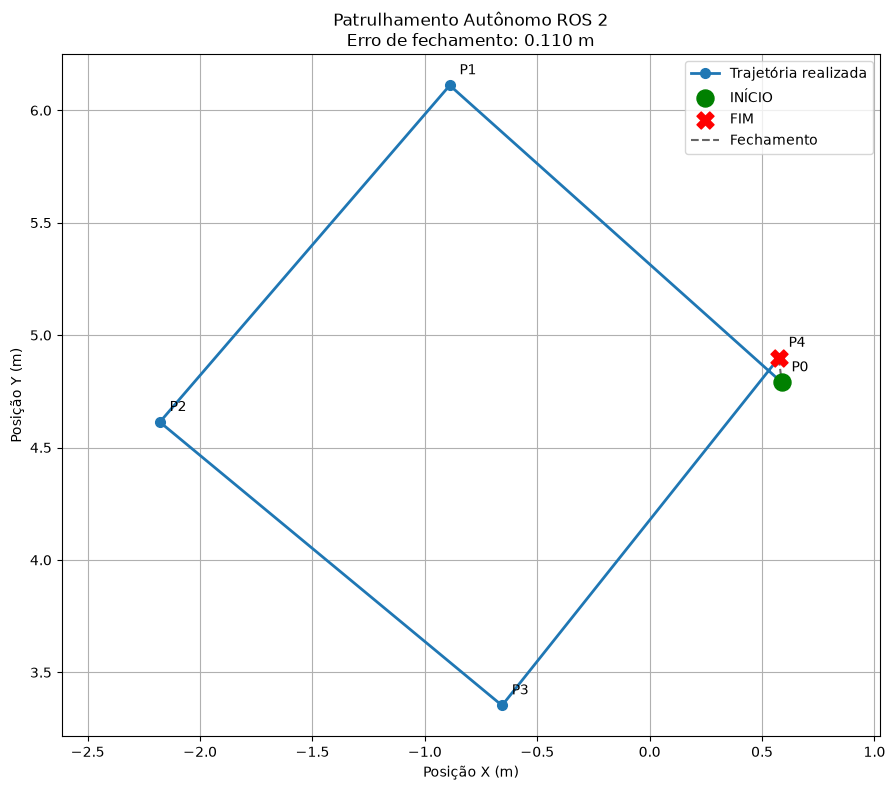

GRÁFICO GERADO COM SUCESSO
Início: X=0.588 | Y=4.790
Fim:    X=0.575 | Y=4.899
Erro de fechamento: 0.110 m
Arquivo salvo em: /home/ivan/ros2_ws/models/comparacao_trajetoria_patrol.png


In [7]:
# ============================================================
# GRÁFICO FINAL DA TRAJETÓRIA — PATRULHAMENTO AUTÔNOMO
# Executar depois da conclusão dos quatro lados
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

# Pasta de destino
PASTA = os.path.expanduser("~/ros2_ws/models")
os.makedirs(PASTA, exist_ok=True)

ARQUIVO = os.path.join(
    PASTA,
    "comparacao_trajetoria_patrol.png"
)

# Recuperar os vértices registrados pelo controlador
if "vertices" in globals():
    dados = vertices
elif "vertices_trajetoria" in globals():
    dados = vertices_trajetoria
else:
    # Última execução concluída — usar estes dados se
    # o notebook não manteve os vértices na memória.
    dados = [
        (0.588, 4.790),
        (-0.889, 6.111),
        (-2.179, 4.613),
        (-0.657, 3.352),
        (0.575, 4.899)
    ]

# Converter para matriz numérica
pontos = []

for p in dados:
    if isinstance(p, dict):
        pontos.append((float(p["x"]), float(p["y"])))
    else:
        pontos.append((float(p[0]), float(p[1])))

pontos = np.array(pontos)

if len(pontos) < 2:
    raise ValueError("Não existem pontos suficientes para gerar a trajetória.")

# Gerar gráfico
plt.figure(figsize=(9, 8))

plt.plot(
    pontos[:, 0],
    pontos[:, 1],
    marker="o",
    linewidth=2,
    markersize=7,
    label="Trajetória realizada"
)

# Marcar início e fim
plt.scatter(
    pontos[0, 0], pontos[0, 1],
    color="green", s=150, marker="o",
    label="INÍCIO", zorder=5
)

plt.scatter(
    pontos[-1, 0], pontos[-1, 1],
    color="red", s=150, marker="X",
    label="FIM", zorder=5
)

# Identificar os vértices
for i, (x, y) in enumerate(pontos):
    plt.annotate(
        f"P{i}",
        (x, y),
        xytext=(7, 8),
        textcoords="offset points"
    )

# Fechamento da trajetória
plt.plot(
    [pontos[-1, 0], pontos[0, 0]],
    [pontos[-1, 1], pontos[0, 1]],
    "k--",
    alpha=0.6,
    label="Fechamento"
)

erro_fechamento = np.linalg.norm(pontos[-1] - pontos[0])

plt.title(
    "Patrulhamento Autônomo ROS 2\n"
    f"Erro de fechamento: {erro_fechamento:.3f} m"
)

plt.xlabel("Posição X (m)")
plt.ylabel("Posição Y (m)")
plt.grid(True)
plt.axis("equal")
plt.legend()
plt.tight_layout()

# Salvar imagem
plt.savefig(ARQUIVO, dpi=180, bbox_inches="tight")
plt.show()

print("=" * 55)
print("GRÁFICO GERADO COM SUCESSO")
print("=" * 55)
print(f"Início: X={pontos[0,0]:.3f} | Y={pontos[0,1]:.3f}")
print(f"Fim:    X={pontos[-1,0]:.3f} | Y={pontos[-1,1]:.3f}")
print(f"Erro de fechamento: {erro_fechamento:.3f} m")
print(f"Arquivo salvo em: {ARQUIVO}")